## Variables to change

In [2]:
earth_engine_project_name = 'thrive-care' # used to initalize google earth engine project
basin_name = 'Tensift'                    # the basin you are running the analysis for


## Log into Google Earth Engine

In [3]:
# Install Earth Engine
!pip install -q geemap earthengine-api arcgis

from arcgis.features import FeatureLayer
import ee
import geemap

ee.Authenticate()  # You'll get a link to sign in with your Google account
ee.Initialize(project= earth_engine_project_name)


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 91.2/91.2 kB 3.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 58.6 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.2, but you have pandas 2.3.3 which is incompatible.


## Import

In [4]:
!pip install xarray dask[complete] geopandas rioxarray shapely zarr
import xarray as xr
import geopandas as gpd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## Get Tensift basin from arcgis



In [6]:
basin_url = "https://services3.arcgis.com/hjUMsSJ87zgoicvl/arcgis/rest/services/RessourcesEau_Maroc/FeatureServer/3"
layer = FeatureLayer(basin_url)
geojson = layer.query(out_sr=4326).to_geojson
basin_gdf = gpd.read_file(geojson)

# --- Load Oueds layer ---
oueds_url = "https://services3.arcgis.com/hjUMsSJ87zgoicvl/arcgis/rest/services/RessourcesEau_Maroc/FeatureServer/0"
oueds_layer = FeatureLayer(oueds_url)
oueds_geojson = oueds_layer.query(out_sr=4326).to_geojson
oueds_gdf = gpd.read_file(oueds_geojson)

# --- Load Nappes layer ---
nappes_url = "https://services3.arcgis.com/hjUMsSJ87zgoicvl/arcgis/rest/services/RessourcesEau_Maroc/FeatureServer/1"
nappes_layer = FeatureLayer(nappes_url)
nappes_geojson = nappes_layer.query(out_sr=4326).to_geojson
nappes_gdf = gpd.read_file(nappes_geojson)

# --- Clip to Basin ---
basin = basin_gdf[basin_gdf['NomBassin'] == basin_name]
oueds_basin = gpd.clip(oueds_gdf, basin)
aquifer_basin = gpd.clip(nappes_gdf, basin)
basin_geom = geemap.geopandas_to_ee(basin)

print("Basin imported from arcgis")

# ERA5 Analysis

In [ ]:
ds = xr.open_zarr(
    "gs://gcp-public-data-arco-era5/ar/full_37-1h-0p25deg-chunk-1.zarr",
    consolidated=True
)
ds_morocco = ds.sel(
    latitude=slice(36, 28),
    longitude=slice(-12, -6)
)

# clip to basin
ds_morocco.rio.clip(
    basin.geometry,
    basin.crs,
    drop=True
)

## idk

In [ ]:
# -------------------------------------------------------
# 1. Pour point (33°18'41.5"N 7°06'40.3"W)
# -------------------------------------------------------
lat = 33.31153
lon = -7.11119
pour_point = ee.Geometry.Point([lon, lat])

# -------------------------------------------------------
# 2. Import catchment and river geopackage
# -------------------------------------------------------
gpkg_path = "basin.gpkg"
basin_gdf = gpd.read_file(gpkg_path)
basin_ee = geemap.geopandas_to_ee(basin_gdf)
basin_geom = basin_ee.geometry()

river_gdf = gpd.read_file("rivers.gpkg")
river_ee = geemap.geopandas_to_ee(river_gdf)

# -------------------------------------------------------
# 3. Load SRTM DEM
# -------------------------------------------------------
dem = ee.Image('USGS/SRTMGL1_003').select('elevation')

# -------------------------------------------------------
# 4. Clip DEM to buffer
# -------------------------------------------------------
dem_clipped = dem.clip(basin_ee)


EEException: Earth Engine client library not initialized. See http://goo.gle/ee-auth.

# Pond Suitibility Analysis

In [ ]:
import ee
import geemap
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Initialize Earth Engine
# ee.Initialize()

print("="*80)
print("SITE-SPECIFIC POND SUITABILITY ANALYSIS")
print("="*80)

# ============================================================================
# CONFIGURATION: SET YOUR COORDINATES HERE
# ============================================================================

# Example coordinates (Tensift Basin) - CHANGE THESE TO YOUR LOCATION
TARGET_LAT = 33.31153  # Replace with your latitude
TARGET_LON = -7.11119  # Replace with your longitude

print(f"\n📍 Target Location: {TARGET_LAT}, {TARGET_LON}")

# Create analysis area geometry
target_point = ee.Geometry.Point([TARGET_LON, TARGET_LAT])
analysis_area = basin_geom

# ============================================================================
# HELPER FUNCTIONS
# ============================================================================

def create_map_with_legend(center_lat, center_lon, zoom=15):
    """Create a standardized map centered on target location"""
    m = geemap.Map(center=[center_lat, center_lon], zoom=zoom)
    m.add_basemap('HYBRID')
    return m

# ============================================================================
# TASK 1: DEM AND HYDROLOGICAL ANALYSIS
# ============================================================================

print("\n" + "="*80)
print("TASK 1: DEM PREPROCESSING & HYDROLOGICAL ANALYSIS")
print("="*80)

def load_and_process_dem(geometry):
    """Load SRTM DEM and derive hydrological parameters"""
    try:
        print("\nLoading SRTM 30m DEM...")
        buffer_dist = 300  # > largest focal radius (200 m)

        dem = ee.Image('USGS/SRTMGL1_003') \
                    .select('elevation') \
                    .clip(geometry.buffer(buffer_dist))

        print("Calculating slope and flow accumulation...")
        dem_filled = dem.focal_min(radius=90, units='meters').blend(dem)
        slope = ee.Terrain.slope(dem_filled)


        # Flow accumulation approximation
        flow_acc_approx = dem_filled.focal_min(radius=200, units='meters')
        flow_acc = dem_filled.subtract(flow_acc_approx).abs().multiply(50)

        # Final clip back to original geometry
        dem_filled = dem_filled.clip(geometry)
        slope = slope.clip(geometry)
        flow_acc = flow_acc.clip(geometry)


        # Load HydroRIVERS stream network
        print("Loading HydroRIVERS stream network...")
        try:
            hydrorivers = ee.FeatureCollection("WWF/HydroSHEDS/v1/FreeFlowingRivers")
            local_rivers = hydrorivers.filterBounds(geometry.buffer(5000))
            streams = ee.Image().byte().paint(local_rivers, 1, 50).selfMask()
            river_count = local_rivers.size().getInfo()
            print(f"  • Found {river_count} river segments nearby")
        except Exception as e:
            print(f"  ⚠️  Using DEM-based streams: {str(e)}")
            streams = flow_acc.gt(30).selfMask()

        print("✓ DEM preprocessing complete")

        return {
            'dem': dem,
            'dem_filled': dem_filled,
            'slope': slope,
            'flow_acc': flow_acc,
            'streams': streams
        }
    except Exception as e:
        print(f"❌ Error: {str(e)}")
        raise

dem_products = load_and_process_dem(analysis_area)


# Visualization
print("📊 Visualizing DEM products...")
Map1 = create_map_with_legend(TARGET_LAT, TARGET_LON, 15)
Map1.addLayer(analysis_area, {'color': 'yellow'}, 'Basin', True, 0.3)

elevation_vis = {
    'min': 100,
    'max': 1200,
    'palette': ['#000000', '#ffffff']
}

Map1.addLayer(
    dem_products['dem_filled'],
    elevation_vis,
    'Elevation (m)',
    True
)

Map1.add_colorbar(
    vis_params=elevation_vis,
    label='Elevation (m)',
    layer_name='Elevation (m)'
)


Map1.addLayer(dem_products['slope'],
              {'min': 0, 'max': 15, 'palette': ['#00ff00', '#ffff00', '#ff8800', '#ff0000']},
              'Slope (degrees)', True, 0.7)
Map1.add_colorbar(
    vis_params={'min': 0, 'max': 15, 'palette': ['#00ff00', '#ffff00', '#ff8800', '#ff0000']},
    label='Slope (degrees)',
    layer_name='Slope (degrees)'
)

Map1.addLayer(dem_products['streams'],
              {'palette': ['#0000ff']}, 'Stream Network', True)

# add flow_acc layer
Map1.addLayer(dem_products['flow_acc'],
              {'min': 0, 'max': 200, 'palette': ['#00ff00', '#ffff00', '#ff8800', '#ff0000']},
              'Flow Accumulation (m)', True, 0.7)
Map1.add_colorbar(
    vis_params={'min': 0, 'max': 200, 'palette': ['#00ff00', '#ffff00', '#ff8800', '#ff0000']},
    label='Flow Accumulation (m)',
    layer_name='Flow Accumulation (m)'
)

Map1.addLayer(target_point, {'color': 'red'}, 'Target Point', True)

display(Map1)

# ============================================================================
# TASK 2: VALLEY BOTTOMS & TOPOGRAPHY
# ============================================================================

print("\n" + "="*80)
print("TASK 2: VALLEY BOTTOM & DEPRESSION DETECTION")
print("="*80)

def extract_valley_bottoms(dem_products, geometry):
    """Identify valley bottoms and depressions"""
    try:
        print("\nIdentifying valley bottoms...")

        slope = dem_products['slope']
        flow_acc = dem_products['flow_acc']
        dem = dem_products['dem_filled']

        # Low slope areas (< 5 degrees)
        low_slope = slope.lt(5)

        # High flow accumulation
        high_flow = flow_acc.gt(30)

        # Topographic Position Index (valleys are negative)
        tpi = dem.subtract(dem.focal_mean(radius=150, units='meters'))
        valley_tpi = tpi.lt(-2)

        # Depressions (local minima)
        depression = dem.lt(dem.focal_min(radius=50, units='meters').add(1))

        # Combine criteria
        valley_bottom_mask = low_slope.And(high_flow.Or(valley_tpi)).Or(depression)
        valley_bottom_mask = valley_bottom_mask.focal_mode(radius=30, units='meters')

        print("✓ Valley bottom identification complete")

        return {
            'valley_bottom_mask': valley_bottom_mask,
            'low_slope': low_slope,
            'tpi': tpi,
            'depression': depression
        }
    except Exception as e:
        print(f"❌ Error: {str(e)}")
        raise

valley_data = extract_valley_bottoms(dem_products, analysis_area)

print("📊 Visualizing valley bottoms...")
Map2 = create_map_with_legend(TARGET_LAT, TARGET_LON, 15)
Map2.addLayer(target_point, {'color': 'red'}, 'Target Point', True)
Map2.addLayer(analysis_area, {'color': 'yellow'}, '500m Analysis Area', True, 0.3)
Map2.addLayer(valley_data['valley_bottom_mask'].selfMask(),
              {'palette': ['#00ff00']}, 'Valley Bottoms', True)
Map2.addLayer(valley_data['depression'].selfMask(),
              {'palette': ['#0000ff']}, 'Depressions', True, 0.7)
Map2.addLayer(valley_data['tpi'],
              {'min': -10, 'max': 10, 'palette': ['#0000ff', '#ffffff', '#ff0000']},
              'Topographic Position', False)
display(Map2)

# ============================================================================
# TASK 3: PRECIPITATION & RUNOFF
# ============================================================================

print("\n" + "="*80)
print("TASK 3: PRECIPITATION ANALYSIS")
print("="*80)

def analyze_precipitation_runoff(geometry):
    """Load CHIRPS precipitation"""
    try:
        print("\nLoading CHIRPS precipitation (2020-2024)...")

        chirps = ee.ImageCollection('UCSB-CHG/CHIRPS/DAILY') \
            .filterDate('2020-01-01', '2024-12-31') \
            .filterBounds(geometry)

        mean_annual_rain = chirps.select('precipitation').mean().multiply(365)
        runoff_potential = mean_annual_rain.multiply(0.3)

        print("✓ Precipitation analysis complete")

        return {
            'mean_annual_rain': mean_annual_rain,
            'runoff_potential': runoff_potential
        }
    except Exception as e:
        print(f"❌ Error: {str(e)}")
        raise

precip_data = analyze_precipitation_runoff(analysis_area)

# ============================================================================
# TASK 4: LANDCOVER & SOIL
# ============================================================================

print("\n" + "="*80)
print("TASK 4: LANDCOVER & SOIL ANALYSIS")
print("="*80)

def analyze_landcover_soil(geometry):
    """Load landcover and soil data"""
    try:
        print("\nLoading ESA WorldCover...")
        landcover = ee.ImageCollection('ESA/WorldCover/v200').first().select('Map').clip(geometry)

        # Suitable: Grass(30), Crop(40), Bare(60), Shrub(20)
        suitable_lc = landcover.eq(30).Or(landcover.eq(40)).Or(landcover.eq(60)).Or(landcover.eq(20))
        unsuitable_lc = landcover.eq(50).Or(landcover.eq(80))  # Built, Water
        landcover_mask = suitable_lc.And(unsuitable_lc.Not())

        print("Loading SoilGrids...")
        sand = ee.Image("projects/soilgrids-isric/sand_mean").select('sand_0-5cm_mean').clip(geometry)
        clay = ee.Image("projects/soilgrids-isric/clay_mean").select('clay_0-5cm_mean').clip(geometry)

        sand_pct = sand.divide(10)
        clay_pct = clay.divide(10)

        # Infiltration: 1=Low (clayey, good for ponds), 3=High (sandy, poor for ponds)
        high_infil = sand_pct.gt(60)
        low_infil = clay_pct.gt(40)
        medium_infil = high_infil.Not().And(low_infil.Not())

        soil_infil_class = low_infil.multiply(1).add(medium_infil.multiply(2)).add(high_infil.multiply(3))

        # Runoff coefficient (higher clay = more runoff = better water retention)
        runoff_coef = clay_pct.divide(100).clamp(0.2, 0.8)

        print("✓ Landcover and soil analysis complete")

        return {
            'landcover': landcover,
            'landcover_mask': landcover_mask,
            'sand_pct': sand_pct,
            'clay_pct': clay_pct,
            'soil_infil_class': soil_infil_class,
            'runoff_coef': runoff_coef
        }
    except Exception as e:
        print(f"❌ Error: {str(e)}")
        raise

soil_data = analyze_landcover_soil(analysis_area)

# Refine runoff with soil data
precip_data['runoff_potential'] = precip_data['mean_annual_rain'].multiply(soil_data['runoff_coef'])

print("📊 Visualizing soil properties...")
Map3 = create_map_with_legend(TARGET_LAT, TARGET_LON, 15)
Map3.addLayer(target_point, {'color': 'red'}, 'Target Point', True)
Map3.addLayer(analysis_area, {'color': 'yellow'}, '500m Analysis Area', True, 0.3)
Map3.addLayer(soil_data['soil_infil_class'],
              {'min': 1, 'max': 3, 'palette': ['#00ff00', '#ffff00', '#ff0000']},
              'Soil Infiltration (1=Low/Good)', True)
Map3.addLayer(soil_data['clay_pct'],
              {'min': 0, 'max': 60, 'palette': ['#ffffcc', '#ffeda0', '#feb24c', '#f03b20', '#bd0026']},
              'Clay Content (%)', True, 0.7)
display(Map3)

# ============================================================================
# TASK 5: INUNDATION FREQUENCY
# ============================================================================

print("\n" + "="*80)
print("TASK 5: FLOOD/INUNDATION FREQUENCY")
print("="*80)

def compute_inundation_frequency(geometry):
    """Analyze inundation patterns"""
    try:
        print("\nLoading Sentinel-1 (2022-2024)...")

        s1 = ee.ImageCollection('COPERNICUS/S1_GRD') \
            .filterBounds(geometry) \
            .filterDate('2022-01-01', '2024-12-31') \
            .filter(ee.Filter.listContains('transmitterReceiverPolarisation', 'VV')) \
            .filter(ee.Filter.eq('instrumentMode', 'IW')) \
            .select('VV')

        def detect_water(image):
            filtered = image.focal_median(30, 'circle', 'meters')
            water = filtered.lt(-16).rename('water')
            return water

        s1_water = s1.map(detect_water)

        total_obs = s1_water.count()
        water_sum = s1_water.sum()
        inundation_frequency = water_sum.divide(total_obs).multiply(100)

        print("✓ Inundation analysis complete")

        return {
            'inundation_frequency': inundation_frequency
        }
    except Exception as e:
        print(f"❌ Error: {str(e)}")
        raise

inundation_data = compute_inundation_frequency(analysis_area)

# ============================================================================
# TASK 6: DISTANCE TO WATER SOURCES
# ============================================================================

print("\n" + "="*80)
print("TASK 6: DISTANCE TO WATER SOURCES")
print("="*80)

def calculate_distance_to_streams(streams, geometry):
    """Calculate distance to nearest stream"""
    try:
        print("\nCalculating distance to streams...")
        distance = streams.fastDistanceTransform().sqrt() \
                         .multiply(ee.Image.pixelArea().sqrt())

        # Proximity score (closer = better, max 500m)
        proximity_score = distance.multiply(-1).add(500).divide(500).clamp(0, 1)

        print("✓ Distance calculation complete")

        return {
            'distance_to_stream': distance,
            'proximity_score': proximity_score
        }
    except Exception as e:
        print(f"❌ Error: {str(e)}")
        raise

distance_data = calculate_distance_to_streams(dem_products['streams'], analysis_area)

# ============================================================================
# TASK 7: SUITABILITY ANALYSIS
# ============================================================================

print("\n" + "="*80)
print("TASK 7: POND SUITABILITY SCORING")
print("="*80)

def compute_pond_suitability(valley_data, precip_data, soil_data, inundation_data, distance_data):
    """Combine layers into suitability score"""
    try:
        print("\nComputing suitability scores...")

        # Normalize inputs to 0-1 (1 = best for ponds)
        valley_score = valley_data['valley_bottom_mask'].unmask(0).float()
        depression_score = valley_data['depression'].unmask(0).float()

        # Lower infiltration = better water retention (invert the scale)
        soil_score = soil_data['soil_infil_class'].multiply(-1).add(4).divide(2).clamp(0, 1)

        # Higher runoff = more water available
        runoff_score = precip_data['runoff_potential'].unitScale(0, 200).clamp(0, 1)

        # Ideal inundation: 5-20% (seasonal water, not permanent)
        inund = inundation_data['inundation_frequency']
        inund_ideal = ee.Image(12.5)
        inund_score = inund.subtract(inund_ideal).abs().multiply(-1).add(12.5).divide(12.5).clamp(0, 1)

        # Landcover suitability
        lc_score = soil_data['landcover_mask'].unmask(0).float()

        # Gentle slope is better
        slope_score = valley_data['low_slope'].unmask(0).float()

        # Proximity to streams
        proximity_score = distance_data['proximity_score']

        # Weighted MCDA (Multi-Criteria Decision Analysis)
        suitability = valley_score.multiply(0.20) \
            .add(depression_score.multiply(0.15)) \
            .add(soil_score.multiply(0.15)) \
            .add(runoff_score.multiply(0.15)) \
            .add(inund_score.multiply(0.10)) \
            .add(lc_score.multiply(0.10)) \
            .add(slope_score.multiply(0.05)) \
            .add(proximity_score.multiply(0.10))

        suitability = suitability.clamp(0, 1).rename('suitability')

        print("✓ Suitability analysis complete")

        return {'suitability': suitability}
    except Exception as e:
        print(f"❌ Error: {str(e)}")
        raise

suitability_data = compute_pond_suitability(valley_data, precip_data, soil_data,
                                            inundation_data, distance_data)

print("📊 Visualizing final suitability...")
Map4 = create_map_with_legend(TARGET_LAT, TARGET_LON, 15)
Map4.addLayer(target_point, {'color': 'red'}, 'Target Point', True)
Map4.addLayer(analysis_area, {'color': 'yellow'}, '500m Analysis Area', True, 0.3)
Map4.addLayer(dem_products['streams'],
              {'palette': ['#0000ff']}, 'Streams', True)
Map4.addLayer(suitability_data['suitability'],
              {'min': 0, 'max': 1, 'palette': ['#d73027', '#fc8d59', '#fee08b', '#d9ef8b', '#91cf60', '#1a9850']},
              'Pond Suitability Score', True)

# Highlight best locations (suitability > 0.6)
best_sites = suitability_data['suitability'].gte(0.6).selfMask()
Map4.addLayer(best_sites, {'palette': ['#00ff00']}, '★ Best Locations (>0.6)', True)

Map4.add_colorbar(
    vis_params={'min': 0, 'max': 1, 'palette': ['#d73027', '#fc8d59', '#fee08b', '#d9ef8b', '#91cf60', '#1a9850']},
    label='Suitability (0=Poor, 1=Excellent)',
    layer_name='Pond Suitability Score'
)
display(Map4)

# ============================================================================
# TASK 8: EXTRACT STATISTICS
# ============================================================================

print("\n" + "="*80)
print("TASK 8: EXTRACTING SITE STATISTICS")
print("="*80)

def extract_site_statistics(suitability_data, dem_products, soil_data, analysis_area):
    """Extract key statistics for the analysis area"""
    try:
        print("\nCalculating statistics...")

        # Sample statistics
        combined = suitability_data['suitability'] \
            .addBands(dem_products['dem_filled'].rename('elevation')) \
            .addBands(dem_products['slope'].rename('slope')) \
            .addBands(soil_data['clay_pct'].rename('clay_pct')) \
            .addBands(distance_data['distance_to_stream'].rename('dist_stream'))

        stats = combined.reduceRegion(
            reducer=ee.Reducer.mean().combine(
                ee.Reducer.minMax(), '', True
            ).combine(
                ee.Reducer.stdDev(), '', True
            ),
            geometry=analysis_area,
            scale=30,
            maxPixels=1e9
        )

        stats_dict = stats.getInfo()

        # Find best location
        best_location = suitability_data['suitability'].reduceRegion(
            reducer=ee.Reducer.max(),
            geometry=analysis_area,
            scale=30
        ).getInfo()

        print("✓ Statistics extraction complete")

        return stats_dict, best_location
    except Exception as e:
        print(f"❌ Error: {str(e)}")
        raise

stats_dict, best_location = extract_site_statistics(suitability_data, dem_products,
                                                     soil_data, analysis_area)

# ============================================================================
# FINAL SUMMARY
# ============================================================================

print("\n" + "="*80)
print("ANALYSIS SUMMARY")
print("="*80)
print(f"\n📍 Location: {TARGET_LAT}, {TARGET_LON}")
print(f"\n📊 SUITABILITY RESULTS:")
print(f"  • Best Suitability Score: {best_location.get('suitability', 0):.3f}")
print(f"  • Average Suitability: {stats_dict.get('suitability_mean', 0):.3f}")
print(f"\n🏔️  TOPOGRAPHY:")
print(f"  • Average Elevation: {stats_dict.get('elevation_mean', 0):.1f}m")
print(f"  • Elevation Range: {stats_dict.get('elevation_min', 0):.1f} - {stats_dict.get('elevation_max', 0):.1f}m")
print(f"  • Average Slope: {stats_dict.get('slope_mean', 0):.1f}°")
print(f"\n💧 WATER SOURCES:")
print(f"  • Average Distance to Stream: {stats_dict.get('dist_stream_mean', 0):.0f}m")
print(f"  • Minimum Distance to Stream: {stats_dict.get('dist_stream_min', 0):.0f}m")
print(f"\n🌱 SOIL:")
print(f"  • Average Clay Content: {stats_dict.get('clay_pct_mean', 0):.1f}%")

print("\n💡 INTERPRETATION:")
if best_location.get('suitability', 0) > 0.7:
    print("  ✓ EXCELLENT - This location is highly suitable for pond construction")
elif best_location.get('suitability', 0) > 0.5:
    print("  ✓ GOOD - This location has good potential for pond construction")
elif best_location.get('suitability', 0) > 0.3:
    print("  ⚠️  MODERATE - Consider alternative locations or site modifications")
else:
    print("  ❌ POOR - This location is not recommended for pond construction")

print("\n✅ ANALYSIS COMPLETE")
print("="*80)

## Combination of Satellites

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from datetime import datetime
import ee

# --- MODIS NDVI (16-day) ---
def get_modis_ndvi_timeseries(start_date, end_date, geometry):
    """
    Get NDVI timeseries from MODIS MOD13Q1 (16-day, 250m resolution)
    Returns data at actual 16-day intervals
    """
    collection = ee.ImageCollection('MODIS/061/MOD13Q1') \
        .filterDate(start_date, end_date) \
        .select('NDVI') \
        .filterBounds(geometry)

    def scale_and_extract(image):
        # Scale NDVI from 0-10000 to 0-1
        scaled = image.multiply(0.0001)

        # Get mean value for the region
        stats = scaled.reduceRegion(
            reducer=ee.Reducer.mean(),
            geometry=geometry,
            scale=250,
            maxPixels=1e13
        )

        return ee.Feature(None, {
            'date': image.date().format('YYYY-MM-dd'),
            'ndvi': stats.get('NDVI'),
            'timestamp': image.date().millis()
        })

    features = collection.map(scale_and_extract)
    feature_list = features.getInfo()['features']

    results = []
    for feat in feature_list:
        props = feat['properties']
        if props['ndvi'] is not None:
            results.append({
                'date': props['date'],
                'modis_ndvi': props['ndvi']
            })

    return pd.DataFrame(results)


# --- Sentinel-2 NDVI (OPTIMIZED) ---
def get_sentinel2_ndvi_timeseries(start_date, end_date, geometry):
    """
    Get NDVI timeseries from Sentinel-2 (10m resolution, ~5-day revisit)
    OPTIMIZED: Uses monthly composites to reduce API calls
    """
    # Option 1: Monthly composites (more stable, fewer API calls)
    def get_monthly_composite(year, month):
        start = ee.Date.fromYMD(year, month, 1)
        end = start.advance(1, 'month')

        s2 = ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED') \
            .filterBounds(geometry) \
            .filterDate(start, end) \
            .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 20))

        # Calculate NDVI for each image
        def calc_ndvi(image):
            return image.normalizedDifference(['B8', 'B4']).rename('NDVI')

        ndvi_collection = s2.map(calc_ndvi)

        # Get median NDVI for the month
        monthly_ndvi = ndvi_collection.median()

        # Get mean value for the region
        stats = monthly_ndvi.reduceRegion(
            reducer=ee.Reducer.mean(),
            geometry=geometry,
            scale=10,
            maxPixels=1e13
        )

        return {
            'date': start.format('YYYY-MM-dd').getInfo(),
            's2_ndvi': stats.get('NDVI').getInfo()
        }

    # Generate monthly data
    results = []
    start_year = int(start_date.split('-')[0])
    end_year = int(end_date.split('-')[0])

    for year in range(start_year, end_year + 1):
        for month in range(1, 13):
            # Skip months outside date range
            date_str = f"{year}-{month:02d}-01"
            if date_str < start_date[:10] or date_str > end_date[:10]:
                continue

            print(f"  Processing {year}-{month:02d}...")
            try:
                result = get_monthly_composite(year, month)
                if result['s2_ndvi'] is not None:
                    results.append(result)
            except Exception as e:
                print(f"    Error for {year}-{month:02d}: {e}")

    return pd.DataFrame(results)


# --- ALTERNATIVE: Sentinel-2 with sampling (if you want higher frequency) ---
def get_sentinel2_ndvi_sampled(start_date, end_date, geometry, sample_every_n=3):
    """
    Get Sentinel-2 NDVI by sampling every Nth image
    Use this if you want more frequent data than monthly
    """
    s2 = ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED') \
        .filterBounds(geometry) \
        .filterDate(start_date, end_date) \
        .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 20))

    # Get the size of collection
    count = s2.size().getInfo()
    print(f"  Total Sentinel-2 images: {count}, sampling every {sample_every_n}")

    # Convert to list and sample
    img_list = s2.toList(count)

    results = []
    for i in range(0, count, sample_every_n):
        print(f"  Processing image {i+1}/{count}...")
        try:
            image = ee.Image(img_list.get(i))

            # Calculate NDVI
            ndvi = image.normalizedDifference(['B8', 'B4']).rename('NDVI')

            # Get mean value for the region
            stats = ndvi.reduceRegion(
                reducer=ee.Reducer.mean(),
                geometry=geometry,
                scale=10,
                maxPixels=1e13
            )

            date = image.date().format('YYYY-MM-dd').getInfo()
            ndvi_value = stats.get('NDVI').getInfo()

            if ndvi_value is not None:
                results.append({
                    'date': date,
                    's2_ndvi': ndvi_value
                })
        except Exception as e:
            print(f"    Error at index {i}: {e}")
            continue

    return pd.DataFrame(results)


# --- SAR Soil Moisture ---
def get_sar_timeseries(start_date, end_date, geometry):
    """
    Get SAR backscatter from Sentinel-1 using VV and VH polarizations
    """
    sentinel1 = ee.ImageCollection('COPERNICUS/S1_GRD') \
        .filterBounds(geometry) \
        .filterDate(start_date, end_date) \
        .filter(ee.Filter.listContains('transmitterReceiverPolarisation', 'VV')) \
        .filter(ee.Filter.listContains('transmitterReceiverPolarisation', 'VH')) \
        .filter(ee.Filter.eq('instrumentMode', 'IW')) \
        .select(['VV', 'VH'])

    def extract_backscatter(image):
        # Get mean values for the region
        stats = image.reduceRegion(
            reducer=ee.Reducer.mean(),
            geometry=geometry,
            scale=10,
            maxPixels=1e13
        )

        return ee.Feature(None, {
            'date': image.date().format('YYYY-MM-dd'),
            'vv': stats.get('VV'),
            'vh': stats.get('VH'),
            'timestamp': image.date().millis()
        })

    features = sentinel1.map(extract_backscatter)
    feature_list = features.getInfo()['features']

    results = []
    for feat in feature_list:
        props = feat['properties']
        if props['vv'] is not None and props['vh'] is not None:
            # Calculate VV/VH ratio as soil moisture indicator
            results.append({
                'date': props['date'],
                'vv': props['vv'],
                'vh': props['vh'],
                'vv_vh_ratio': props['vv'] - props['vh']  # In dB, so subtraction = ratio
            })

    return pd.DataFrame(results)


# --- GRACE Water Storage ---
def get_grace_timeseries(start_date, end_date, geometry):
    """
    Get terrestrial water storage from GRACE (monthly)
    """
    collection = ee.ImageCollection('NASA/GRACE/MASS_GRIDS/MASCON_CRI') \
        .filterDate(start_date, end_date) \
        .select('lwe_thickness')

    def extract_storage(image):
        stats = image.reduceRegion(
            reducer=ee.Reducer.mean(),
            geometry=geometry,
            scale=25000,
            maxPixels=1e13
        )

        return ee.Feature(None, {
            'date': image.date().format('YYYY-MM-dd'),
            'water_storage': stats.get('lwe_thickness'),
            'timestamp': image.date().millis()
        })

    features = collection.map(extract_storage)
    feature_list = features.getInfo()['features']

    results = []
    for feat in feature_list:
        props = feat['properties']
        if props['water_storage'] is not None:
            results.append({
                'date': props['date'],
                'grace_storage': props['water_storage']
            })

    return pd.DataFrame(results)


# --- MAIN EXECUTION ---
# Define your parameters
start_date = '2015-01-01'
end_date = '2025-01-21'  # Current date

# Use tensift_geom (assumes it's already defined in your notebook)
# tensift_geom should be defined earlier in your code

print("Collecting multi-sensor timeseries data...")

# Collect all datasets
print("- MODIS NDVI (16-day)...")
modis_df = get_modis_ndvi_timeseries(start_date, end_date, basin_geom)
modis_df['date'] = pd.to_datetime(modis_df['date'])

print("- Sentinel-2 NDVI (monthly composites)...")
# Option 1: Monthly composites (RECOMMENDED - much faster)
s2_df = get_sentinel2_ndvi_timeseries(start_date, end_date, basin_geom)

# Option 2: Sampled every 3rd image (ALTERNATIVE - if you want more frequent data)
# s2_df = get_sentinel2_ndvi_sampled(start_date, end_date, tensift_geom, sample_every_n=3)

s2_df['date'] = pd.to_datetime(s2_df['date'])

print("- Sentinel-1 SAR (VV & VH)...")
sar_df = get_sar_timeseries(start_date, end_date, basin_geom)
sar_df['date'] = pd.to_datetime(sar_df['date'])

print("- GRACE (monthly)...")
grace_df = get_grace_timeseries(start_date, end_date, basin_geom)
grace_df['date'] = pd.to_datetime(grace_df['date'])

print(f"\nData collection complete:")
print(f"  - MODIS NDVI points: {len(modis_df)}")
print(f"  - Sentinel-2 NDVI points: {len(s2_df)}")
print(f"  - SAR points: {len(sar_df)}")
print(f"  - GRACE points: {len(grace_df)}")

# --- VISUALIZATION: Simple 3-panel ---
fig, axes = plt.subplots(3, 1, figsize=(16, 10), sharex=True)

# Plot 1: Both NDVI sources
axes[0].plot(modis_df['date'], modis_df['modis_ndvi'], 'o-',
             color='darkgreen', markersize=3, linewidth=1.2, alpha=0.8, label='MODIS (16-day, 250m)')
axes[0].plot(s2_df['date'], s2_df['s2_ndvi'], 's-',
             color='limegreen', markersize=4, linewidth=1, alpha=0.7, label='Sentinel-2 (monthly, 10m)')
axes[0].set_ylabel('NDVI', fontsize=12, fontweight='bold')
axes[0].set_title('Multi-Sensor Vegetation, Soil Moisture, and Water Storage Analysis - Tensift Basin',
                  fontsize=14, fontweight='bold', pad=15)
axes[0].grid(alpha=0.3)
axes[0].legend(loc='best', fontsize=10, framealpha=0.9)

# Plot 2: SAR soil moisture proxy
axes[1].plot(sar_df['date'], sar_df['vv_vh_ratio'], 'o-',
             color='steelblue', markersize=2, linewidth=1, alpha=0.7, label='Sentinel-1 VV/VH')
axes[1].set_ylabel('Soil Moisture Proxy\n(VV/VH Ratio, dB)', fontsize=12, fontweight='bold')
axes[1].grid(alpha=0.3)
axes[1].legend(loc='best', fontsize=10, framealpha=0.9)

# Plot 3: GRACE water storage
axes[2].plot(grace_df['date'], grace_df['grace_storage'], 'o-',
             color='darkorange', markersize=4, linewidth=1.8, alpha=0.9, label='GRACE')
axes[2].set_ylabel('Terrestrial Water\nStorage (cm)', fontsize=12, fontweight='bold')
axes[2].set_xlabel('Date', fontsize=12, fontweight='bold')
axes[2].grid(alpha=0.3)
axes[2].legend(loc='best', fontsize=10, framealpha=0.9)

# Format x-axis
axes[2].xaxis.set_major_locator(mdates.YearLocator())
axes[2].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
axes[2].xaxis.set_minor_locator(mdates.MonthLocator((1, 7)))

plt.tight_layout()
plt.savefig('tensift_multisensor_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

# --- NORMALIZED COMPARISON ---
fig, ax = plt.subplots(figsize=(16, 7))

from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()

if len(modis_df) > 0:
    modis_norm = scaler.fit_transform(modis_df[['modis_ndvi']].dropna())
    ax.plot(modis_df['date'], modis_norm, 'o-', color='darkgreen',
            markersize=3, linewidth=1.2, alpha=0.8, label='MODIS NDVI')

if len(s2_df) > 0:
    s2_norm = scaler.fit_transform(s2_df[['s2_ndvi']].dropna())
    ax.plot(s2_df['date'], s2_norm, 's-', color='limegreen',
            markersize=4, linewidth=1, alpha=0.7, label='Sentinel-2 NDVI')

if len(sar_df) > 0:
    vv_norm = scaler.fit_transform(sar_df[['vv_vh_ratio']].dropna())
    ax.plot(sar_df['date'], vv_norm, 'o-', color='steelblue',
            markersize=2, linewidth=0.8, alpha=0.6, label='SAR VV/VH')

if len(grace_df) > 0:
    grace_norm = scaler.fit_transform(grace_df[['grace_storage']].dropna())
    ax.plot(grace_df['date'], grace_norm, 'o-', color='darkorange',
            markersize=4, linewidth=1.8, alpha=0.9, label='GRACE')

ax.set_xlabel('Date', fontsize=12, fontweight='bold')
ax.set_ylabel('Normalized Value (0-1)', fontsize=12, fontweight='bold')
ax.set_title('Normalized Multi-Sensor Comparison - Tensift Basin',
             fontsize=14, fontweight='bold', pad=15)
ax.legend(loc='best', fontsize=10)
ax.grid(alpha=0.3, linestyle='--')
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
ax.set_ylim([-0.05, 1.05])

plt.tight_layout()
plt.savefig('tensift_normalized_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

# --- Save all data to CSV ---
modis_df.to_csv('tensift_modis_ndvi_timeseries.csv', index=False)
s2_df.to_csv('tensift_sentinel2_ndvi_timeseries.csv', index=False)
sar_df.to_csv('tensift_sar_timeseries.csv', index=False)
grace_df.to_csv('tensift_grace_timeseries.csv', index=False)

print("\n✓ All timeseries data saved to CSV files")
print(f"  - tensift_modis_ndvi_timeseries.csv ({len(modis_df)} records)")
print(f"  - tensift_sentinel2_ndvi_timeseries.csv ({len(s2_df)} records)")
print(f"  - tensift_sar_timeseries.csv ({len(sar_df)} records)")
print(f"  - tensift_grace_timeseries.csv ({len(grace_df)} records)")

- MODIS NDVI (16-day)...
- Sentinel-2 NDVI (monthly composites)...
  Processing 2015-01...
    Error for 2015-01: Dictionary.get: Dictionary does not contain key: 'NDVI'.
  Processing 2015-02...
    Error for 2015-02: Dictionary.get: Dictionary does not contain key: 'NDVI'.
  Processing 2015-03...
    Error for 2015-03: Dictionary.get: Dictionary does not contain key: 'NDVI'.
  Processing 2015-04...
    Error for 2015-04: Dictionary.get: Dictionary does not contain key: 'NDVI'.
  Processing 2015-05...
    Error for 2015-05: Dictionary.get: Dictionary does not contain key: 'NDVI'.
  Processing 2015-06...
    Error for 2015-06: Dictionary.get: Dictionary does not contain key: 'NDVI'.
  Processing 2015-07...
  Processing 2015-08...
  Processing 2015-09...
    Error for 2015-09: Dictionary.get: Dictionary does not contain key: 'NDVI'.
  Processing 2015-10...
    Error for 2015-10: Dictionary.get: Dictionary does not contain key: 'NDVI'.
  Processing 2015-11...
    Error for 2015-11: Dictio

  Processing 2019-02...
  Processing 2019-03...
  Processing 2019-04...
  Processing 2019-05...
  Processing 2019-06...
  Processing 2019-07...
  Processing 2019-08...
  Processing 2019-09...
  Processing 2019-10...
  Processing 2019-11...
  Processing 2019-12...
  Processing 2020-01...
  Processing 2020-02...
  Processing 2020-03...
  Processing 2020-04...
  Processing 2020-05...
  Processing 2020-06...
  Processing 2020-07...
  Processing 2020-08...
  Processing 2020-09...
  Processing 2020-10...
  Processing 2020-11...
  Processing 2020-12...
  Processing 2021-01...
  Processing 2021-02...
  Processing 2021-03...
  Processing 2021-04...
  Processing 2021-05...
  Processing 2021-06...
  Processing 2021-07...
  Processing 2021-08...
  Processing 2021-09...
  Processing 2021-10...
  Processing 2021-11...
  Processing 2021-12...
  Processing 2022-01...
  Processing 2022-02...
  Processing 2022-03...
  Processing 2022-04...
  Processing 2022-05...


  Processing 2022-06...
  Processing 2022-07...
  Processing 2022-08...
  Processing 2022-09...
  Processing 2022-10...
  Processing 2022-11...
  Processing 2022-12...
  Processing 2023-01...
  Processing 2023-02...
  Processing 2023-03...
  Processing 2023-04...
  Processing 2023-05...
  Processing 2023-06...
  Processing 2023-07...
  Processing 2023-08...
  Processing 2023-09...
  Processing 2023-10...
  Processing 2023-11...
  Processing 2023-12...
  Processing 2024-01...
  Processing 2024-02...
  Processing 2024-03...
  Processing 2024-04...
  Processing 2024-05...


  Processing 2024-06...
  Processing 2024-07...
  Processing 2024-08...
  Processing 2024-09...
  Processing 2024-10...
  Processing 2024-11...
  Processing 2024-12...
  Processing 2025-01...
- Sentinel-1 SAR (VV & VH)...


EEException: Computation timed out.

## GRACE

GRACE GROUNDWATER ANALYSIS - TENSIFT BASIN

Loading GRACE satellite data...

Loaded GRACE data from 2002-04-01 to 2023-12-31


/usr/local/lib/python3.12/dist-packages/ee/deprecation.py:207: DeprecationWarning: 

Attention required for NASA/GRACE/MASS_GRIDS/LAND! You are using a deprecated asset.
To make sure your code keeps working, please update it.
Learn more: https://developers.google.com/earth-engine/datasets/catalog/NASA_GRACE_MASS_GRIDS_LAND

  warnings.warn(warning, category=DeprecationWarning)


Total images: 159

Extracting groundwater storage anomalies...

Extracted 159 valid measurements

GROUNDWATER STORAGE STATISTICS

Date Range: 2002-04-01 to 2017-01-07
Number of Measurements: 159

Water Storage Anomaly Statistics (cm):
  Mean:       0.07 cm
  Minimum:   -3.34 cm (on 2016-12-11)
  Maximum:    6.76 cm (on 2015-02-01)
  Std Dev:    1.70 cm

Trend Analysis:
  Linear Trend: -0.063 cm/year
  Total Change: -0.93 cm over 14.8 years
  R² Value:     0.0239
  Std Error:    1.681

  ⚠️  GROUNDWATER DEPLETION DETECTED: 0.063 cm/year loss


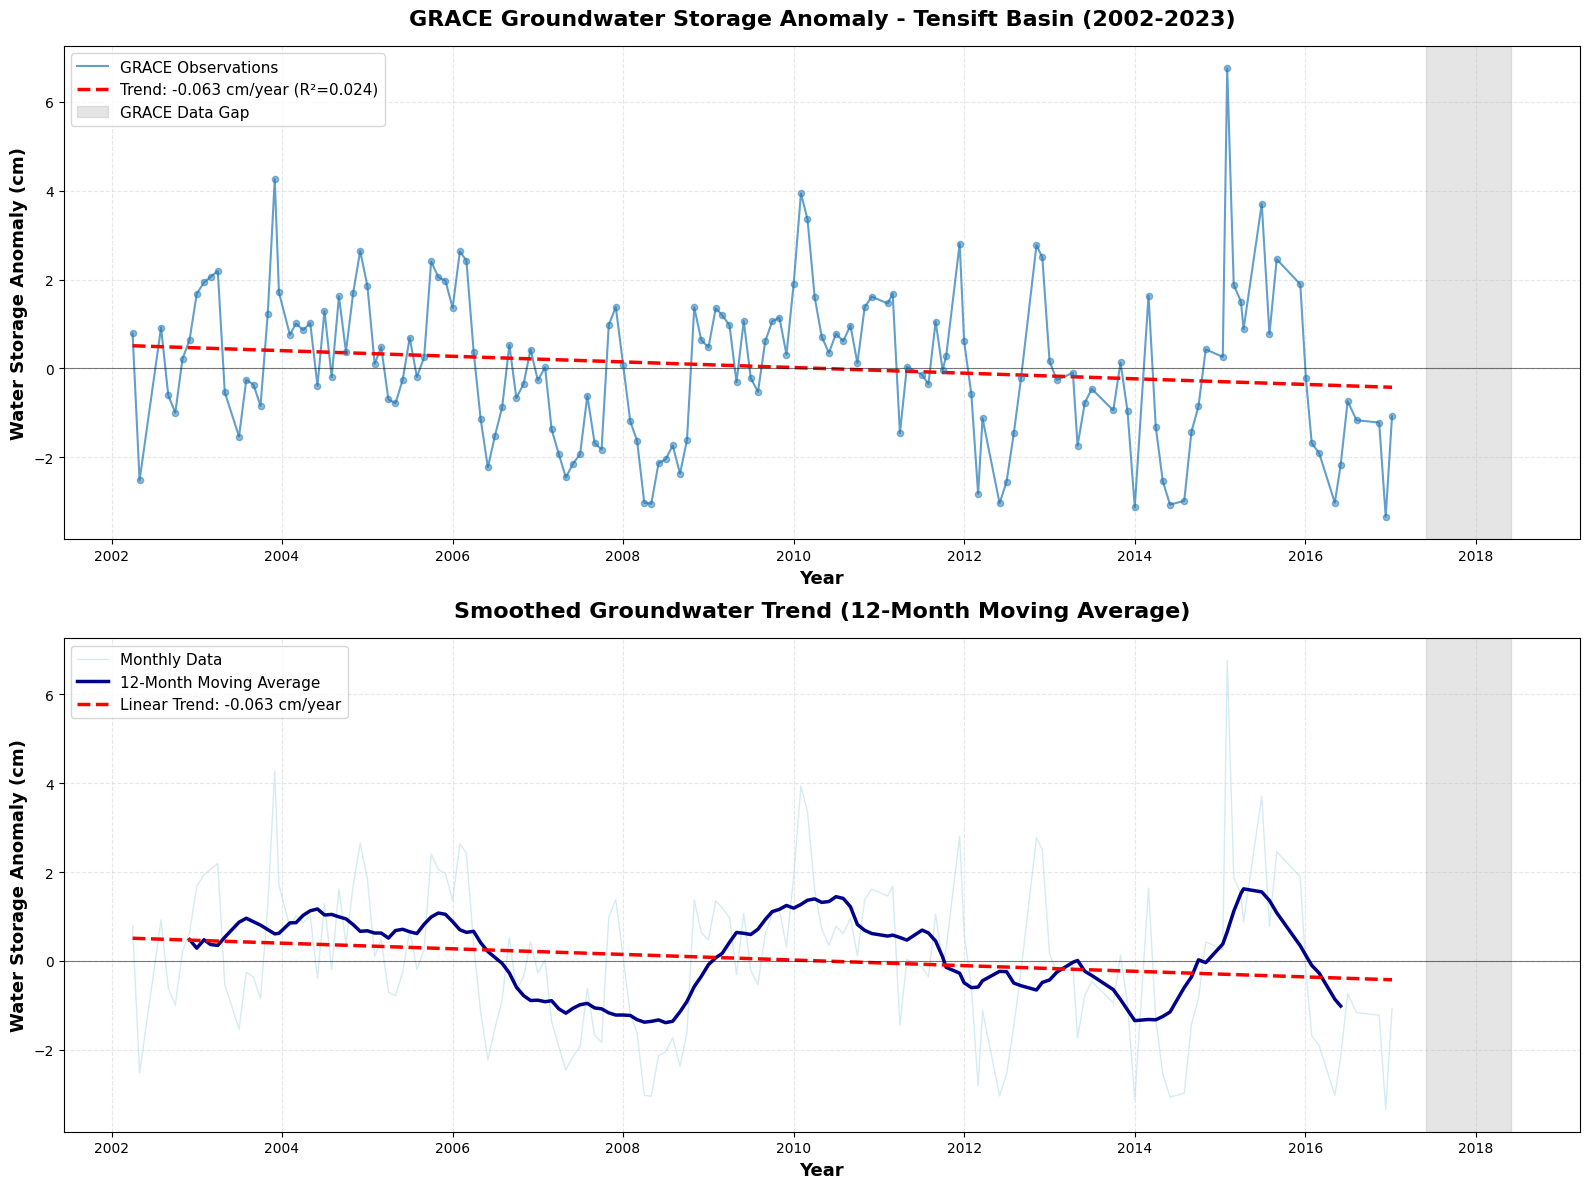

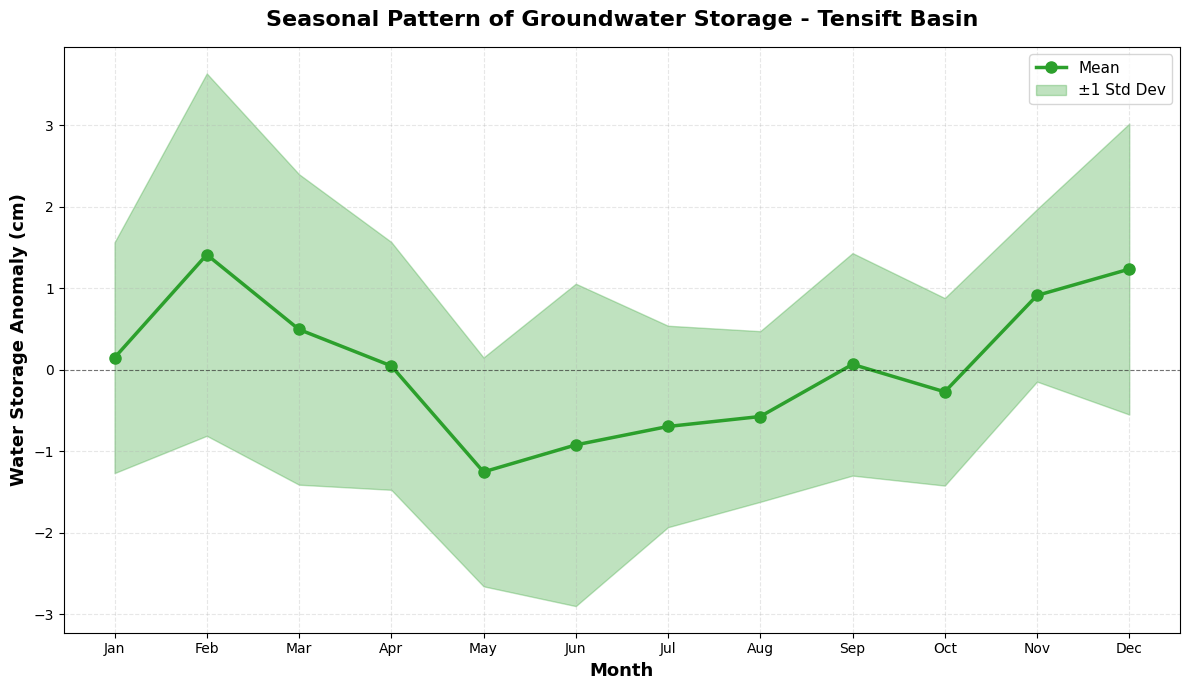

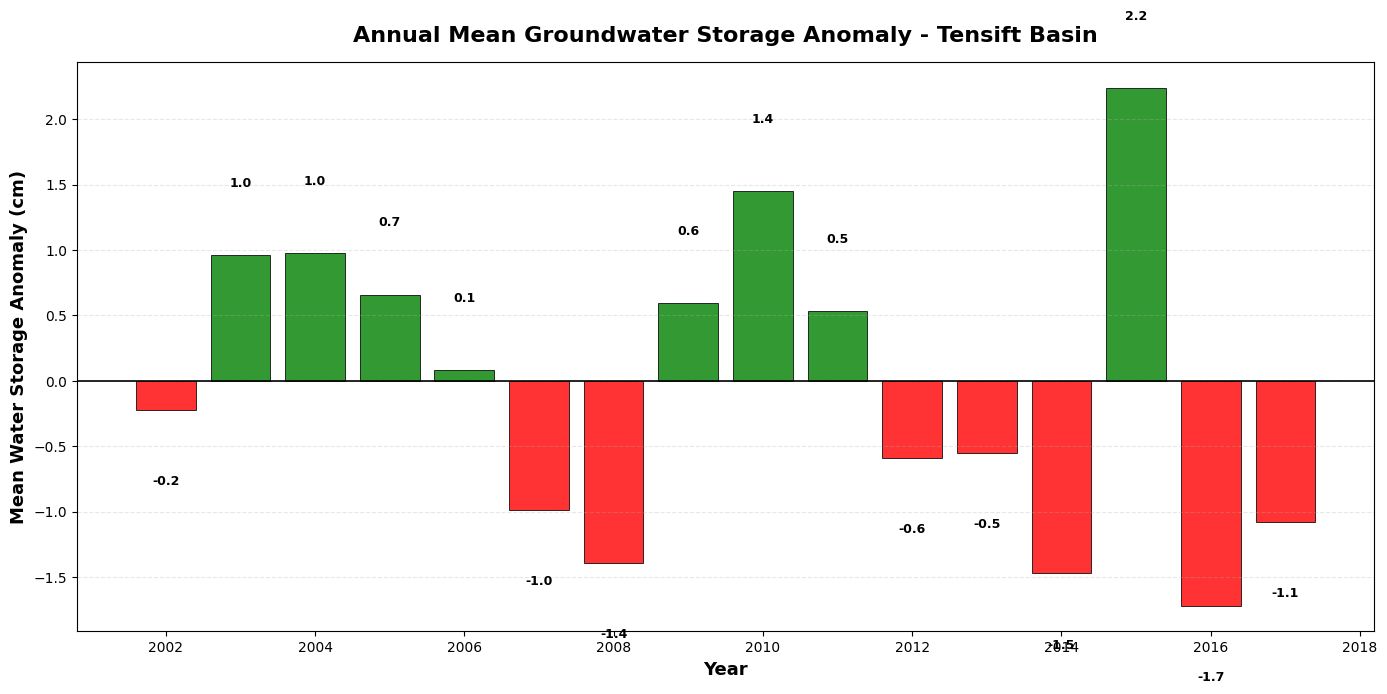


Creating interactive GRACE map...


Map(center=[31.530532507751857, -8.565848432724456], controls=(WidgetControl(options=['position', 'transparent…


FILES SAVED:
✓ tensift_grace_groundwater_data.csv - Full time series data
✓ tensift_grace_yearly_statistics.csv - Annual statistics
✓ tensift_grace_groundwater_timeseries.png - Time series plots
✓ tensift_grace_seasonal_pattern.png - Seasonal analysis
✓ tensift_grace_yearly_comparison.png - Annual comparison

ANALYSIS COMPLETE


In [ ]:
import ee
import geemap
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Initialize Earth Engine (if not already done)
# ee.Initialize()

print("="*80)
print("GRACE GROUNDWATER ANALYSIS - TENSIFT BASIN")
print("="*80)

# --- 1. Load GRACE Data ---

def load_grace_data(geometry, start_date='2002-04-01', end_date='2023-12-31'):
    """
    Load GRACE/GRACE-FO Total Water Storage Anomaly data
    Note: GRACE data has a gap from mid-2017 to mid-2018 (GRACE-FO launch)
    """

    # GRACE Monthly Mass Grids - Land
    grace = ee.ImageCollection('NASA/GRACE/MASS_GRIDS/LAND') \
        .filterDate(start_date, end_date) \
        .select('lwe_thickness_csr')  # Liquid Water Equivalent thickness (cm)

    print(f"\nLoaded GRACE data from {start_date} to {end_date}")
    print(f"Total images: {grace.size().getInfo()}")

    return grace

# --- 2. Calculate Groundwater Storage Change ---

def calculate_groundwater_change(grace_collection, geometry):
    """
    Extract groundwater storage anomaly time series for the basin
    Returns: pandas DataFrame with date and groundwater change
    """

    # Function to extract mean value and date for each image
    def extract_values(image):
        # Calculate mean water storage anomaly over the basin
        mean_value = image.reduceRegion(
            reducer=ee.Reducer.mean(),
            geometry=geometry,
            scale=25000,  # GRACE resolution ~25km
            maxPixels=1e13
        ).get('lwe_thickness_csr')

        # Get the date
        date = image.date().format('YYYY-MM-dd')

        return ee.Feature(None, {
            'date': date,
            'lwe_thickness_cm': mean_value,
            'system_time': image.get('system:time_start')
        })

    # Map over collection and extract values
    features = grace_collection.map(extract_values)

    # Convert to pandas DataFrame
    data = features.getInfo()['features']

    df = pd.DataFrame([f['properties'] for f in data])
    df['date'] = pd.to_datetime(df['date'])
    df['lwe_thickness_cm'] = pd.to_numeric(df['lwe_thickness_cm'])

    # Sort by date
    df = df.sort_values('date').reset_index(drop=True)

    # Remove any NaN values
    df = df.dropna(subset=['lwe_thickness_cm'])

    print(f"\nExtracted {len(df)} valid measurements")

    return df

# --- 3. Custom linear regression function (without scipy) ---

def calculate_linear_trend(x, y):
    """
    Calculate linear regression manually
    Returns: slope, intercept, r_squared
    """
    n = len(x)

    # Calculate means
    x_mean = np.mean(x)
    y_mean = np.mean(y)

    # Calculate slope
    numerator = np.sum((x - x_mean) * (y - y_mean))
    denominator = np.sum((x - x_mean) ** 2)
    slope = numerator / denominator

    # Calculate intercept
    intercept = y_mean - slope * x_mean

    # Calculate R-squared
    y_pred = slope * x + intercept
    ss_res = np.sum((y - y_pred) ** 2)
    ss_tot = np.sum((y - y_mean) ** 2)
    r_squared = 1 - (ss_res / ss_tot)

    # Calculate standard error and p-value approximation
    residuals = y - y_pred
    std_err = np.sqrt(np.sum(residuals**2) / (n - 2))

    return slope, intercept, r_squared, std_err

# --- 4. Load and process GRACE data ---

print("\nLoading GRACE satellite data...")
grace_collection = load_grace_data(basin_geom, start_date='2002-04-01', end_date='2023-12-31')

print("\nExtracting groundwater storage anomalies...")
grace_df = calculate_groundwater_change(grace_collection, basin_geom)

# --- 5. Calculate statistics ---

print("\n" + "="*80)
print("GROUNDWATER STORAGE STATISTICS")
print("="*80)

print(f"\nDate Range: {grace_df['date'].min().strftime('%Y-%m-%d')} to {grace_df['date'].max().strftime('%Y-%m-%d')}")
print(f"Number of Measurements: {len(grace_df)}")
print(f"\nWater Storage Anomaly Statistics (cm):")
print(f"  Mean:    {grace_df['lwe_thickness_cm'].mean():7.2f} cm")
print(f"  Minimum: {grace_df['lwe_thickness_cm'].min():7.2f} cm (on {grace_df.loc[grace_df['lwe_thickness_cm'].idxmin(), 'date'].strftime('%Y-%m-%d')})")
print(f"  Maximum: {grace_df['lwe_thickness_cm'].max():7.2f} cm (on {grace_df.loc[grace_df['lwe_thickness_cm'].idxmax(), 'date'].strftime('%Y-%m-%d')})")
print(f"  Std Dev: {grace_df['lwe_thickness_cm'].std():7.2f} cm")

# Calculate linear trend
grace_df['days_since_start'] = (grace_df['date'] - grace_df['date'].min()).dt.days
slope, intercept, r_squared, std_err = calculate_linear_trend(
    grace_df['days_since_start'].values,
    grace_df['lwe_thickness_cm'].values
)

# Convert slope to cm/year
slope_per_year = slope * 365.25
total_change = slope_per_year * (grace_df['days_since_start'].max() / 365.25)

print(f"\nTrend Analysis:")
print(f"  Linear Trend: {slope_per_year:+.3f} cm/year")
print(f"  Total Change: {total_change:+.2f} cm over {grace_df['days_since_start'].max()/365.25:.1f} years")
print(f"  R² Value:     {r_squared:.4f}")
print(f"  Std Error:    {std_err:.3f}")

if slope_per_year < 0:
    print(f"\n  ⚠️  GROUNDWATER DEPLETION DETECTED: {abs(slope_per_year):.3f} cm/year loss")
else:
    print(f"\n  ✓  GROUNDWATER RECOVERY: {slope_per_year:.3f} cm/year gain")

# --- 6. Create visualizations ---

# Figure 1: Time series with trend
fig, axes = plt.subplots(2, 1, figsize=(16, 12))

# Plot 1: Full time series with trend line
ax1 = axes[0]
ax1.plot(grace_df['date'], grace_df['lwe_thickness_cm'],
         color='#1f77b4', linewidth=1.5, label='GRACE Observations', alpha=0.7)
ax1.scatter(grace_df['date'], grace_df['lwe_thickness_cm'],
            color='#1f77b4', s=20, alpha=0.5, zorder=5)

# Add trend line
trend_line = slope * grace_df['days_since_start'] + intercept
ax1.plot(grace_df['date'], trend_line,
         color='red', linewidth=2.5, linestyle='--',
         label=f'Trend: {slope_per_year:+.3f} cm/year (R²={r_squared:.3f})')

# Add zero reference line
ax1.axhline(y=0, color='black', linestyle='-', linewidth=0.8, alpha=0.5)

# Highlight GRACE data gap (mid-2017 to mid-2018)
ax1.axvspan(pd.Timestamp('2017-06-01'), pd.Timestamp('2018-06-01'),
            alpha=0.2, color='gray', label='GRACE Data Gap')

ax1.set_xlabel('Year', fontsize=13, fontweight='bold')
ax1.set_ylabel('Water Storage Anomaly (cm)', fontsize=13, fontweight='bold')
ax1.set_title('GRACE Groundwater Storage Anomaly - Tensift Basin (2002-2023)',
              fontsize=16, fontweight='bold', pad=15)
ax1.grid(True, alpha=0.3, linestyle='--')
ax1.legend(loc='best', fontsize=11)

# Plot 2: Moving average (12-month)
ax2 = axes[1]
grace_df['lwe_12month_ma'] = grace_df['lwe_thickness_cm'].rolling(window=12, center=True).mean()

ax2.plot(grace_df['date'], grace_df['lwe_thickness_cm'],
         color='lightblue', linewidth=1, label='Monthly Data', alpha=0.5)
ax2.plot(grace_df['date'], grace_df['lwe_12month_ma'],
         color='darkblue', linewidth=2.5, label='12-Month Moving Average')

# Add trend line
ax2.plot(grace_df['date'], trend_line,
         color='red', linewidth=2.5, linestyle='--',
         label=f'Linear Trend: {slope_per_year:+.3f} cm/year')

ax2.axhline(y=0, color='black', linestyle='-', linewidth=0.8, alpha=0.5)
ax2.axvspan(pd.Timestamp('2017-06-01'), pd.Timestamp('2018-06-01'),
            alpha=0.2, color='gray')

ax2.set_xlabel('Year', fontsize=13, fontweight='bold')
ax2.set_ylabel('Water Storage Anomaly (cm)', fontsize=13, fontweight='bold')
ax2.set_title('Smoothed Groundwater Trend (12-Month Moving Average)',
              fontsize=16, fontweight='bold', pad=15)
ax2.grid(True, alpha=0.3, linestyle='--')
ax2.legend(loc='best', fontsize=11)

plt.tight_layout()
plt.savefig('tensift_grace_groundwater_timeseries.png', dpi=300, bbox_inches='tight')
plt.show()

# --- 7. Seasonal analysis ---

grace_df['year'] = grace_df['date'].dt.year
grace_df['month'] = grace_df['date'].dt.month

# Calculate mean by month (seasonal pattern)
seasonal_pattern = grace_df.groupby('month')['lwe_thickness_cm'].agg(['mean', 'std']).reset_index()

fig, ax = plt.subplots(figsize=(12, 7))

ax.plot(seasonal_pattern['month'], seasonal_pattern['mean'],
        color='#2ca02c', linewidth=2.5, marker='o', markersize=8, label='Mean')
ax.fill_between(seasonal_pattern['month'],
                seasonal_pattern['mean'] - seasonal_pattern['std'],
                seasonal_pattern['mean'] + seasonal_pattern['std'],
                alpha=0.3, color='#2ca02c', label='±1 Std Dev')

ax.axhline(y=0, color='black', linestyle='--', linewidth=0.8, alpha=0.5)
ax.set_xlabel('Month', fontsize=13, fontweight='bold')
ax.set_ylabel('Water Storage Anomaly (cm)', fontsize=13, fontweight='bold')
ax.set_title('Seasonal Pattern of Groundwater Storage - Tensift Basin',
             fontsize=16, fontweight='bold', pad=15)
ax.set_xticks(range(1, 13))
ax.set_xticklabels(['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
                    'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'])
ax.grid(True, alpha=0.3, linestyle='--')
ax.legend(fontsize=11)

plt.tight_layout()
plt.savefig('tensift_grace_seasonal_pattern.png', dpi=300, bbox_inches='tight')
plt.show()

# --- 8. Yearly comparison ---

yearly_stats = grace_df.groupby('year')['lwe_thickness_cm'].agg(['mean', 'min', 'max']).reset_index()

fig, ax = plt.subplots(figsize=(14, 7))

ax.bar(yearly_stats['year'], yearly_stats['mean'],
       color=['red' if x < 0 else 'green' for x in yearly_stats['mean']],
       edgecolor='black', linewidth=0.7, alpha=0.8)

# Add value labels on bars
for idx, row in yearly_stats.iterrows():
    ax.text(row['year'], row['mean'] + (0.5 if row['mean'] > 0 else -0.5),
            f"{row['mean']:.1f}", ha='center',
            va='bottom' if row['mean'] > 0 else 'top',
            fontweight='bold', fontsize=9)

ax.axhline(y=0, color='black', linestyle='-', linewidth=1.2)
ax.set_xlabel('Year', fontsize=13, fontweight='bold')
ax.set_ylabel('Mean Water Storage Anomaly (cm)', fontsize=13, fontweight='bold')
ax.set_title('Annual Mean Groundwater Storage Anomaly - Tensift Basin',
             fontsize=16, fontweight='bold', pad=15)
ax.grid(True, alpha=0.3, axis='y', linestyle='--')

plt.tight_layout()
plt.savefig('tensift_grace_yearly_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

# --- 9. Create interactive map with GRACE data ---

print("\n" + "="*80)
print("Creating interactive GRACE map...")
print("="*80)

Map = geemap.Map()
Map.centerObject(basin_geom, 8)

# Add basemap
Map.add_basemap('SATELLITE')

# Add Tensift basin boundary
Map.addLayer(basin_geom, {'color': 'yellow'}, 'Tensift Basin', opacity=0.8)

# Add latest GRACE image
latest_grace = grace_collection.sort('system:time_start', False).first()
latest_date = ee.Date(latest_grace.get('system:time_start')).format('YYYY-MM-dd').getInfo()

grace_vis = {
    'min': -30,
    'max': 30,
    'palette': ['red', 'orange', 'yellow', 'white', 'lightblue', 'blue', 'darkblue']
}

Map.addLayer(latest_grace.clip(basin_geom), grace_vis,
             f'GRACE Water Storage ({latest_date})', True)

# Add legend
legend_keys = ['Severe Deficit', 'Moderate Deficit', 'Near Normal', 'Above Normal', 'Surplus']
legend_colors = ['#8B0000', '#FF4500', '#FFFF00', '#87CEEB', '#00008B']

Map.add_legend(
    title='Water Storage Anomaly (cm)',
    keys=legend_keys,
    colors=legend_colors,
    position='bottomright'
)

display(Map)

# --- 10. Save data to CSV ---

grace_df.to_csv('tensift_grace_groundwater_data.csv', index=False)
yearly_stats.to_csv('tensift_grace_yearly_statistics.csv', index=False)

print("\n" + "="*80)
print("FILES SAVED:")
print("="*80)
print("✓ tensift_grace_groundwater_data.csv - Full time series data")
print("✓ tensift_grace_yearly_statistics.csv - Annual statistics")
print("✓ tensift_grace_groundwater_timeseries.png - Time series plots")
print("✓ tensift_grace_seasonal_pattern.png - Seasonal analysis")
print("✓ tensift_grace_yearly_comparison.png - Annual comparison")

print("\n" + "="*80)
print("ANALYSIS COMPLETE")
print("="*80)

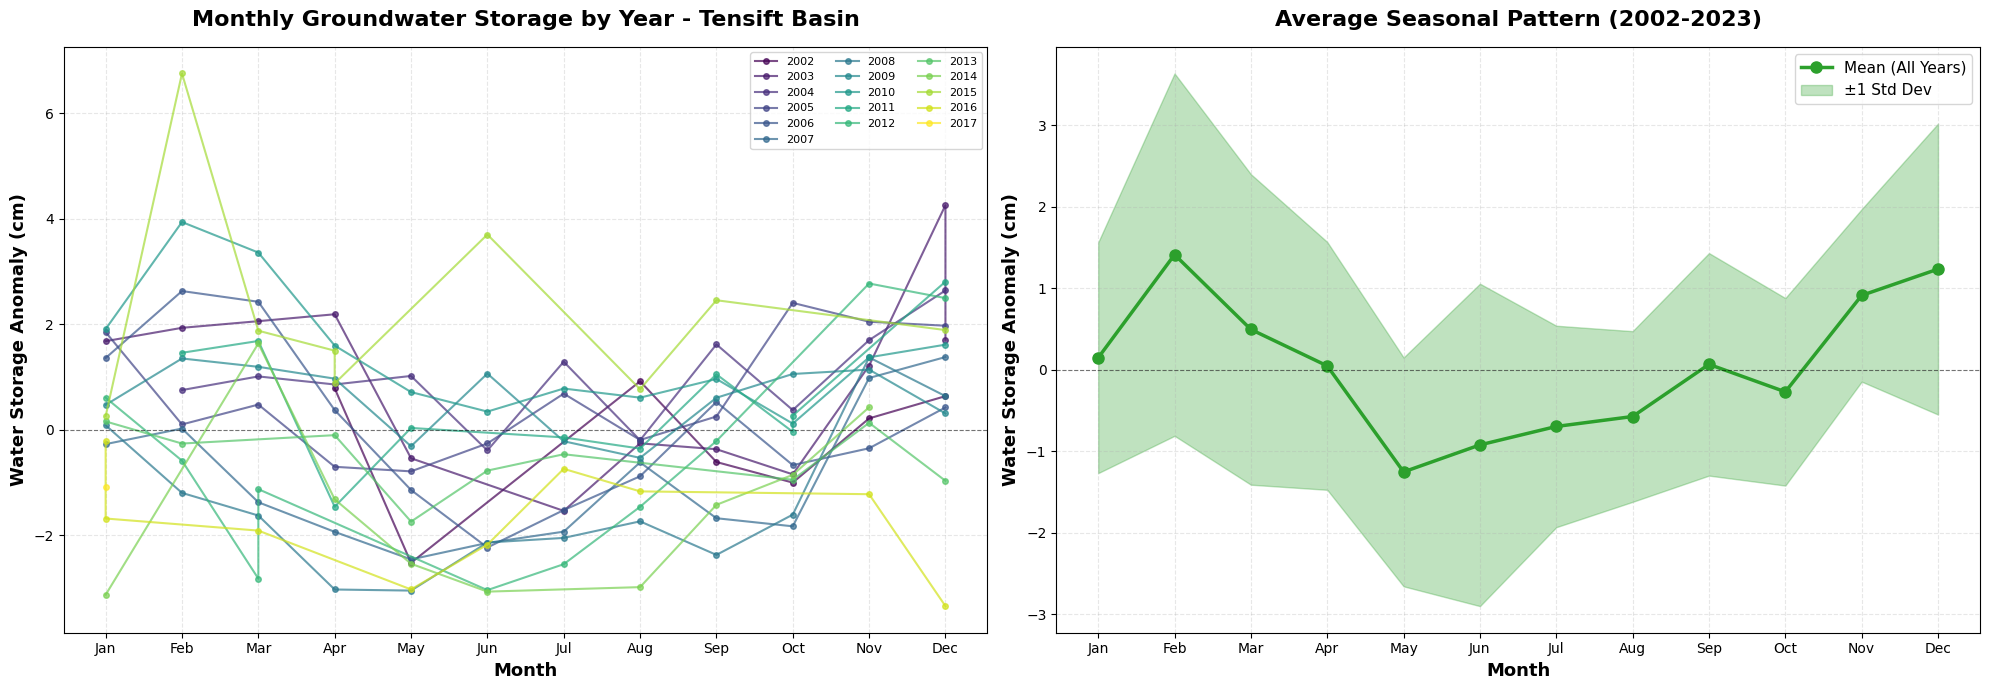

In [ ]:
# --- 7. Seasonal analysis ---

grace_df['year'] = grace_df['date'].dt.year
grace_df['month'] = grace_df['date'].dt.month

# Create two plots: one with all years, one with mean pattern
fig, axes = plt.subplots(1, 2, figsize=(20, 7))

# Plot 1: All years individually
ax1 = axes[0]

# Get unique years and create color map
years = sorted(grace_df['year'].unique())
colors = plt.cm.viridis(np.linspace(0, 1, len(years)))

# Plot each year
for idx, year in enumerate(years):
    year_data = grace_df[grace_df['year'] == year].sort_values('month')
    ax1.plot(year_data['month'], year_data['lwe_thickness_cm'],
             color=colors[idx], linewidth=1.5, marker='o', markersize=4,
             label=str(year), alpha=0.7)

ax1.axhline(y=0, color='black', linestyle='--', linewidth=0.8, alpha=0.5)
ax1.set_xlabel('Month', fontsize=13, fontweight='bold')
ax1.set_ylabel('Water Storage Anomaly (cm)', fontsize=13, fontweight='bold')
ax1.set_title('Monthly Groundwater Storage by Year - Tensift Basin',
              fontsize=16, fontweight='bold', pad=15)
ax1.set_xticks(range(1, 13))
ax1.set_xticklabels(['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
                     'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'])
ax1.grid(True, alpha=0.3, linestyle='--')
ax1.legend(loc='best', fontsize=8, ncol=3)

# Plot 2: Mean seasonal pattern with std dev
ax2 = axes[1]

seasonal_pattern = grace_df.groupby('month')['lwe_thickness_cm'].agg(['mean', 'std']).reset_index()

ax2.plot(seasonal_pattern['month'], seasonal_pattern['mean'],
         color='#2ca02c', linewidth=2.5, marker='o', markersize=8, label='Mean (All Years)')
ax2.fill_between(seasonal_pattern['month'],
                 seasonal_pattern['mean'] - seasonal_pattern['std'],
                 seasonal_pattern['mean'] + seasonal_pattern['std'],
                 alpha=0.3, color='#2ca02c', label='±1 Std Dev')

ax2.axhline(y=0, color='black', linestyle='--', linewidth=0.8, alpha=0.5)
ax2.set_xlabel('Month', fontsize=13, fontweight='bold')
ax2.set_ylabel('Water Storage Anomaly (cm)', fontsize=13, fontweight='bold')
ax2.set_title('Average Seasonal Pattern (2002-2023)',
              fontsize=16, fontweight='bold', pad=15)
ax2.set_xticks(range(1, 13))
ax2.set_xticklabels(['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
                     'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'])
ax2.grid(True, alpha=0.3, linestyle='--')
ax2.legend(fontsize=11)

plt.tight_layout()
plt.savefig('tensift_grace_seasonal_pattern.png', dpi=300, bbox_inches='tight')
plt.show()

## Sentinal-1 SAR

SENTINEL-1 SAR SOIL MOISTURE CHANGE ANALYSIS - TENSIFT BASIN

Note: Analyzing CHANGE from baseline (oldest data) to current
Sentinel-1 data available from October 2014 onwards
Resolution: 1km for spatial analysis

Loading Sentinel-1 SAR data...

Loaded Sentinel-1 data from 2015-01-01 to 2024-12-31

Creating monthly composites...
Created monthly composites: 117 images

Calculating change from baseline...

Baseline period: 2015-03-16 to 2025-03-16

Extracting time series...
Fetching data from Google Earth Engine...

Extracted 117 valid measurements

Analyzing spatial patterns...

Performing spatial change analysis...
Recent period: 2023-11-16 to 2024-11-16

Spatial Change Statistics (VV backscatter change in dB):
  Mean Change:     -0.22 dB
  Std Dev:         0.48 dB
  Maximum Wetting: +2.99 dB
  Maximum Drying:  -4.54 dB

STATISTICAL ANALYSIS - CHANGE FROM BASELINE

Date Range: 2015-03-16 to 2024-11-16
Number of Measurements: 117

VV Backscatter Change Statistics (dB from baseline):
  M

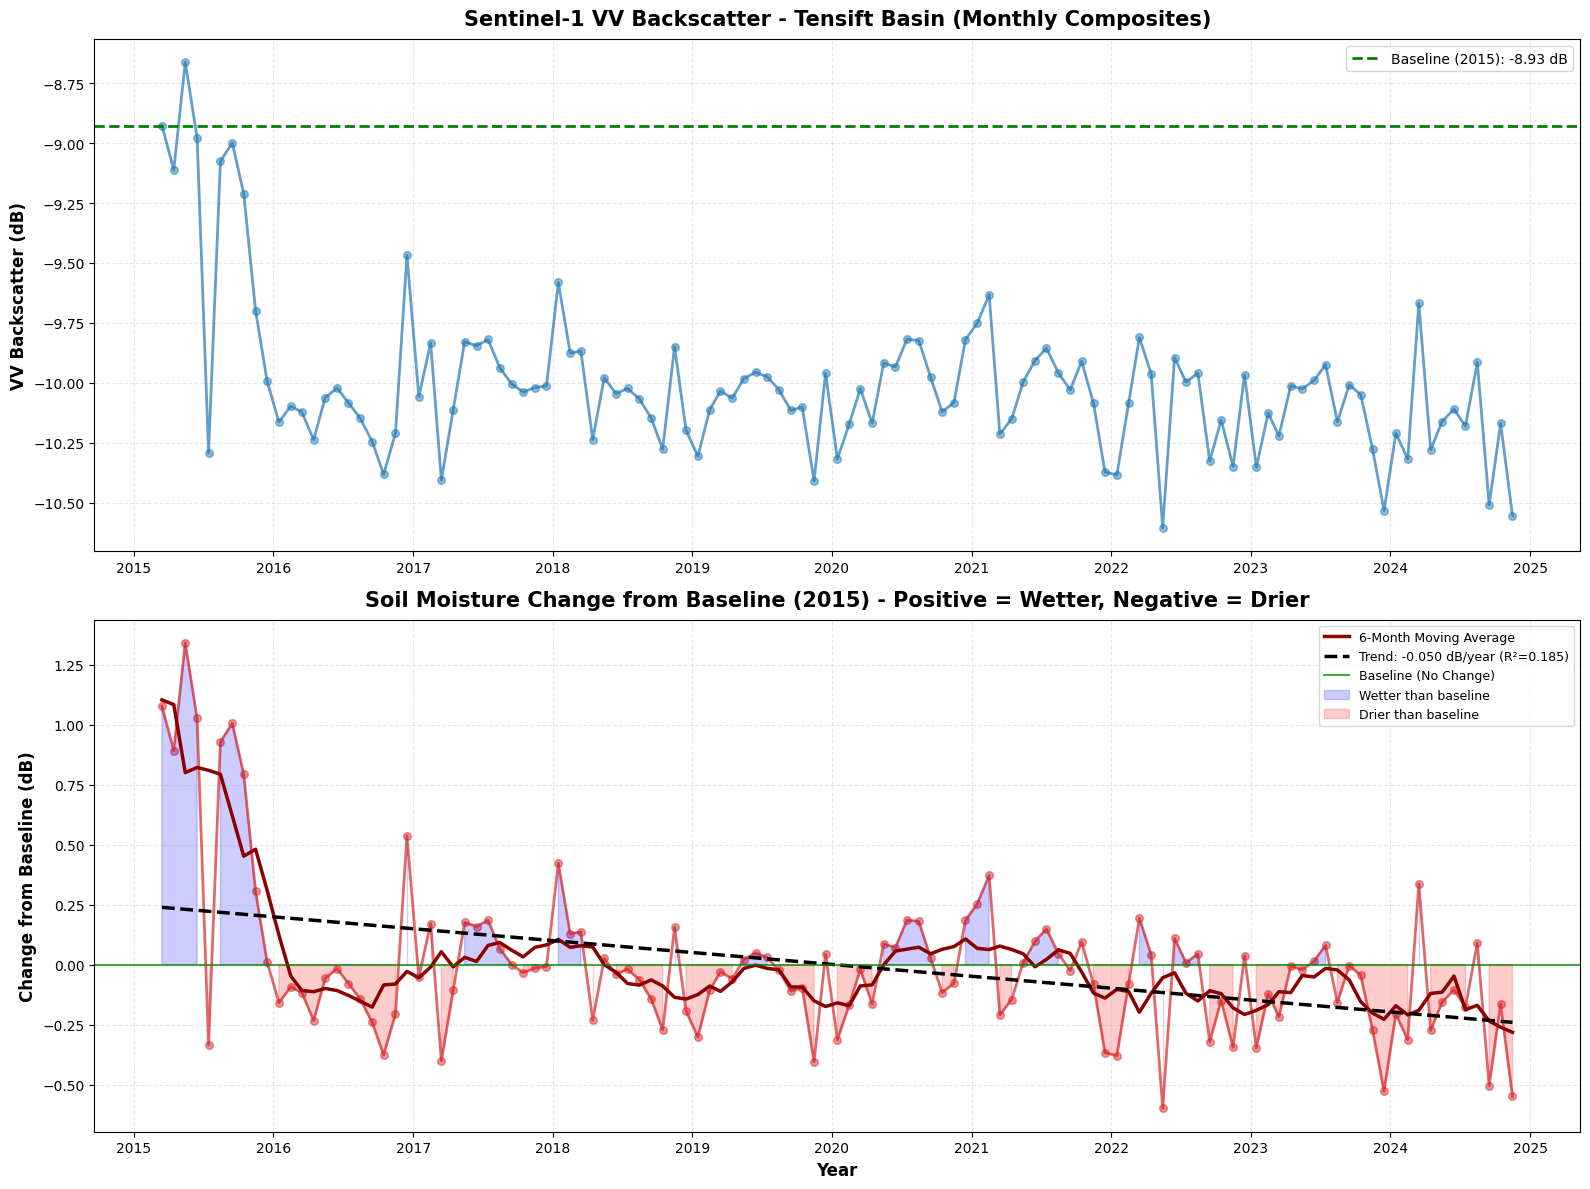

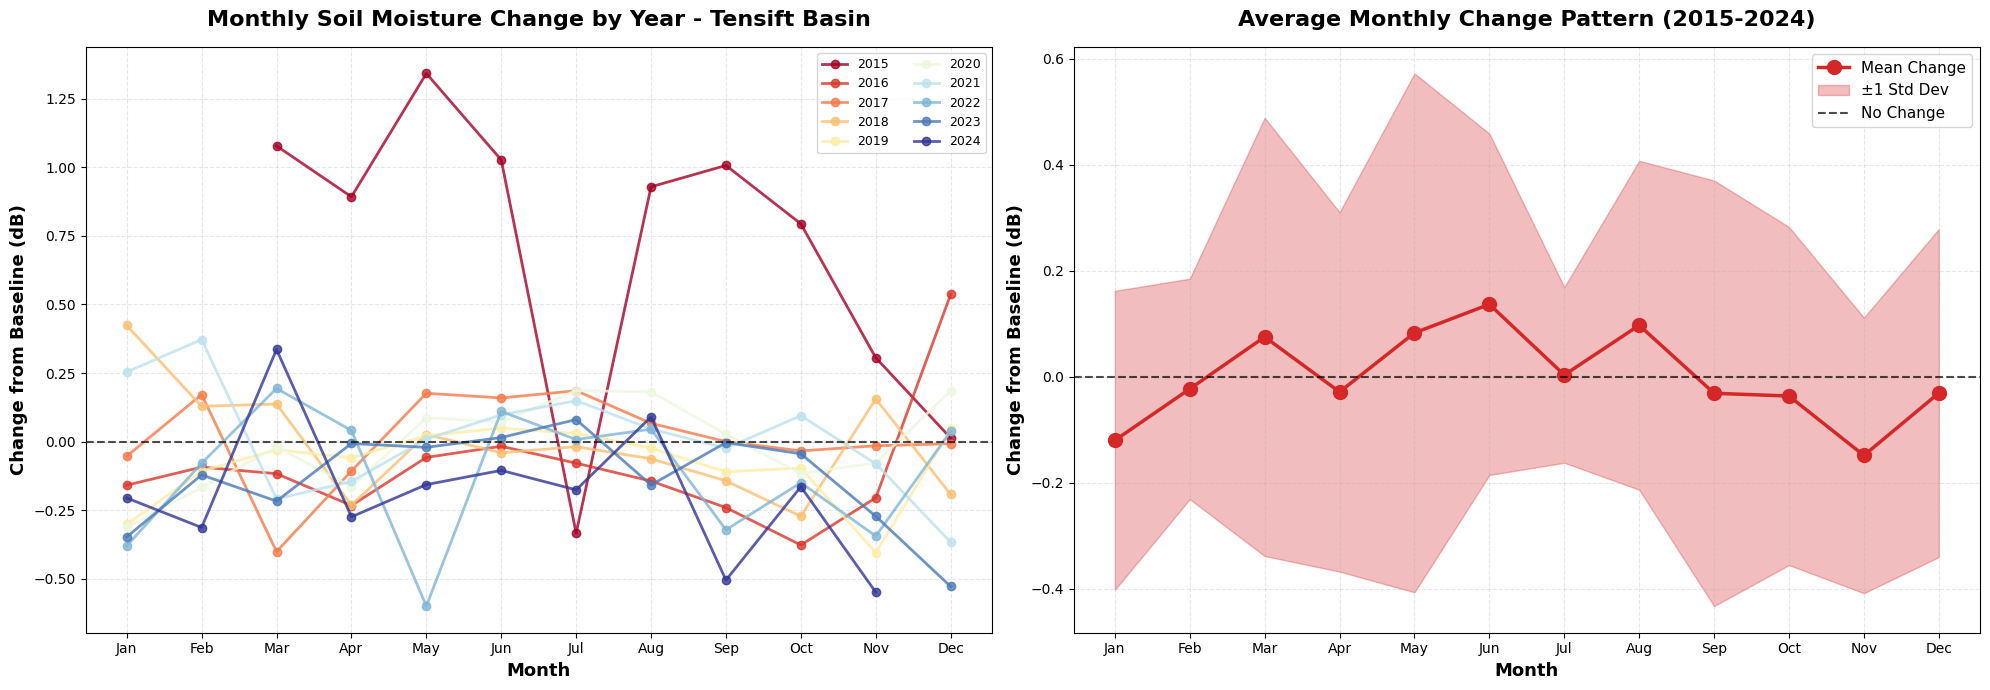

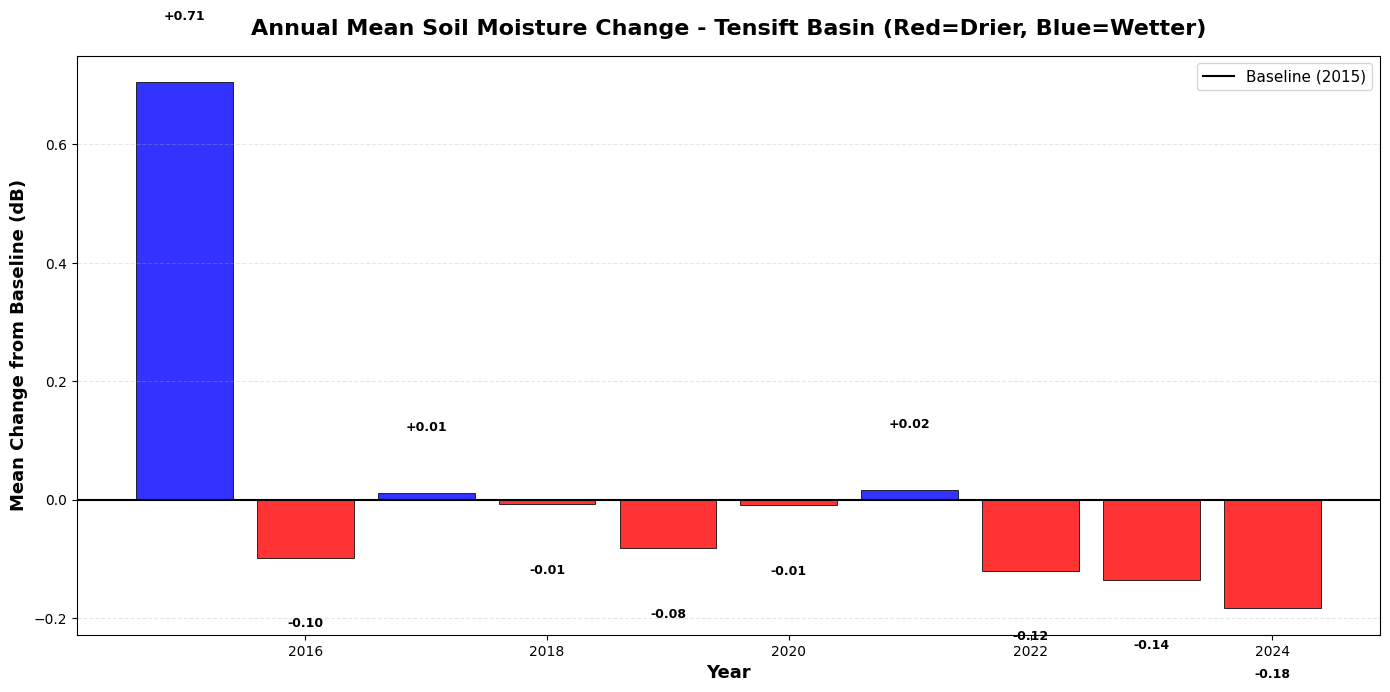


Creating spatial change map...


Map(center=[31.530532507751857, -8.565848432724456], controls=(WidgetControl(options=['position', 'transparent…


KEY FINDINGS:

1. OVERALL TREND: -0.050 dB/year
   Total change over study period: -0.48 dB

2. SPATIAL VARIABILITY:
   Areas with strongest wetting: +2.99 dB
   Areas with strongest drying:  -4.54 dB
   Spatial heterogeneity (std):  0.48 dB

3. TEMPORAL PATTERN:
   No statistically significant trend

FILES SAVED:
✓ tensift_sar_change_analysis.csv - Full time series with change values
✓ tensift_sar_yearly_change_stats.csv - Annual change statistics
✓ tensift_sar_spatial_statistics.csv - Spatial variability metrics
✓ tensift_sar_change_from_baseline.png - Time series of change
✓ tensift_sar_monthly_by_year.png - Monthly patterns by year
✓ tensift_sar_yearly_change.png - Annual comparison

ANALYSIS COMPLETE


In [ ]:
import ee
import geemap
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from datetime import datetime, timedelta

# Initialize Earth Engine (if not already done)
# ee.Initialize()

print("="*80)
print("SENTINEL-1 SAR SOIL MOISTURE CHANGE ANALYSIS - TENSIFT BASIN")
print("="*80)
print("\nNote: Analyzing CHANGE from baseline (oldest data) to current")
print("Sentinel-1 data available from October 2014 onwards")
print("Resolution: 1km for spatial analysis")
print("="*80)

# --- 1. Load Sentinel-1 SAR Data ---

def load_sentinel1_data(geometry, start_date='2015-01-01', end_date='2024-12-31'):
    """
    Load Sentinel-1 SAR Ground Range Detected (GRD) data
    """
    sentinel1 = ee.ImageCollection('COPERNICUS/S1_GRD') \
        .filterBounds(geometry) \
        .filterDate(start_date, end_date) \
        .filter(ee.Filter.listContains('transmitterReceiverPolarisation', 'VV')) \
        .filter(ee.Filter.listContains('transmitterReceiverPolarisation', 'VH')) \
        .filter(ee.Filter.eq('instrumentMode', 'IW')) \
        .select(['VV', 'VH'])

    print(f"\nLoaded Sentinel-1 data from {start_date} to {end_date}")

    return sentinel1

# --- 2. Create Monthly Composites ---

def create_monthly_composites(collection, start_date, end_date):
    """
    Create monthly median composites
    """
    start = ee.Date(start_date)
    end = ee.Date(end_date)

    months = ee.List.sequence(0, end.difference(start, 'month').subtract(1))

    def create_monthly_image(month_offset):
        start_month = start.advance(month_offset, 'month')
        end_month = start_month.advance(1, 'month')

        monthly_images = collection.filterDate(start_month, end_month)

        monthly = ee.Algorithms.If(
            monthly_images.size().gt(0),
            monthly_images.median().set('system:time_start', start_month.advance(15, 'day').millis()),
            None
        )

        return monthly

    monthly_list = months.map(create_monthly_image)
    monthly_collection = ee.ImageCollection(monthly_list.removeAll([None]))

    print(f"Created monthly composites: {monthly_collection.size().getInfo()} images")

    return monthly_collection

# --- 3. Calculate Baseline and Change ---

def calculate_change_from_baseline(collection, geometry):
    """
    Calculate change from baseline (first year) to each subsequent period
    """
    # Get baseline (first year average)
    sorted_collection = collection.sort('system:time_start')
    first_image = sorted_collection.first()
    first_date = ee.Date(first_image.get('system:time_start'))
    baseline_end = first_date.advance(9, 'year')

    baseline = collection.filterDate(first_date, baseline_end).mean().select('VV')

    print(f"\nBaseline period: {first_date.format('YYYY-MM-dd').getInfo()} to {baseline_end.format('YYYY-MM-dd').getInfo()}")

    # Calculate change for each image
    def calculate_change(image):
        vv = image.select('VV')
        change = vv.subtract(baseline).rename('VV_change')
        return image.addBands(change)

    collection_with_change = collection.map(calculate_change)

    return collection_with_change, baseline

# --- 4. Extract time series ---

def extract_sar_timeseries(collection, geometry):
    """
    Extract SAR backscatter change over time
    """
    def extract_values(image):
        stats = image.reduceRegion(
            reducer=ee.Reducer.mean(),
            geometry=geometry,
            scale=5000,  # 5km for time series
            maxPixels=1e9,
            bestEffort=True,
            tileScale=4
        )

        date = image.date().format('YYYY-MM-dd')

        return ee.Feature(None, {
            'date': date,
            'VV_db': stats.get('VV'),
            'VH_db': stats.get('VH'),
            'VV_change_db': stats.get('VV_change'),
            'system_time': image.get('system:time_start')
        })

    features = collection.map(extract_values)

    print("Fetching data from Google Earth Engine...")
    data = features.getInfo()['features']
    df = pd.DataFrame([f['properties'] for f in data])

    df['date'] = pd.to_datetime(df['date'])
    for col in ['VV_db', 'VH_db', 'VV_change_db']:
        df[col] = pd.to_numeric(df[col], errors='coerce')

    df = df.dropna()
    df = df.sort_values('date').reset_index(drop=True)

    print(f"\nExtracted {len(df)} valid measurements")

    return df

# --- 5. Spatial Change Analysis ---

def analyze_spatial_change(collection_with_change, geometry, baseline):
    """
    Analyze WHERE change has been greatest
    """
    print("\nPerforming spatial change analysis...")

    # Get most recent year
    sorted_collection = collection_with_change.sort('system:time_start', False)
    last_image = sorted_collection.first()
    last_date = ee.Date(last_image.get('system:time_start'))
    recent_start = last_date.advance(-1, 'year')

    recent_mean = collection_with_change.filterDate(recent_start, last_date).mean().select('VV')

    print(f"Recent period: {recent_start.format('YYYY-MM-dd').getInfo()} to {last_date.format('YYYY-MM-dd').getInfo()}")

    # Calculate total change
    total_change = recent_mean.subtract(baseline).rename('total_change')

    # Calculate statistics by pixel
    change_stats = total_change.reduceRegion(
        reducer=ee.Reducer.mean().combine(
            reducer2=ee.Reducer.stdDev(),
            sharedInputs=True
        ).combine(
            reducer2=ee.Reducer.minMax(),
            sharedInputs=True
        ),
        geometry=geometry,
        scale=1000,  # 1km for spatial analysis
        maxPixels=1e9,
        bestEffort=True,
        tileScale=4
    )

    stats = change_stats.getInfo()

    print("\nSpatial Change Statistics (VV backscatter change in dB):")
    print(f"  Mean Change:     {stats.get('total_change_mean', 0):+.2f} dB")
    print(f"  Std Dev:         {stats.get('total_change_stdDev', 0):.2f} dB")
    print(f"  Maximum Wetting: {stats.get('total_change_max', 0):+.2f} dB")
    print(f"  Maximum Drying:  {stats.get('total_change_min', 0):+.2f} dB")

    return total_change, stats

# --- 6. Load and process data ---

print("\nLoading Sentinel-1 SAR data...")
s1_collection = load_sentinel1_data(basin_geom, start_date='2015-01-01', end_date='2024-12-31')

print("\nCreating monthly composites...")
s1_monthly = create_monthly_composites(s1_collection, '2015-01-01', '2024-12-31')

print("\nCalculating change from baseline...")
s1_with_change, baseline = calculate_change_from_baseline(s1_monthly, basin_geom)

print("\nExtracting time series...")
sar_df = extract_sar_timeseries(s1_with_change, basin_geom)

print("\nAnalyzing spatial patterns...")
change_map, spatial_stats = analyze_spatial_change(s1_with_change, basin_geom, baseline)

# --- 7. Statistical Analysis ---

print("\n" + "="*80)
print("STATISTICAL ANALYSIS - CHANGE FROM BASELINE")
print("="*80)

print(f"\nDate Range: {sar_df['date'].min().strftime('%Y-%m-%d')} to {sar_df['date'].max().strftime('%Y-%m-%d')}")
print(f"Number of Measurements: {len(sar_df)}")

print(f"\nVV Backscatter Change Statistics (dB from baseline):")
print(f"  Mean Change:     {sar_df['VV_change_db'].mean():+.2f} dB")
print(f"  Std Dev:         {sar_df['VV_change_db'].std():.2f} dB")
print(f"  Maximum Wetting: {sar_df['VV_change_db'].max():+.2f} dB")
print(f"  Maximum Drying:  {sar_df['VV_change_db'].min():+.2f} dB")

# Calculate trend in change
sar_df['days_since_start'] = (sar_df['date'] - sar_df['date'].min()).dt.days
x = sar_df['days_since_start'].values
y = sar_df['VV_change_db'].values

x_mean = np.mean(x)
y_mean = np.mean(y)
slope = np.sum((x - x_mean) * (y - y_mean)) / np.sum((x - x_mean) ** 2)
intercept = y_mean - slope * x_mean
r_squared = 1 - np.sum((y - (slope * x + intercept))**2) / np.sum((y - y_mean)**2)

slope_per_year = slope * 365.25
total_change = slope_per_year * (x.max() / 365.25)

print(f"\nTrend Analysis:")
print(f"  Linear Trend:    {slope_per_year:+.3f} dB/year")
print(f"  Total Change:    {total_change:+.2f} dB over {x.max()/365.25:.1f} years")
print(f"  R² Value:        {r_squared:.4f}")

if slope_per_year < -0.1:
    print(f"\n  ⚠️  SIGNIFICANT DRYING TREND: {abs(slope_per_year):.3f} dB/year")
    print(f"     (Lower backscatter = drier soil)")
elif slope_per_year > 0.1:
    print(f"\n  ✓  SIGNIFICANT WETTING TREND: {slope_per_year:.3f} dB/year")
    print(f"     (Higher backscatter = wetter soil)")
else:
    print(f"\n  ≈  NO SIGNIFICANT TREND: {slope_per_year:+.3f} dB/year")

# Statistical significance test (approximate)
n = len(y)
residuals = y - (slope * x + intercept)
std_err = np.sqrt(np.sum(residuals**2) / (n - 2))
t_stat = abs(slope) / (std_err / np.sqrt(np.sum((x - x_mean)**2)))
print(f"\n  t-statistic:     {t_stat:.2f}")
if t_stat > 2:
    print(f"  Significance:    STATISTICALLY SIGNIFICANT (p < 0.05)")
else:
    print(f"  Significance:    Not statistically significant")

# --- 8. Visualizations ---

# Figure 1: Change from baseline time series
fig, axes = plt.subplots(2, 1, figsize=(16, 12))

# Plot 1: Absolute VV backscatter
ax1 = axes[0]
ax1.plot(sar_df['date'], sar_df['VV_db'], color='#1f77b4', linewidth=2, alpha=0.7)
ax1.scatter(sar_df['date'], sar_df['VV_db'], color='#1f77b4', s=30, alpha=0.5)

# Add baseline reference
baseline_value = sar_df['VV_db'].iloc[0]
ax1.axhline(y=baseline_value, color='green', linestyle='--', linewidth=2,
            label=f'Baseline (2015): {baseline_value:.2f} dB')

ax1.set_ylabel('VV Backscatter (dB)', fontsize=12, fontweight='bold')
ax1.set_title('Sentinel-1 VV Backscatter - Tensift Basin (Monthly Composites)',
              fontsize=15, fontweight='bold', pad=10)
ax1.grid(True, alpha=0.3, linestyle='--')
ax1.legend(fontsize=10)

# Plot 2: CHANGE from baseline
ax2 = axes[1]
ax2.plot(sar_df['date'], sar_df['VV_change_db'], color='#d62728', linewidth=2, alpha=0.7)
ax2.scatter(sar_df['date'], sar_df['VV_change_db'], color='#d62728', s=30, alpha=0.5)

# Add 6-month moving average
sar_df['change_6month_ma'] = sar_df['VV_change_db'].rolling(window=6, center=True, min_periods=1).mean()
ax2.plot(sar_df['date'], sar_df['change_6month_ma'], color='darkred', linewidth=2.5,
         label='6-Month Moving Average')

# Add trend line
trend_line = slope * x + intercept
ax2.plot(sar_df['date'], trend_line, color='black', linewidth=2.5, linestyle='--',
         label=f'Trend: {slope_per_year:+.3f} dB/year (R²={r_squared:.3f})')

# Add zero reference
ax2.axhline(y=0, color='green', linestyle='-', linewidth=1.5, alpha=0.7, label='Baseline (No Change)')

# Shade wetting/drying regions
ax2.fill_between(sar_df['date'], 0, sar_df['VV_change_db'],
                  where=(sar_df['VV_change_db'] > 0), alpha=0.2, color='blue', label='Wetter than baseline')
ax2.fill_between(sar_df['date'], 0, sar_df['VV_change_db'],
                  where=(sar_df['VV_change_db'] <= 0), alpha=0.2, color='red', label='Drier than baseline')

ax2.set_xlabel('Year', fontsize=12, fontweight='bold')
ax2.set_ylabel('Change from Baseline (dB)', fontsize=12, fontweight='bold')
ax2.set_title('Soil Moisture Change from Baseline (2015) - Positive = Wetter, Negative = Drier',
              fontsize=15, fontweight='bold', pad=10)
ax2.grid(True, alpha=0.3, linestyle='--')
ax2.legend(fontsize=9, loc='best')

plt.tight_layout()
plt.savefig('tensift_sar_change_from_baseline.png', dpi=300, bbox_inches='tight')
plt.show()

# --- 9. Monthly patterns by year ---

sar_df['year'] = sar_df['date'].dt.year
sar_df['month'] = sar_df['date'].dt.month

fig, axes = plt.subplots(1, 2, figsize=(20, 7))

# Plot 1: All years - VV change from baseline
ax1 = axes[0]

years = sorted(sar_df['year'].unique())
colors = plt.cm.RdYlBu(np.linspace(0, 1, len(years)))

for idx, year in enumerate(years):
    year_data = sar_df[sar_df['year'] == year].sort_values('month')
    ax1.plot(year_data['month'], year_data['VV_change_db'],
             color=colors[idx], linewidth=2, marker='o', markersize=6,
             label=str(year), alpha=0.8)

ax1.axhline(y=0, color='black', linestyle='--', linewidth=1.5, alpha=0.7)
ax1.set_xlabel('Month', fontsize=13, fontweight='bold')
ax1.set_ylabel('Change from Baseline (dB)', fontsize=13, fontweight='bold')
ax1.set_title('Monthly Soil Moisture Change by Year - Tensift Basin',
              fontsize=16, fontweight='bold', pad=15)
ax1.set_xticks(range(1, 13))
ax1.set_xticklabels(['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
                     'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'])
ax1.grid(True, alpha=0.3, linestyle='--')
ax1.legend(loc='best', fontsize=9, ncol=2)

# Plot 2: Average monthly change pattern
ax2 = axes[1]

monthly_change = sar_df.groupby('month')['VV_change_db'].agg(['mean', 'std']).reset_index()

ax2.plot(monthly_change['month'], monthly_change['mean'],
         color='#d62728', linewidth=2.5, marker='o', markersize=10, label='Mean Change')
ax2.fill_between(monthly_change['month'],
                 monthly_change['mean'] - monthly_change['std'],
                 monthly_change['mean'] + monthly_change['std'],
                 alpha=0.3, color='#d62728', label='±1 Std Dev')

ax2.axhline(y=0, color='black', linestyle='--', linewidth=1.5, alpha=0.7, label='No Change')
ax2.set_xlabel('Month', fontsize=13, fontweight='bold')
ax2.set_ylabel('Change from Baseline (dB)', fontsize=13, fontweight='bold')
ax2.set_title('Average Monthly Change Pattern (2015-2024)',
              fontsize=16, fontweight='bold', pad=15)
ax2.set_xticks(range(1, 13))
ax2.set_xticklabels(['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
                     'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'])
ax2.grid(True, alpha=0.3, linestyle='--')
ax2.legend(fontsize=11)

plt.tight_layout()
plt.savefig('tensift_sar_monthly_by_year.png', dpi=300, bbox_inches='tight')
plt.show()

# --- 10. Annual comparison ---

yearly_stats = sar_df.groupby('year')['VV_change_db'].agg(['mean', 'min', 'max']).reset_index()

fig, ax = plt.subplots(figsize=(14, 7))

colors = ['red' if x < 0 else 'blue' for x in yearly_stats['mean']]
ax.bar(yearly_stats['year'], yearly_stats['mean'], color=colors,
       edgecolor='black', linewidth=0.7, alpha=0.8)

# Add value labels
for idx, row in yearly_stats.iterrows():
    ax.text(row['year'], row['mean'] + (0.1 if row['mean'] > 0 else -0.1),
            f"{row['mean']:+.2f}", ha='center',
            va='bottom' if row['mean'] > 0 else 'top',
            fontweight='bold', fontsize=9)

ax.axhline(y=0, color='black', linestyle='-', linewidth=1.5, label='Baseline (2015)')
ax.set_xlabel('Year', fontsize=13, fontweight='bold')
ax.set_ylabel('Mean Change from Baseline (dB)', fontsize=13, fontweight='bold')
ax.set_title('Annual Mean Soil Moisture Change - Tensift Basin (Red=Drier, Blue=Wetter)',
             fontsize=16, fontweight='bold', pad=15)
ax.grid(True, alpha=0.3, axis='y', linestyle='--')
ax.legend(fontsize=11)

plt.tight_layout()
plt.savefig('tensift_sar_yearly_change.png', dpi=300, bbox_inches='tight')
plt.show()

# --- 11. Spatial change map ---

print("\n" + "="*80)
print("Creating spatial change map...")
print("="*80)

Map = geemap.Map()
Map.centerObject(basin_geom, 8)

Map.add_basemap('SATELLITE')
Map.addLayer(basin_geom, {'color': 'yellow'}, 'Tensift Basin', opacity=0.8)

# Visualization for change (dB difference)
change_vis = {
    'min': -3,
    'max': 3,
    'palette': ['darkred', 'red', 'orange', 'white', 'lightblue', 'blue', 'darkblue']
}

Map.addLayer(change_map.clip(basin_geom), change_vis,
             'Soil Moisture Change (Baseline to Recent)', True)

legend_keys = ['Strong Drying', 'Moderate Drying', 'No Change', 'Moderate Wetting', 'Strong Wetting']
legend_colors = ['#8B0000', '#FF6347', '#FFFFFF', '#87CEEB', '#00008B']

Map.add_legend(
    title='Change from Baseline (dB)',
    keys=legend_keys,
    colors=legend_colors,
    position='bottomright'
)

display(Map)

# --- 12. Save results ---

sar_df.to_csv('tensift_sar_change_analysis.csv', index=False)
yearly_stats.to_csv('tensift_sar_yearly_change_stats.csv', index=False)

# Save spatial statistics
spatial_df = pd.DataFrame([spatial_stats])
spatial_df.to_csv('tensift_sar_spatial_statistics.csv', index=False)

print("\n" + "="*80)
print("KEY FINDINGS:")
print("="*80)
print(f"\n1. OVERALL TREND: {slope_per_year:+.3f} dB/year")
print(f"   Total change over study period: {total_change:+.2f} dB")
print(f"\n2. SPATIAL VARIABILITY:")
print(f"   Areas with strongest wetting: {spatial_stats.get('total_change_max', 0):+.2f} dB")
print(f"   Areas with strongest drying:  {spatial_stats.get('total_change_min', 0):+.2f} dB")
print(f"   Spatial heterogeneity (std):  {spatial_stats.get('total_change_stdDev', 0):.2f} dB")
print(f"\n3. TEMPORAL PATTERN:")
if abs(slope_per_year) > 0.1 and t_stat > 2:
    print(f"   Statistically significant {'drying' if slope_per_year < 0 else 'wetting'} trend detected")
else:
    print(f"   No statistically significant trend")

print("\n" + "="*80)
print("FILES SAVED:")
print("="*80)
print("✓ tensift_sar_change_analysis.csv - Full time series with change values")
print("✓ tensift_sar_yearly_change_stats.csv - Annual change statistics")
print("✓ tensift_sar_spatial_statistics.csv - Spatial variability metrics")
print("✓ tensift_sar_change_from_baseline.png - Time series of change")
print("✓ tensift_sar_monthly_by_year.png - Monthly patterns by year")
print("✓ tensift_sar_yearly_change.png - Annual comparison")

print("\n" + "="*80)
print("ANALYSIS COMPLETE")
print("="*80)

##MODIS


Processing 2000...
Processing 2001...
Processing 2002...
Processing 2003...
Processing 2004...
Processing 2005...
Processing 2006...
Processing 2007...
Processing 2008...
Processing 2009...
Processing 2010...
Processing 2011...
Processing 2012...
Processing 2013...
Processing 2014...
Processing 2015...
Processing 2016...
Error processing 2016: name 'get_vegetation_metrics' is not defined
Processing 2017...
Error processing 2017: name 'get_vegetation_metrics' is not defined
Processing 2018...
Error processing 2018: name 'get_vegetation_metrics' is not defined
Processing 2019...
Error processing 2019: name 'get_vegetation_metrics' is not defined
Processing 2020...
Error processing 2020: name 'get_vegetation_metrics' is not defined
Processing 2021...
Error processing 2021: name 'get_vegetation_metrics' is not defined
Processing 2022...
Error processing 2022: name 'get_vegetation_metrics' is not defined
Processing 2023...
Error processing 2023: name 'get_vegetation_metrics' is not defined


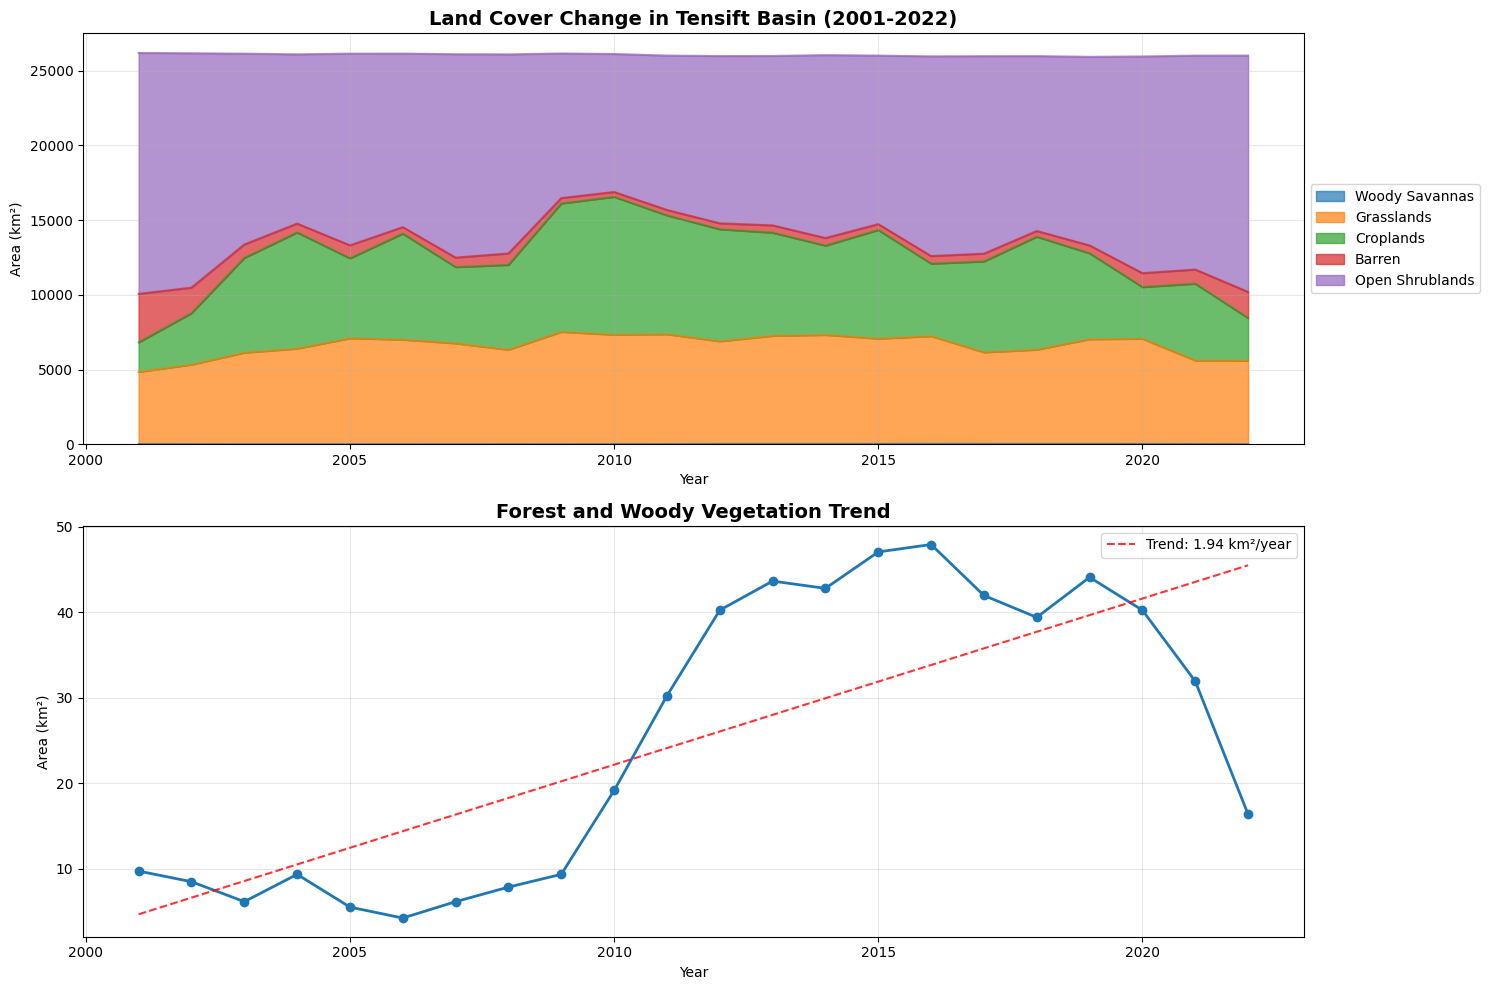


=== STATISTICAL SUMMARY ===

✓ Results saved to CSV files


In [ ]:
# Install required packages (run once)
!pip install earthengine-api geemap

import ee
import geemap
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime
import json

# Authenticate and initialize Earth Engine
# ee.Authenticate()
ee.Initialize(project='thrive-care')

# Convert your Tensift basin to Earth Engine geometry
basin_geom = geemap.geopandas_to_ee(basin)

# Define your analysis parameters
START_YEAR = 2000  # Adjust based on your tree planting timeline
END_YEAR = 2024
YEARS = list(range(START_YEAR, END_YEAR + 1))


# --- OPTION 2: Using MODIS Land Cover (500m resolution, 2001-2022) ---
# Better for long-term trend analysis
def get_modis_landcover(year, geometry):
    """Get land cover statistics from MODIS"""
    modis = ee.ImageCollection('MODIS/061/MCD12Q1') \
        .filterDate(f'{year}-01-01', f'{year}-12-31') \
        .first() \
        .select('LC_Type1')

    area_image = ee.Image.pixelArea().divide(1e6)
    areas = area_image.addBands(modis).reduceRegion(
        reducer=ee.Reducer.sum().group(groupField=1, groupName='landcover'),
        geometry=geometry,
        scale=500,
        maxPixels=1e13
    )

    return areas.getInfo()


# --- Collect data over time ---
print("Collecting land cover data...")
results = []

for year in YEARS:
    print(f"Processing {year}...")
    try:
        # Choose your method based on data availability:

        # For 2001-2022: Use MODIS
        if year >= 2001 and year <= 2022:
            data = get_modis_landcover(year, basin_geom)
            results.append({'year': year, 'data': data, 'source': 'MODIS'})

        # For 2016-present: Use Sentinel-2 NDVI
        if year >= 2016:
            veg_data = get_vegetation_metrics(year, basin_geom)
            results.append({'year': year, 'vegetation_data': veg_data, 'source': 'Sentinel-2'})

    except Exception as e:
        print(f"Error processing {year}: {e}")
        continue

# --- Process and visualize results ---

# MODIS Land Cover Classes
MODIS_CLASSES = {
    1: 'Evergreen Needleleaf Forests',
    2: 'Evergreen Broadleaf Forests',
    3: 'Deciduous Needleleaf Forests',
    4: 'Deciduous Broadleaf Forests',
    5: 'Mixed Forests',
    6: 'Closed Shrublands',
    7: 'Open Shrublands',
    8: 'Woody Savannas',
    9: 'Savannas',
    10: 'Grasslands',
    11: 'Permanent Wetlands',
    12: 'Croplands',
    13: 'Urban and Built-up Lands',
    14: 'Cropland/Natural Vegetation Mosaics',
    15: 'Permanent Snow and Ice',
    16: 'Barren',
    17: 'Water Bodies'
}

# Parse MODIS results into DataFrame
def parse_modis_results(results):
    records = []
    for item in results:
        if 'data' in item and 'groups' in item['data']:
            for group in item['data']['groups']:
                records.append({
                    'year': item['year'],
                    'landcover_class': group['landcover'],
                    'landcover_name': MODIS_CLASSES.get(group['landcover'], 'Unknown'),
                    'area_km2': group['sum']
                })
    return pd.DataFrame(records)

# Parse vegetation results
def parse_vegetation_results(results):
    records = []
    for item in results:
        if 'vegetation_data' in item:
            veg = item['vegetation_data']
            record = {'year': item['year']}
            record['mean_ndvi'] = veg.get('NDVI_mean', np.nan)
            record['high_veg_km2'] = veg.get('high_vegetation', {}).get('NDVI', 0)
            record['moderate_veg_km2'] = veg.get('moderate_vegetation', {}).get('NDVI', 0)
            record['low_veg_km2'] = veg.get('low_vegetation', {}).get('NDVI', 0)
            record['bare_soil_km2'] = veg.get('bare_soil', {}).get('NDVI', 0)
            records.append(record)
    return pd.DataFrame(records)

# Create DataFrames
modis_df = parse_modis_results([r for r in results if r.get('source') == 'MODIS'])
veg_df = parse_vegetation_results([r for r in results if r.get('source') == 'Sentinel-2'])

# --- VISUALIZATION ---

# 1. Land cover change over time (MODIS)
if not modis_df.empty:
    fig, axes = plt.subplots(2, 1, figsize=(15, 10))

    # Pivot for stacked area chart
    pivot_df = modis_df.pivot(index='year', columns='landcover_name', values='area_km2').fillna(0)

    # Focus on key classes relevant to tree planting
    key_classes = ['Mixed Forests', 'Woody Savannas', 'Grasslands', 'Croplands', 'Barren', 'Open Shrublands']
    available_classes = [c for c in key_classes if c in pivot_df.columns]

    pivot_df[available_classes].plot(kind='area', stacked=True, ax=axes[0], alpha=0.7)
    axes[0].set_title('Land Cover Change in Tensift Basin (2001-2022)', fontsize=14, fontweight='bold')
    axes[0].set_xlabel('Year')
    axes[0].set_ylabel('Area (km²)')
    axes[0].legend(loc='center left', bbox_to_anchor=(1, 0.5))
    axes[0].grid(True, alpha=0.3)

    # Forest/woodland trend
    forest_cols = [c for c in pivot_df.columns if 'Forest' in c or 'Woody' in c]
    if forest_cols:
        forest_area = pivot_df[forest_cols].sum(axis=1)
        axes[1].plot(forest_area.index, forest_area.values, marker='o', linewidth=2, markersize=6)
        axes[1].set_title('Forest and Woody Vegetation Trend', fontsize=14, fontweight='bold')
        axes[1].set_xlabel('Year')
        axes[1].set_ylabel('Area (km²)')
        axes[1].grid(True, alpha=0.3)

        # Add trend line
        z = np.polyfit(forest_area.index, forest_area.values, 1)
        p = np.poly1d(z)
        axes[1].plot(forest_area.index, p(forest_area.index), "r--", alpha=0.8, label=f'Trend: {z[0]:.2f} km²/year')
        axes[1].legend()

    plt.tight_layout()
    plt.savefig('tensift_landcover_change.png', dpi=300, bbox_inches='tight')
    plt.show()


# 3. Statistical summary
print("\n=== STATISTICAL SUMMARY ===")
if not veg_df.empty and len(veg_df) > 1:
    first_year = veg_df.iloc[0]
    last_year = veg_df.iloc[-1]

    print(f"\nVegetation Change ({first_year['year']:.0f} to {last_year['year']:.0f}):")
    print(f"  Mean NDVI change: {(last_year['mean_ndvi'] - first_year['mean_ndvi']):.4f}")
    print(f"  High vegetation area change: {(last_year['high_veg_km2'] - first_year['high_veg_km2']):.2f} km²")

    # Calculate annual change rate
    years_span = last_year['year'] - first_year['year']
    if years_span > 0:
        ndvi_rate = (last_year['mean_ndvi'] - first_year['mean_ndvi']) / years_span
        print(f"  Annual NDVI change rate: {ndvi_rate:.4f} per year")

# Save results
modis_df.to_csv('tensift_landcover_modis.csv', index=False)
veg_df.to_csv('tensift_vegetation_sentinel2.csv', index=False)
print("\n✓ Results saved to CSV files")

Creating maps...


Map(center=[31.530532507751857, -8.565848432724456], controls=(WidgetControl(options=['position', 'transparent…


Calculating change statistics...

Filtering changes ≥ 7.1 km²
Showing 16 out of 28 change types
Displayed area: 9167.72 km² out of 9195.65 km² total



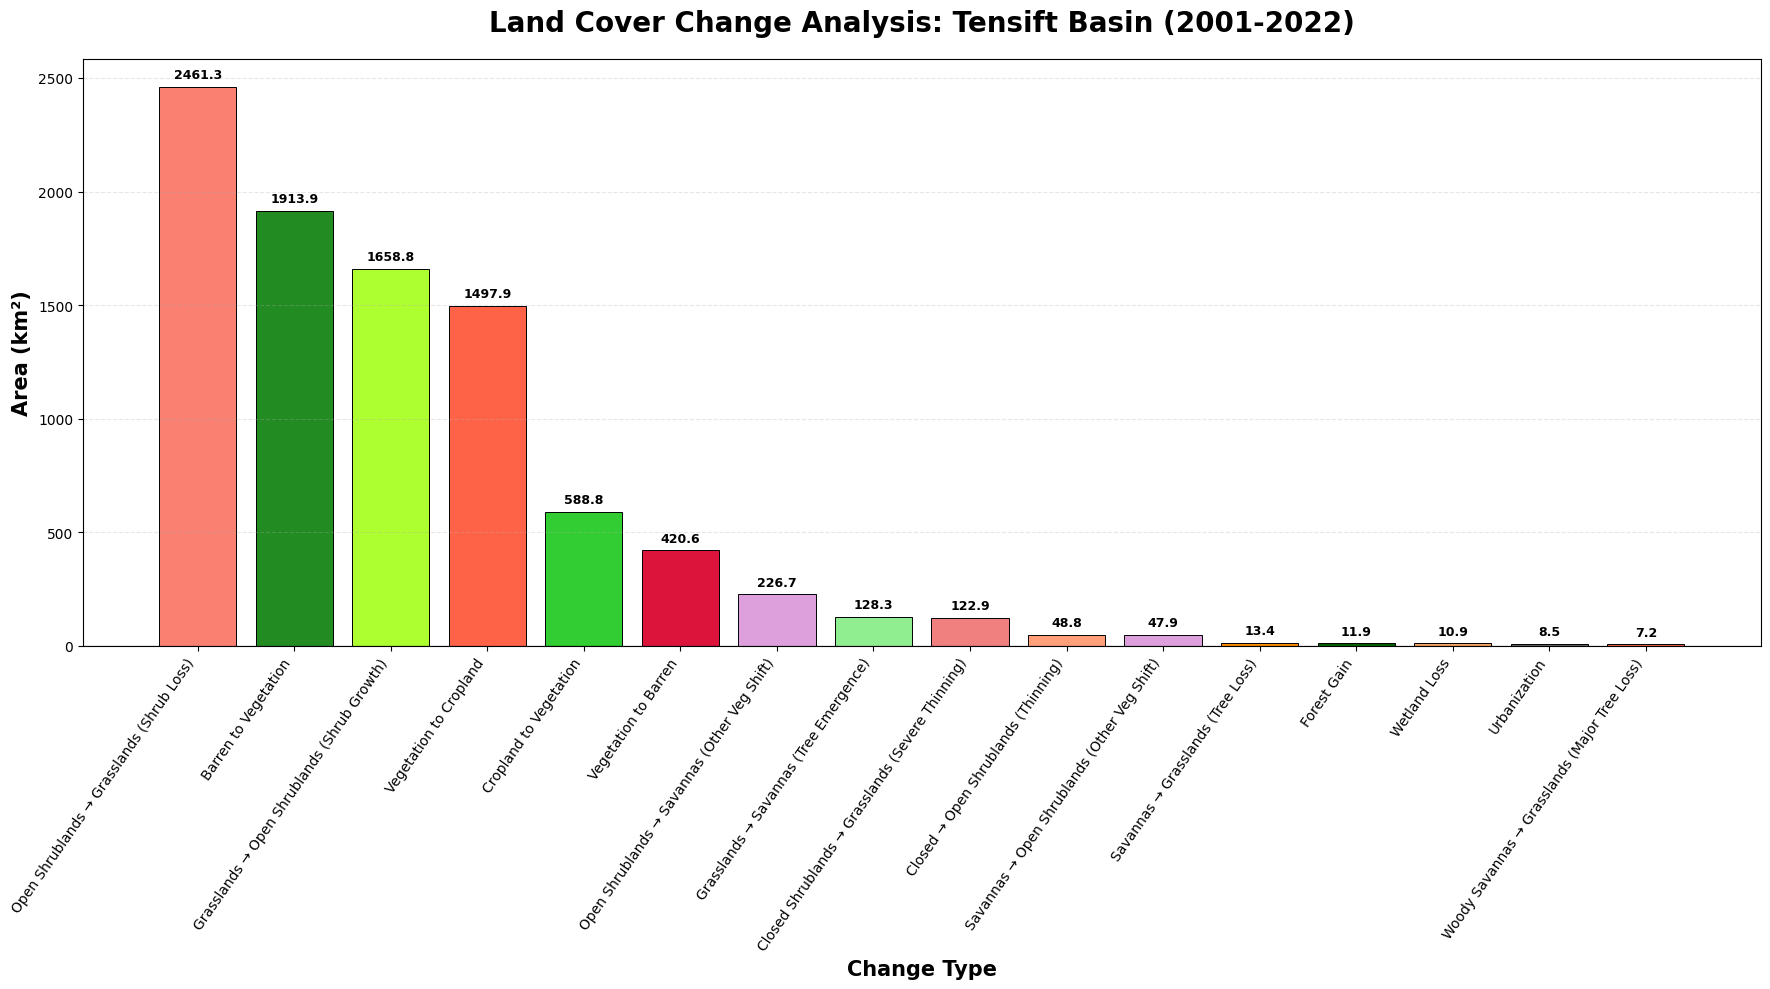

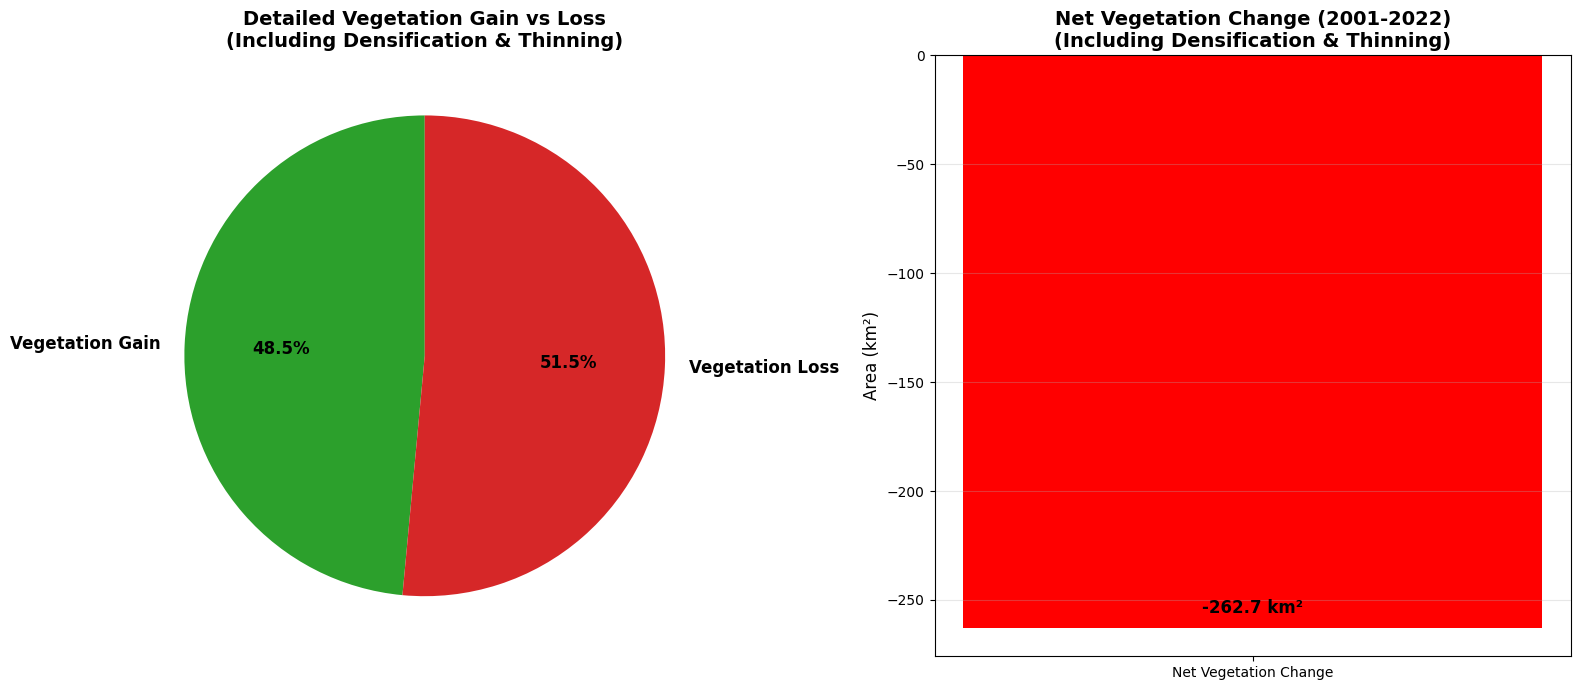


MAJOR LAND COVER CHANGES: TENSIFT BASIN (2001-2022)

Displayed Changed Area: 9167.72 km²
Total Changed Area: 9195.65 km²
Percentage Shown: 99.7%

MAJOR VEGETATION GAINS (Potential Tree Planting Impact):
  Forest Gain                                       :    11.93 km² ✓
  Barren to Vegetation                              :  1913.88 km² ✓
  Cropland to Vegetation                            :   588.78 km² ✓

VEGETATION DENSIFICATION (Early Tree/Shrub Establishment):
  Grasslands → Open Shrublands (Shrub Growth)       :  1658.79 km² ✓
  Grasslands → Savannas (Tree Emergence)            :   128.33 km² ✓
  Open → Closed Shrublands (Densification)          :     5.10 km² (< 7.1 km²)
  Grasslands → Woody Savannas (Tree Growth)         :     1.91 km² (< 7.1 km²)
  Grasslands → Closed Shrublands (Dense Shrubs)     :     1.49 km² (< 7.1 km²)

  → TOTAL POSITIVE VEGETATION CHANGE: 4310.22 km²

MAJOR VEGETATION LOSSES:
  Vegetation to Barren                              :   420.60 km² ✓
  Cropla

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.colors import ListedColormap
import numpy as np
import pandas as pd
import ee
import geemap

# --- 1. Visualize MODIS land cover for specific years ---

def visualize_modis_landcover(year, geometry, ax=None):
    """Visualize MODIS land cover for a specific year"""
    modis = ee.ImageCollection('MODIS/061/MCD12Q1') \
        .filterDate(f'{year}-01-01', f'{year}-12-31') \
        .first() \
        .select('LC_Type1')

    # Define visualization parameters with MODIS colors
    vis_params = {
        'min': 1,
        'max': 17,
        'palette': [
            '05450a', '086a10', '54a708', '78d203', '009900',  # Forests (1-5)
            'c6b044', 'dcd159', 'dade48', 'fbff13', 'b6ff05',  # Shrubs/Grass (6-10)
            '27ff87', 'c24f44', 'a5a5a5', 'ff6d4c',            # Wetlands/Crops/Urban (11-14)
            'ffffff', 'f9ffa4', '1c0dff'                        # Snow/Barren/Water (15-17)
        ]
    }

    return modis, vis_params

# --- 2. Create change detection map ---

def create_change_map(start_year, end_year, geometry):
    """Create a map showing areas of land cover change"""

    # Get MODIS land cover for both years
    modis_start = ee.ImageCollection('MODIS/061/MCD12Q1') \
        .filterDate(f'{start_year}-01-01', f'{start_year}-12-31') \
        .first() \
        .select('LC_Type1')

    modis_end = ee.ImageCollection('MODIS/061/MCD12Q1') \
        .filterDate(f'{end_year}-01-01', f'{end_year}-12-31') \
        .first() \
        .select('LC_Type1')

    # Calculate change (0 = no change, 1 = changed)
    change = modis_start.neq(modis_end).selfMask()

    # Calculate change to/from vegetation classes
    vegetation_classes = ee.List([1, 2, 3, 4, 5, 6, 7, 8, 9])  # Forest/shrub/savanna classes

    start_is_veg = modis_start.remap(vegetation_classes, ee.List.repeat(1, 9), 0)
    end_is_veg = modis_end.remap(vegetation_classes, ee.List.repeat(1, 9), 0)

    # Create change categories
    # 1 = Vegetation loss, 2 = Vegetation gain, 3 = Other change
    veg_loss = start_is_veg.eq(1).And(end_is_veg.eq(0)).multiply(1)
    veg_gain = start_is_veg.eq(0).And(end_is_veg.eq(1)).multiply(2)
    other_change = change.And(veg_loss.add(veg_gain).eq(0)).multiply(3)

    change_classified = veg_loss.add(veg_gain).add(other_change).selfMask()

    return change_classified, modis_start, modis_end

# --- 3. Calculate change statistics ---

def calculate_change_stats(start_year, end_year, geometry):
    """Calculate statistics on land cover changes"""

    modis_start = ee.ImageCollection('MODIS/061/MCD12Q1') \
        .filterDate(f'{start_year}-01-01', f'{start_year}-12-31') \
        .first() \
        .select('LC_Type1')

    modis_end = ee.ImageCollection('MODIS/061/MCD12Q1') \
        .filterDate(f'{end_year}-01-01', f'{end_year}-12-31') \
        .first() \
        .select('LC_Type1')

    # Create transition matrix
    combined = modis_start.multiply(100).add(modis_end)

    area_image = ee.Image.pixelArea().divide(1e6)  # km²

    transitions = area_image.addBands(combined).reduceRegion(
        reducer=ee.Reducer.sum().group(groupField=1, groupName='transition'),
        geometry=geometry,
        scale=500,
        maxPixels=1e13
    )

    return transitions.getInfo()

# --- 4. Detailed change classification function ---

def detailed_classify_change(row, forest_classes, shrub_grass_classes, crop_classes, barren_classes, MODIS_CLASSES):
    """Classify all changes with vegetation shifts broken down"""
    from_code = [k for k, v in MODIS_CLASSES.items() if v == row['from_class']]
    to_code = [k for k, v in MODIS_CLASSES.items() if v == row['to_class']]

    if not from_code or not to_code:
        return 'Unknown'

    from_code = from_code[0]
    to_code = to_code[0]
    from_class = row['from_class']
    to_class = row['to_class']

    # Forest changes
    if from_code in forest_classes and to_code not in forest_classes:
        return 'Forest Loss'
    elif from_code not in forest_classes and to_code in forest_classes:
        return 'Forest Gain'

    # Barren land changes
    elif from_code in barren_classes and to_code in crop_classes:
        return 'Barren to Cropland'
    elif from_code in barren_classes and to_code in shrub_grass_classes:
        return 'Barren to Vegetation'
    elif from_code in crop_classes and to_code in barren_classes:
        return 'Cropland to Barren'
    elif from_code in shrub_grass_classes and to_code in barren_classes:
        return 'Vegetation to Barren'

    # Cropland changes
    elif from_code in shrub_grass_classes and to_code in crop_classes:
        return 'Vegetation to Cropland'
    elif from_code in crop_classes and to_code in shrub_grass_classes:
        return 'Cropland to Vegetation'

    # Urban changes
    elif to_code == 13:
        return 'Urbanization'
    elif from_code == 13:
        return 'Urban Abandonment'

    # Water changes
    elif to_code == 17:
        return 'Conversion to Water'
    elif from_code == 17:
        return 'Water to Land'

    # Wetland changes
    elif 'Wetland' in to_class:
        return 'Wetland Expansion'
    elif 'Wetland' in from_class:
        return 'Wetland Loss'

    # DETAILED VEGETATION TYPE SHIFTS
    # Densification (positive for trees)
    elif from_class == 'Open Shrublands' and to_class == 'Closed Shrublands':
        return 'Open → Closed Shrublands (Densification)'
    elif from_class == 'Grasslands' and to_class == 'Savannas':
        return 'Grasslands → Savannas (Tree Emergence)'
    elif from_class == 'Savannas' and to_class == 'Woody Savannas':
        return 'Savannas → Woody Savannas (More Trees)'
    elif from_class == 'Grasslands' and to_class == 'Woody Savannas':
        return 'Grasslands → Woody Savannas (Tree Growth)'
    elif from_class == 'Open Shrublands' and to_class == 'Woody Savannas':
        return 'Open Shrublands → Woody Savannas (Trees)'
    elif from_class == 'Grasslands' and to_class == 'Open Shrublands':
        return 'Grasslands → Open Shrublands (Shrub Growth)'
    elif from_class == 'Grasslands' and to_class == 'Closed Shrublands':
        return 'Grasslands → Closed Shrublands (Dense Shrubs)'

    # Thinning (negative - vegetation becoming sparser)
    elif from_class == 'Closed Shrublands' and to_class == 'Open Shrublands':
        return 'Closed → Open Shrublands (Thinning)'
    elif from_class == 'Woody Savannas' and to_class == 'Savannas':
        return 'Woody Savannas → Savannas (Tree Loss)'
    elif from_class == 'Savannas' and to_class == 'Grasslands':
        return 'Savannas → Grasslands (Tree Loss)'
    elif from_class == 'Woody Savannas' and to_class == 'Grasslands':
        return 'Woody Savannas → Grasslands (Major Tree Loss)'
    elif from_class == 'Woody Savannas' and to_class == 'Open Shrublands':
        return 'Woody Savannas → Open Shrublands (Degradation)'
    elif from_class == 'Closed Shrublands' and to_class == 'Grasslands':
        return 'Closed Shrublands → Grasslands (Severe Thinning)'
    elif from_class == 'Open Shrublands' and to_class == 'Grasslands':
        return 'Open Shrublands → Grasslands (Shrub Loss)'

    # Other vegetation shifts (lateral - not clearly positive or negative)
    elif from_code in shrub_grass_classes and to_code in shrub_grass_classes:
        return f'{from_class} → {to_class} (Other Veg Shift)'

    # Cropland mosaics
    elif 'Mosaic' in to_class and 'Mosaic' not in from_class:
        return 'To Cropland Mosaic'
    elif 'Mosaic' in from_class and 'Mosaic' not in to_class:
        return 'From Cropland Mosaic'

    # Everything else
    else:
        return 'Other Miscellaneous'

# --- 5. Create interactive map ---

print("Creating maps...")

# Initialize map centered on Tensift basin
Map = geemap.Map()
Map.centerObject(basin_geom, 9)

# Add basemap
Map.add_basemap('SATELLITE')

# Add Tensift basin boundary
Map.addLayer(basin_geom, {'color': 'yellow'}, 'Tensift Basin', opacity=0.5)

# Add rivers
oueds_ee = geemap.geopandas_to_ee(oueds_basin)
Map.addLayer(oueds_ee, {'color': 'blue'}, 'Rivers', False)

# Add land cover for different years
years_to_show = [2001, 2010, 2015, 2022]

for year in years_to_show:
    modis, vis_params = visualize_modis_landcover(year, basin_geom)
    Map.addLayer(modis.clip(basin_geom), vis_params, f'Land Cover {year}', False)

# Add change detection layer
change_map, _, _ = create_change_map(2001, 2022, basin_geom)

change_vis = {
    'min': 1,
    'max': 3,
    'palette': ['red', 'green', 'orange']  # Loss, Gain, Other change
}

Map.addLayer(change_map.clip(basin_geom), change_vis, 'Land Cover Change (2001-2022)', True)

# Add legend
legend_keys = ['Vegetation Loss', 'Vegetation Gain', 'Other Change']
legend_colors = ['#FF0000', '#00FF00', '#FFA500']

Map.add_legend(
    title='Land Cover Change (2001-2022)',
    keys=legend_keys,
    colors=legend_colors,
    position='bottomright'
)

# Display map
display(Map)

# --- 6. Calculate and display change statistics ---

print("\nCalculating change statistics...")
change_stats = calculate_change_stats(2001, 2022, basin_geom)

# Define class groupings
forest_classes = [1, 2, 3, 4, 5]
shrub_grass_classes = [6, 7, 8, 9, 10]
crop_classes = [12, 14]
barren_classes = [16]

# Parse transition matrix
transitions = []
if 'groups' in change_stats:
    for group in change_stats['groups']:
        transition_code = group['transition']
        from_class = int(transition_code / 100)
        to_class = int(transition_code % 100)
        area_km2 = group['sum']

        transitions.append({
            'from_class': MODIS_CLASSES.get(from_class, 'Unknown'),
            'to_class': MODIS_CLASSES.get(to_class, 'Unknown'),
            'area_km2': area_km2,
            'changed': from_class != to_class
        })

transitions_df = pd.DataFrame(transitions)

# Filter to only changes (not stable areas)
changes_only = transitions_df[transitions_df['changed'] == True].copy()

# Apply detailed classification
changes_only['detailed_type'] = changes_only.apply(
    lambda row: detailed_classify_change(row, forest_classes, shrub_grass_classes,
                                         crop_classes, barren_classes, MODIS_CLASSES),
    axis=1
)

# Aggregate by detailed change type
all_changes_detailed = changes_only.groupby('detailed_type')['area_km2'].sum().sort_values(ascending=False)

# FILTER: Keep only changes >= 7.1 km²
AREA_THRESHOLD = 7.1
all_changes_filtered = all_changes_detailed[all_changes_detailed >= AREA_THRESHOLD]

print(f"\n{'='*80}")
print(f"Filtering changes ≥ {AREA_THRESHOLD} km²")
print(f"Showing {len(all_changes_filtered)} out of {len(all_changes_detailed)} change types")
print(f"Displayed area: {all_changes_filtered.sum():.2f} km² out of {all_changes_detailed.sum():.2f} km² total")
print(f"{'='*80}\n")

# --- 7. Create the comprehensive bar chart ---

fig, ax = plt.subplots(figsize=(18, 10))

# Define colors for each category
color_mapping = {
    # Major vegetation gains (dark greens)
    'Forest Gain': '#006400',
    'Barren to Vegetation': '#228B22',
    'Cropland to Vegetation': '#32CD32',

    # Vegetation densification (light to medium greens)
    'Grasslands → Savannas (Tree Emergence)': '#90EE90',
    'Savannas → Woody Savannas (More Trees)': '#7CFC00',
    'Grasslands → Woody Savannas (Tree Growth)': '#7FFF00',
    'Open → Closed Shrublands (Densification)': '#00FA9A',
    'Open Shrublands → Woody Savannas (Trees)': '#98FB98',
    'Grasslands → Open Shrublands (Shrub Growth)': '#ADFF2F',
    'Grasslands → Closed Shrublands (Dense Shrubs)': '#9ACD32',

    # Major vegetation losses (reds)
    'Forest Loss': '#8B0000',
    'Vegetation to Barren': '#DC143C',
    'Cropland to Barren': '#FF4500',
    'Vegetation to Cropland': '#FF6347',

    # Vegetation thinning (light to medium reds/oranges)
    'Closed → Open Shrublands (Thinning)': '#FFA07A',
    'Woody Savannas → Savannas (Tree Loss)': '#FF7F50',
    'Savannas → Grasslands (Tree Loss)': '#FF8C00',
    'Woody Savannas → Grasslands (Major Tree Loss)': '#FF6347',
    'Woody Savannas → Open Shrublands (Degradation)': '#CD5C5C',
    'Closed Shrublands → Grasslands (Severe Thinning)': '#F08080',
    'Open Shrublands → Grasslands (Shrub Loss)': '#FA8072',

    # Cropland changes (yellows/golds)
    'Barren to Cropland': '#FFD700',

    # Urban changes (grays)
    'Urbanization': '#696969',
    'Urban Abandonment': '#C0C0C0',

    # Water changes (blues)
    'Conversion to Water': '#4682B4',
    'Water to Land': '#87CEEB',

    # Wetland changes (teals)
    'Wetland Expansion': '#20B2AA',
    'Wetland Loss': '#F4A460',

    # Cropland mosaics (khakis)
    'To Cropland Mosaic': '#DAA520',
    'From Cropland Mosaic': '#F0E68C',

    # Other (grays)
    'Other Miscellaneous': '#A9A9A9',
    'Unknown': '#778899'
}

# Get colors for bars
bar_colors = []
for cat in all_changes_filtered.index:
    if cat in color_mapping:
        bar_colors.append(color_mapping[cat])
    elif 'Other Veg Shift' in cat:
        bar_colors.append('#DDA0DD')  # Plum for other lateral shifts
    else:
        bar_colors.append('#CCCCCC')  # Light gray default

# Create bar chart
bars = ax.bar(range(len(all_changes_filtered)), all_changes_filtered.values,
              color=bar_colors, edgecolor='black', linewidth=0.7)

# Customize the plot
ax.set_title(f'Land Cover Change Analysis: Tensift Basin (2001-2022)',
             fontsize=20, fontweight='bold', pad=20)
ax.set_xlabel('Change Type', fontsize=15, fontweight='bold')
ax.set_ylabel('Area (km²)', fontsize=15, fontweight='bold')
ax.set_xticks(range(len(all_changes_filtered)))
ax.set_xticklabels(all_changes_filtered.index, rotation=55, ha='right', fontsize=10)
ax.grid(True, alpha=0.3, axis='y', linestyle='--')

# Add value labels on bars
for i, (cat, v) in enumerate(all_changes_filtered.items()):
    ax.text(i, v + max(all_changes_filtered.values)*0.01, f'{v:.1f}',
            ha='center', va='bottom', fontweight='bold', fontsize=9)

# Add a horizontal line at y=0 for reference
ax.axhline(y=0, color='black', linestyle='-', linewidth=0.8)

plt.tight_layout()
plt.savefig('tensift_major_changes_detailed.png', dpi=300, bbox_inches='tight')
plt.show()

# --- 8. Calculate detailed vegetation gains and losses ---

# Categorize for detailed metrics
major_gains = ['Forest Gain', 'Barren to Vegetation', 'Cropland to Vegetation']
densification = [c for c in all_changes_detailed.index if
                 'Tree Emergence' in c or 'More Trees' in c or 'Tree Growth' in c or
                 'Densification' in c or 'Shrub Growth' in c or 'Dense Shrubs' in c]

major_losses = ['Forest Loss', 'Vegetation to Barren', 'Cropland to Barren', 'Vegetation to Cropland']
thinning = [c for c in all_changes_detailed.index if
            'Thinning' in c or 'Tree Loss' in c or 'Degradation' in c or
            'Shrub Loss' in c or 'Severe Thinning' in c]

total_positive = sum([all_changes_detailed.get(c, 0) for c in major_gains + densification])
total_negative = sum([all_changes_detailed.get(c, 0) for c in major_losses + thinning])
net_change = total_positive - total_negative

# --- 9. Create pie charts and net change visualization ---

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Pie chart of gains vs losses (using detailed metrics)
gain_loss_data = {
    'Vegetation Gain': total_positive,
    'Vegetation Loss': total_negative
}
colors_pie = ['#2ca02c', '#d62728']
axes[0].pie(gain_loss_data.values(), labels=gain_loss_data.keys(), autopct='%1.1f%%',
            colors=colors_pie, startangle=90, textprops={'fontsize': 12, 'fontweight': 'bold'})
axes[0].set_title('Detailed Vegetation Gain vs Loss\n(Including Densification & Thinning)',
                  fontsize=14, fontweight='bold')

# Bar chart showing net change
axes[1].bar(['Net Vegetation Change'], [net_change],
            color='green' if net_change > 0 else 'red', width=0.5)
axes[1].axhline(y=0, color='black', linestyle='-', linewidth=0.5)
axes[1].set_ylabel('Area (km²)', fontsize=12)
axes[1].set_title('Net Vegetation Change (2001-2022)\n(Including Densification & Thinning)',
                  fontsize=14, fontweight='bold')
axes[1].grid(True, alpha=0.3, axis='y')
axes[1].text(0, net_change + abs(net_change)*0.05, f'{net_change:.1f} km²',
             ha='center', va='bottom' if net_change > 0 else 'top',
             fontweight='bold', fontsize=12)

plt.tight_layout()
plt.savefig('tensift_net_change_detailed.png', dpi=300, bbox_inches='tight')
plt.show()

# --- 10. Print detailed summary ---

print("\n" + "="*80)
print(f"MAJOR LAND COVER CHANGES: TENSIFT BASIN (2001-2022)")
print("="*80)

print(f"\nDisplayed Changed Area: {all_changes_filtered.sum():.2f} km²")
print(f"Total Changed Area: {all_changes_detailed.sum():.2f} km²")
print(f"Percentage Shown: {(all_changes_filtered.sum()/all_changes_detailed.sum()*100):.1f}%\n")

print("="*80)
print("MAJOR VEGETATION GAINS (Potential Tree Planting Impact):")
print("="*80)
for cat in major_gains:
    if cat in all_changes_detailed:
        shown = " ✓" if cat in all_changes_filtered.index else " (< 7.1 km²)"
        print(f"  {cat:50s}: {all_changes_detailed[cat]:8.2f} km²{shown}")

print("\nVEGETATION DENSIFICATION (Early Tree/Shrub Establishment):")
for cat in densification:
    shown = " ✓" if cat in all_changes_filtered.index else " (< 7.1 km²)"
    print(f"  {cat:50s}: {all_changes_detailed[cat]:8.2f} km²{shown}")

print(f"\n  → TOTAL POSITIVE VEGETATION CHANGE: {total_positive:.2f} km²")

print("\n" + "="*80)
print("MAJOR VEGETATION LOSSES:")
print("="*80)
for cat in major_losses:
    if cat in all_changes_detailed:
        shown = " ✓" if cat in all_changes_filtered.index else " (< 7.1 km²)"
        print(f"  {cat:50s}: {all_changes_detailed[cat]:8.2f} km²{shown}")

print("\nVEGETATION THINNING (Tree/Shrub Loss):")
for cat in thinning:
    shown = " ✓" if cat in all_changes_filtered.index else " (< 7.1 km²)"
    print(f"  {cat:50s}: {all_changes_detailed[cat]:8.2f} km²{shown}")

print(f"\n  → TOTAL NEGATIVE VEGETATION CHANGE: {total_negative:.2f} km²")

print("\n" + "="*80)
print("NET VEGETATION CHANGE:")
print("="*80)
print(f"  Net Change: {net_change:+.2f} km² ", end="")
if net_change > 0:
    print("✓ POSITIVE - Vegetation is increasing!")
else:
    print("✗ NEGATIVE - Vegetation is decreasing")

print(f"\n=== SUMMARY ===")
print(f"Vegetation Gain: {total_positive:.2f} km²")
print(f"Vegetation Loss: {total_negative:.2f} km²")
print(f"Net Change: {net_change:.2f} km² ({'GAIN' if net_change > 0 else 'LOSS'})")

# --- 11. Save results ---

# Save detailed transitions
changes_only.to_csv('tensift_landcover_transitions_2001_2022.csv', index=False)

# Save detailed results
summary_detailed = pd.DataFrame({
    'Change Type': all_changes_detailed.index,
    'Area (km²)': all_changes_detailed.values,
    'Percentage of Total': (all_changes_detailed.values / all_changes_detailed.sum() * 100),
    'Shown in Chart': all_changes_detailed.index.isin(all_changes_filtered.index)
})
summary_detailed.to_csv('tensift_all_changes_with_filter.csv', index=False)

print("\n✓ Detailed transitions saved to 'tensift_landcover_transitions_2001_2022.csv'")
print(f"✓ Complete summary saved to 'tensift_all_changes_with_filter.csv'")
print(f"✓ Bar chart saved to 'tensift_major_changes_detailed.png'")
print(f"✓ Pie/net change chart saved to 'tensift_net_change_detailed.png'")


Filtering changes > 7 km²
Showing 16 out of 28 change types
Displayed area: 9167.72 km² out of 9195.65 km² total



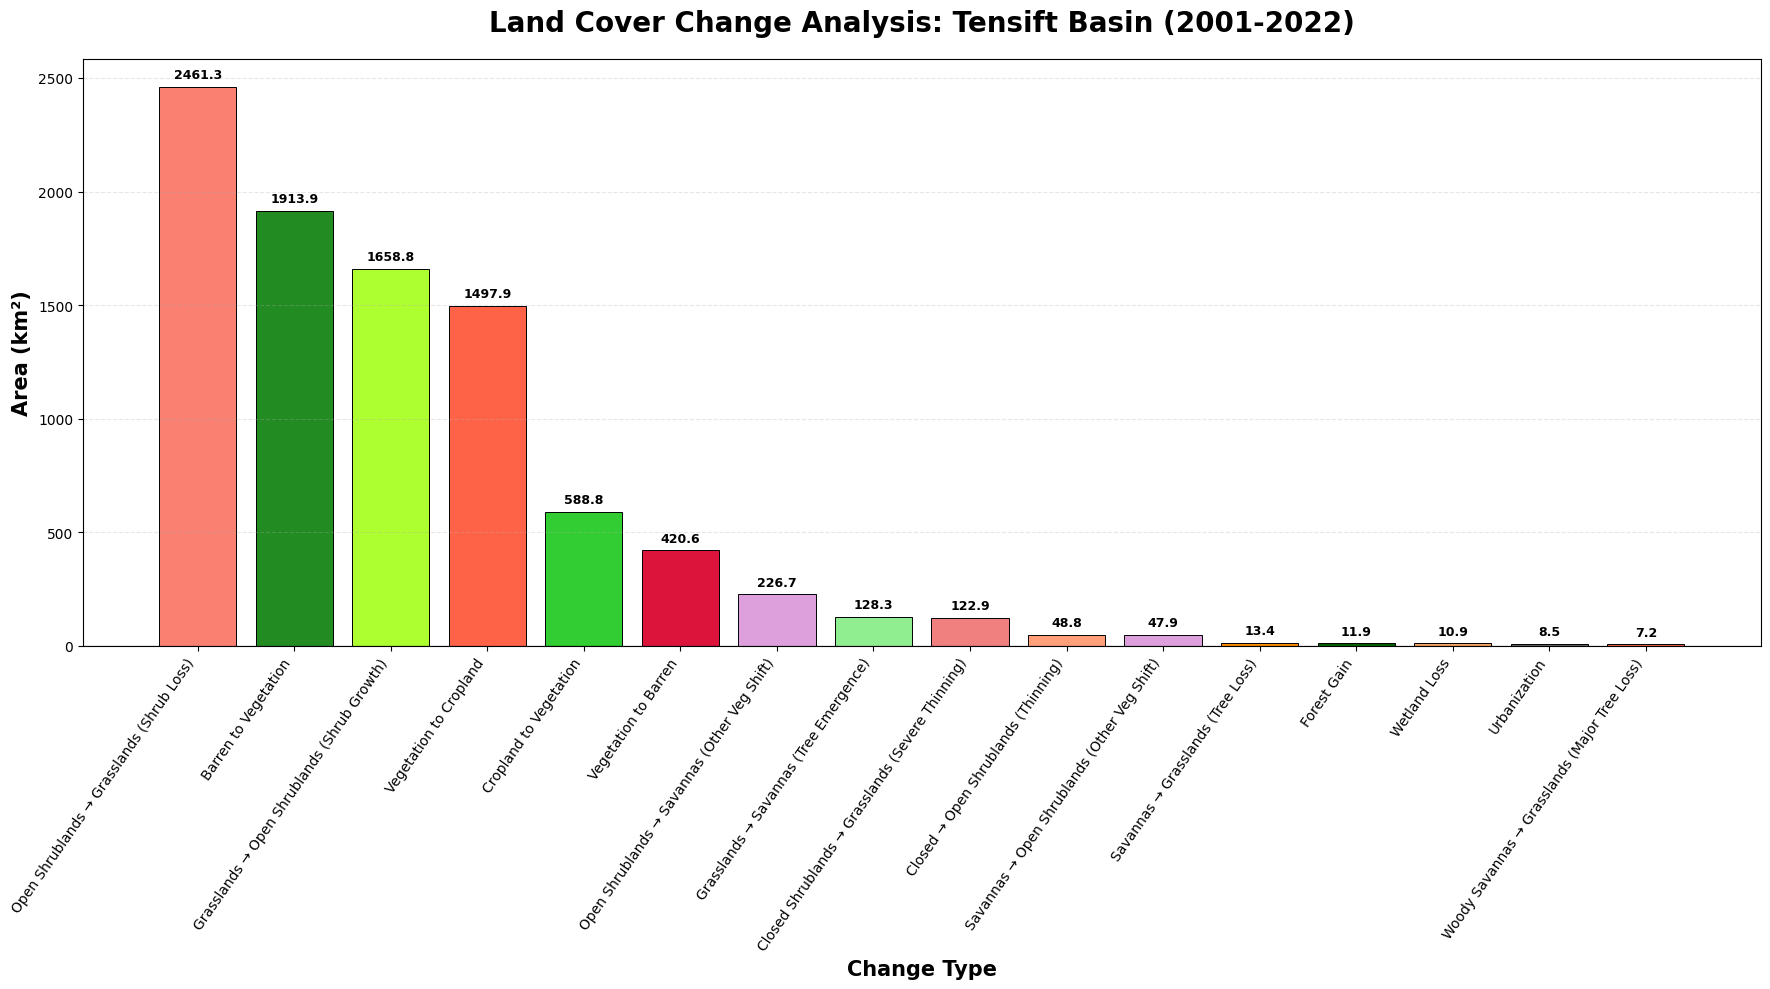


MAJOR LAND COVER CHANGES: TENSIFT BASIN (2001-2022)

Displayed Changed Area: 9167.72 km²
Total Changed Area: 9195.65 km²
Percentage Shown: 99.7%

MAJOR VEGETATION GAINS (Potential Tree Planting Impact):
  Forest Gain                                       :    11.93 km² ✓
  Barren to Vegetation                              :  1913.88 km² ✓
  Cropland to Vegetation                            :   588.78 km² ✓

VEGETATION DENSIFICATION (Early Tree/Shrub Establishment):
  Grasslands → Open Shrublands (Shrub Growth)       :  1658.79 km² ✓
  Grasslands → Savannas (Tree Emergence)            :   128.33 km² ✓
  Open → Closed Shrublands (Densification)          :     5.10 km² (< 7.1 km²)
  Grasslands → Woody Savannas (Tree Growth)         :     1.91 km² (< 7.1 km²)
  Grasslands → Closed Shrublands (Dense Shrubs)     :     1.49 km² (< 7.1 km²)

  → TOTAL POSITIVE VEGETATION CHANGE: 4310.22 km²

MAJOR VEGETATION LOSSES:
  Vegetation to Barren                              :   420.60 km² ✓
  Cropla

NameError: name 'veg_gain' is not defined

In [ ]:
# --- Create comprehensive bar chart with vegetation shifts broken down ---
# Filter out changes < 7.1 km²

def detailed_classify_change(row):
    """Classify all changes with vegetation shifts broken down"""
    from_code = [k for k, v in MODIS_CLASSES.items() if v == row['from_class']]
    to_code = [k for k, v in MODIS_CLASSES.items() if v == row['to_class']]

    if not from_code or not to_code:
        return 'Unknown'

    from_code = from_code[0]
    to_code = to_code[0]
    from_class = row['from_class']
    to_class = row['to_class']

    # Forest changes
    if from_code in forest_classes and to_code not in forest_classes:
        return 'Forest Loss'
    elif from_code not in forest_classes and to_code in forest_classes:
        return 'Forest Gain'

    # Barren land changes
    elif from_code in barren_classes and to_code in crop_classes:
        return 'Barren to Cropland'
    elif from_code in barren_classes and to_code in shrub_grass_classes:
        return 'Barren to Vegetation'
    elif from_code in crop_classes and to_code in barren_classes:
        return 'Cropland to Barren'
    elif from_code in shrub_grass_classes and to_code in barren_classes:
        return 'Vegetation to Barren'

    # Cropland changes
    elif from_code in shrub_grass_classes and to_code in crop_classes:
        return 'Vegetation to Cropland'
    elif from_code in crop_classes and to_code in shrub_grass_classes:
        return 'Cropland to Vegetation'

    # Urban changes
    elif to_code == 13:
        return 'Urbanization'
    elif from_code == 13:
        return 'Urban Abandonment'

    # Water changes
    elif to_code == 17:
        return 'Conversion to Water'
    elif from_code == 17:
        return 'Water to Land'

    # Wetland changes
    elif 'Wetland' in to_class:
        return 'Wetland Expansion'
    elif 'Wetland' in from_class:
        return 'Wetland Loss'

    # DETAILED VEGETATION TYPE SHIFTS
    # Densification (positive for trees)
    elif from_class == 'Open Shrublands' and to_class == 'Closed Shrublands':
        return 'Open → Closed Shrublands (Densification)'
    elif from_class == 'Grasslands' and to_class == 'Savannas':
        return 'Grasslands → Savannas (Tree Emergence)'
    elif from_class == 'Savannas' and to_class == 'Woody Savannas':
        return 'Savannas → Woody Savannas (More Trees)'
    elif from_class == 'Grasslands' and to_class == 'Woody Savannas':
        return 'Grasslands → Woody Savannas (Tree Growth)'
    elif from_class == 'Open Shrublands' and to_class == 'Woody Savannas':
        return 'Open Shrublands → Woody Savannas (Trees)'
    elif from_class == 'Grasslands' and to_class == 'Open Shrublands':
        return 'Grasslands → Open Shrublands (Shrub Growth)'
    elif from_class == 'Grasslands' and to_class == 'Closed Shrublands':
        return 'Grasslands → Closed Shrublands (Dense Shrubs)'

    # Thinning (negative - vegetation becoming sparser)
    elif from_class == 'Closed Shrublands' and to_class == 'Open Shrublands':
        return 'Closed → Open Shrublands (Thinning)'
    elif from_class == 'Woody Savannas' and to_class == 'Savannas':
        return 'Woody Savannas → Savannas (Tree Loss)'
    elif from_class == 'Savannas' and to_class == 'Grasslands':
        return 'Savannas → Grasslands (Tree Loss)'
    elif from_class == 'Woody Savannas' and to_class == 'Grasslands':
        return 'Woody Savannas → Grasslands (Major Tree Loss)'
    elif from_class == 'Woody Savannas' and to_class == 'Open Shrublands':
        return 'Woody Savannas → Open Shrublands (Degradation)'
    elif from_class == 'Closed Shrublands' and to_class == 'Grasslands':
        return 'Closed Shrublands → Grasslands (Severe Thinning)'
    elif from_class == 'Open Shrublands' and to_class == 'Grasslands':
        return 'Open Shrublands → Grasslands (Shrub Loss)'

    # Other vegetation shifts (lateral - not clearly positive or negative)
    elif from_code in shrub_grass_classes and to_code in shrub_grass_classes:
        return f'{from_class} → {to_class} (Other Veg Shift)'

    # Cropland mosaics
    elif 'Mosaic' in to_class and 'Mosaic' not in from_class:
        return 'To Cropland Mosaic'
    elif 'Mosaic' in from_class and 'Mosaic' not in to_class:
        return 'From Cropland Mosaic'

    # Everything else
    else:
        return 'Other Miscellaneous'

# Apply detailed classification
changes_only['detailed_type'] = changes_only.apply(detailed_classify_change, axis=1)

# Aggregate by detailed change type
all_changes_detailed = changes_only.groupby('detailed_type')['area_km2'].sum().sort_values(ascending=False)

# FILTER: Keep only changes >= 7.1 km²
AREA_THRESHOLD = 7.1
all_changes_filtered = all_changes_detailed[all_changes_detailed >= AREA_THRESHOLD]

print(f"\n{'='*80}")
print(f"Filtering changes > 7 km²")
print(f"Showing {len(all_changes_filtered)} out of {len(all_changes_detailed)} change types")
print(f"Displayed area: {all_changes_filtered.sum():.2f} km² out of {all_changes_detailed.sum():.2f} km² total")
print(f"{'='*80}\n")

# Create the comprehensive bar chart
fig, ax = plt.subplots(figsize=(18, 10))

# Define colors for each category with more nuanced greens for vegetation densification
color_mapping = {
    # Major vegetation gains (dark greens)
    'Forest Gain': '#006400',                                      # Dark green
    'Barren to Vegetation': '#228B22',                             # Forest green
    'Cropland to Vegetation': '#32CD32',                           # Lime green

    # Vegetation densification (light to medium greens)
    'Grasslands → Savannas (Tree Emergence)': '#90EE90',          # Light green
    'Savannas → Woody Savannas (More Trees)': '#7CFC00',          # Lawn green
    'Grasslands → Woody Savannas (Tree Growth)': '#7FFF00',       # Chartreuse
    'Open → Closed Shrublands (Densification)': '#00FA9A',        # Medium spring green
    'Open Shrublands → Woody Savannas (Trees)': '#98FB98',        # Pale green
    'Grasslands → Open Shrublands (Shrub Growth)': '#ADFF2F',     # Green yellow
    'Grasslands → Closed Shrublands (Dense Shrubs)': '#9ACD32',   # Yellow green

    # Major vegetation losses (reds)
    'Forest Loss': '#8B0000',                                      # Dark red
    'Vegetation to Barren': '#DC143C',                             # Crimson
    'Cropland to Barren': '#FF4500',                               # Orange red
    'Vegetation to Cropland': '#FF6347',                           # Tomato

    # Vegetation thinning (light to medium reds/oranges)
    'Closed → Open Shrublands (Thinning)': '#FFA07A',             # Light salmon
    'Woody Savannas → Savannas (Tree Loss)': '#FF7F50',           # Coral
    'Savannas → Grasslands (Tree Loss)': '#FF8C00',               # Dark orange
    'Woody Savannas → Grasslands (Major Tree Loss)': '#FF6347',   # Tomato
    'Woody Savannas → Open Shrublands (Degradation)': '#CD5C5C',  # Indian red
    'Closed Shrublands → Grasslands (Severe Thinning)': '#F08080', # Light coral
    'Open Shrublands → Grasslands (Shrub Loss)': '#FA8072',       # Salmon

    # Cropland changes (yellows/golds)
    'Barren to Cropland': '#FFD700',                               # Gold

    # Urban changes (grays)
    'Urbanization': '#696969',                                     # Dim gray
    'Urban Abandonment': '#C0C0C0',                                # Silver

    # Water changes (blues)
    'Conversion to Water': '#4682B4',                              # Steel blue
    'Water to Land': '#87CEEB',                                    # Sky blue

    # Wetland changes (teals)
    'Wetland Expansion': '#20B2AA',                                # Light sea green
    'Wetland Loss': '#F4A460',                                     # Sandy brown

    # Cropland mosaics (khakis)
    'To Cropland Mosaic': '#DAA520',                               # Goldenrod
    'From Cropland Mosaic': '#F0E68C',                             # Khaki

    # Other (grays)
    'Other Miscellaneous': '#A9A9A9',                              # Dark gray
    'Unknown': '#778899'                                           # Light slate gray
}

# Get colors for bars, with default for any unmapped categories
bar_colors = []
for cat in all_changes_filtered.index:
    if cat in color_mapping:
        bar_colors.append(color_mapping[cat])
    elif 'Other Veg Shift' in cat:
        bar_colors.append('#DDA0DD')  # Plum for other lateral shifts
    else:
        bar_colors.append('#CCCCCC')  # Light gray default

# Create bar chart
bars = ax.bar(range(len(all_changes_filtered)), all_changes_filtered.values,
              color=bar_colors, edgecolor='black', linewidth=0.7)

# Customize the plot
ax.set_title(f'Land Cover Change Analysis: Tensift Basin (2001-2022)',
             fontsize=20, fontweight='bold', pad=20)
ax.set_xlabel('Change Type', fontsize=15, fontweight='bold')
ax.set_ylabel('Area (km²)', fontsize=15, fontweight='bold')
ax.set_xticks(range(len(all_changes_filtered)))
ax.set_xticklabels(all_changes_filtered.index, rotation=55, ha='right', fontsize=10)
ax.grid(True, alpha=0.3, axis='y', linestyle='--')

# Add value labels on bars
for i, (cat, v) in enumerate(all_changes_filtered.items()):
    ax.text(i, v + max(all_changes_filtered.values)*0.01, f'{v:.1f}',
            ha='center', va='bottom', fontweight='bold', fontsize=9)

# Add a horizontal line at y=0 for reference
ax.axhline(y=0, color='black', linestyle='-', linewidth=0.8)

# Adjust layout to prevent label cutoff
plt.tight_layout()
plt.savefig('tensift_major_changes_detailed.png', dpi=300, bbox_inches='tight')
plt.show()

# Print detailed summary with categorization (using filtered data)
print("\n" + "="*80)
print(f"MAJOR LAND COVER CHANGES: TENSIFT BASIN (2001-2022)")
print("="*80)

print(f"\nDisplayed Changed Area: {all_changes_filtered.sum():.2f} km²")
print(f"Total Changed Area: {all_changes_detailed.sum():.2f} km²")
print(f"Percentage Shown: {(all_changes_filtered.sum()/all_changes_detailed.sum()*100):.1f}%\n")

# Categorize for summary (using ALL data, not just filtered)
print("="*80)
print("MAJOR VEGETATION GAINS (Potential Tree Planting Impact):")
print("="*80)
major_gains = ['Forest Gain', 'Barren to Vegetation', 'Cropland to Vegetation']
densification = [c for c in all_changes_detailed.index if
                 'Tree Emergence' in c or 'More Trees' in c or 'Tree Growth' in c or
                 'Densification' in c or 'Shrub Growth' in c or 'Dense Shrubs' in c]

for cat in major_gains:
    if cat in all_changes_detailed:
        shown = " ✓" if cat in all_changes_filtered.index else " (< 7.1 km²)"
        print(f"  {cat:50s}: {all_changes_detailed[cat]:8.2f} km²{shown}")

print("\nVEGETATION DENSIFICATION (Early Tree/Shrub Establishment):")
for cat in densification:
    shown = " ✓" if cat in all_changes_filtered.index else " (< 7.1 km²)"
    print(f"  {cat:50s}: {all_changes_detailed[cat]:8.2f} km²{shown}")

total_positive = sum([all_changes_detailed.get(c, 0) for c in major_gains + densification])
print(f"\n  → TOTAL POSITIVE VEGETATION CHANGE: {total_positive:.2f} km²")

print("\n" + "="*80)
print("MAJOR VEGETATION LOSSES:")
print("="*80)
major_losses = ['Forest Loss', 'Vegetation to Barren', 'Cropland to Barren', 'Vegetation to Cropland']
thinning = [c for c in all_changes_detailed.index if
            'Thinning' in c or 'Tree Loss' in c or 'Degradation' in c or
            'Shrub Loss' in c or 'Severe Thinning' in c]

for cat in major_losses:
    if cat in all_changes_detailed:
        shown = " ✓" if cat in all_changes_filtered.index else " (< 7.1 km²)"
        print(f"  {cat:50s}: {all_changes_detailed[cat]:8.2f} km²{shown}")

print("\nVEGETATION THINNING (Tree/Shrub Loss):")
for cat in thinning:
    shown = " ✓" if cat in all_changes_filtered.index else " (< 7.1 km²)"
    print(f"  {cat:50s}: {all_changes_detailed[cat]:8.2f} km²{shown}")

total_negative = sum([all_changes_detailed.get(c, 0) for c in major_losses + thinning])
print(f"\n  → TOTAL NEGATIVE VEGETATION CHANGE: {total_negative:.2f} km²")

print("\n" + "="*80)
print("NET VEGETATION CHANGE:")
print("="*80)
net_veg_change = total_positive - total_negative
print(f"  Net Change: {net_veg_change:+.2f} km² ", end="")
if net_veg_change > 0:
    print("✓ POSITIVE - Vegetation is increasing!")
else:
    print("✗ NEGATIVE - Vegetation is decreasing")

print("\n" + "="*80)
print("OTHER MAJOR CHANGES:")
print("="*80)

other_cats = ['Urbanization', 'Conversion to Water', 'Water to Land',
              'Barren to Cropland', 'Wetland Expansion', 'Wetland Loss',
              'To Cropland Mosaic', 'From Cropland Mosaic', 'Urban Abandonment']

for cat in other_cats:
    if cat in all_changes_detailed:
        shown = " ✓" if cat in all_changes_filtered.index else " (< 7.1 km²)"
        print(f"  {cat:50s}: {all_changes_detailed[cat]:8.2f} km²{shown}")

print("\n" + "="*80)


# Pie chart of gains vs losses
gain_loss_data = {
    'Vegetation Gain': veg_gain,
    'Vegetation Loss': veg_loss
}
colors_pie = ['#2ca02c', '#d62728']
axes[0].pie(gain_loss_data.values(), labels=gain_loss_data.keys(), autopct='%1.1f%%',
            colors=colors_pie, startangle=90, textprops={'fontsize': 12, 'fontweight': 'bold'})
axes[0].set_title('Vegetation Gain vs Loss', fontsize=14, fontweight='bold')

# Bar chart showing net change
axes[1].bar(['Net Vegetation Change'], [net_change],
            color='green' if net_change > 0 else 'red', width=0.5)
axes[1].axhline(y=0, color='black', linestyle='-', linewidth=0.5)
axes[1].set_ylabel('Area (km²)', fontsize=12)
axes[1].set_title('Net Vegetation Change (2001-2022)', fontsize=14, fontweight='bold')
axes[1].grid(True, alpha=0.3, axis='y')
axes[1].text(0, net_change + abs(net_change)*0.05, f'{net_change:.1f} km²',
             ha='center', va='bottom' if net_change > 0 else 'top',
             fontweight='bold', fontsize=12)

plt.tight_layout()
plt.savefig('tensift_net_change.png', dpi=300, bbox_inches='tight')
plt.show()

print(f"\n=== NET VEGETATION CHANGE ===")
print(f"Vegetation Gain: {veg_gain:.2f} km²")
print(f"Vegetation Loss: {veg_loss:.2f} km²")
print(f"Net Change: {net_change:.2f} km² ({'GAIN' if net_change > 0 else 'LOSS'})")

# Save detailed transitions
changes_only.to_csv('tensift_landcover_transitions_2001_2022.csv', index=False)
print("\n✓ Detailed transitions saved to CSV files")



# Save detailed results
summary_detailed = pd.DataFrame({
    'Change Type': all_changes_detailed.index,
    'Area (km²)': all_changes_detailed.values,
    'Percentage of Total': (all_changes_detailed.values / all_changes_detailed.sum() * 100),
    'Shown in Chart': all_changes_detailed.index.isin(all_changes_filtered.index)
})
summary_detailed.to_csv('tensift_all_changes_with_filter.csv', index=False)
print("\n✓ Complete summary (all changes) saved to 'tensift_all_changes_with_filter.csv'")
print(f"✓ Chart (changes ≥ {AREA_THRESHOLD} km²) saved to 'tensift_major_changes_detailed.png'")

## MODIS NDVI

Processing 2000...
Processing 2001...
Processing 2002...
Processing 2003...
Processing 2004...
Processing 2005...
Processing 2006...
Processing 2007...
Processing 2008...
Processing 2009...
Processing 2010...
Processing 2011...
Processing 2012...
Processing 2013...
Processing 2014...
Processing 2015...
Processing 2016...
Processing 2017...
Processing 2018...
Processing 2019...
Processing 2020...
Processing 2021...
Processing 2022...
Processing 2023...
Processing 2024...


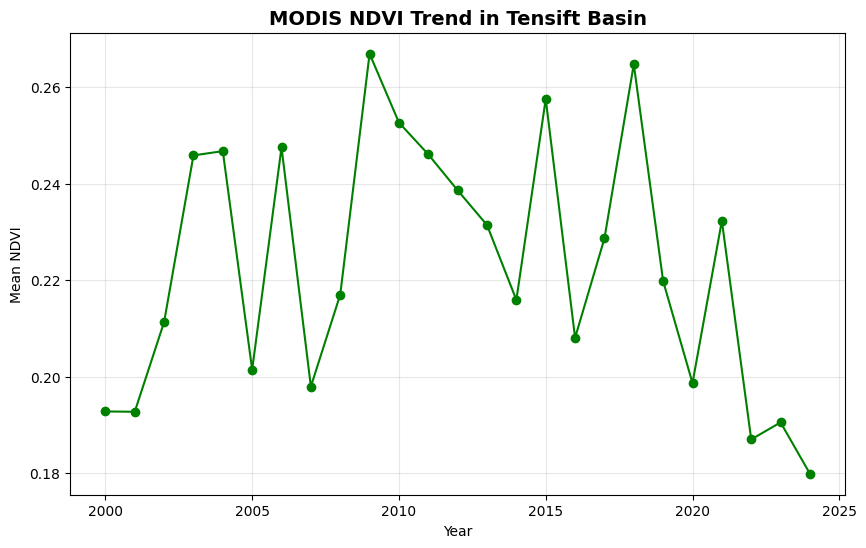

✓ MODIS NDVI results saved to CSV


In [ ]:
# --- MODIS NDVI (16-day or monthly) ---

def get_modis_ndvi(year, geometry):
    """
    Get mean NDVI for a year from MODIS MOD13Q1 (16-day, 250m resolution)
    """
    # MOD13Q1: Terra MODIS 16-day NDVI, 250m
    collection = ee.ImageCollection('MODIS/061/MOD13Q1') \
        .filterDate(f'{year}-01-01', f'{year}-12-31') \
        .select('NDVI')  # NDVI band

    # Convert scaled integer (0-10000) to float (0-1)
    def scale(image):
        return image.multiply(0.0001).copyProperties(image, image.propertyNames())

    collection = collection.map(scale)

    # Compute mean NDVI over the year
    mean_ndvi = collection.mean()

    # Reduce to your geometry
    stats = mean_ndvi.reduceRegion(
        reducer=ee.Reducer.mean(),
        geometry=geometry,
        scale=250,
        maxPixels=1e13
    )

    return stats.get('NDVI').getInfo()


# --- Collect NDVI data for all years ---
print("Collecting MODIS NDVI data...")
ndvi_results = []

for year in YEARS:
    print(f"Processing {year}...")
    try:
        ndvi = get_modis_ndvi(year, basin_geom)
        ndvi_results.append({'year': year, 'mean_ndvi': ndvi})
    except Exception as e:
        print(f"Error processing {year}: {e}")
        ndvi_results.append({'year': year, 'mean_ndvi': None})

# Convert to DataFrame
ndvi_df = pd.DataFrame(ndvi_results)

# --- VISUALIZATION ---
plt.figure(figsize=(10, 6))
plt.plot(ndvi_df['year'], ndvi_df['mean_ndvi'], 'o-', color='green', markersize=6)
plt.title("MODIS NDVI Trend in Tensift Basin", fontsize=14, fontweight='bold')
plt.xlabel("Year")
plt.ylabel("Mean NDVI")
plt.grid(alpha=0.3)
plt.show()

# Save to CSV
ndvi_df.to_csv('tensift_ndvi_modis.csv', index=False)
print("✓ MODIS NDVI results saved to CSV")


In [ ]:
# --- MODIS NDVI Change Analysis for Tensift Basin ---

import geemap
import ee
import matplotlib.pyplot as plt

print("Creating MODIS NDVI change maps...")

# Define years for comparison
START_YEAR = 2017
END_YEAR = 2024

# --- Function to get annual mean NDVI from MODIS ---
def get_modis_annual_ndvi(year, geometry):
    """
    Get annual mean NDVI from MOD13Q1 (Terra MODIS, 16-day, 250m)
    """
    collection = ee.ImageCollection('MODIS/061/MOD13Q1') \
        .filterBounds(geometry) \
        .filterDate(f'{year}-01-01', f'{year}-12-31') \
        .select('NDVI')

    # Scale NDVI to 0-1
    def scale(image):
        return image.multiply(0.0001).copyProperties(image, image.propertyNames())

    ndvi_scaled = collection.map(scale)

    # Annual mean NDVI
    ndvi_mean = ndvi_scaled.mean()

    return ndvi_mean

# --- Get NDVI for start and end years ---
print(f"Processing MODIS NDVI for {START_YEAR}...")
ndvi_start = get_modis_annual_ndvi(START_YEAR, basin_geom)

print(f"Processing MODIS NDVI for {END_YEAR}...")
ndvi_end = get_modis_annual_ndvi(END_YEAR, basin_geom)

# NDVI change
ndvi_change = ndvi_end.subtract(ndvi_start)

# --- Create interactive map ---
Map = geemap.Map()
Map.centerObject(basin_geom, 9)

# Add basemap
Map.add_basemap('SATELLITE')

# Add Tensift basin boundary
Map.addLayer(basin_geom, {'color': 'yellow', 'fillColor': '00000000'}, 'Tensift Basin')

# Visualization parameters
ndvi_vis = {
    'min': 0,
    'max': 0.8,
    'palette': ['brown', 'yellow', 'lightgreen', 'darkgreen']
}

change_vis = {
    'min': -0.3,
    'max': 0.3,
    'palette': ['red', 'orange', 'white', 'lightgreen', 'darkgreen']
}

# Add NDVI layers
Map.addLayer(ndvi_start.clip(basin_geom), ndvi_vis, f'NDVI {START_YEAR}', False)
Map.addLayer(ndvi_end.clip(basin_geom), ndvi_vis, f'NDVI {END_YEAR}', False)
Map.addLayer(ndvi_change.clip(basin_geom), change_vis, f'NDVI Change ({START_YEAR}-{END_YEAR})', True)

# Add legend
legend_keys = ['Large Decrease', 'Slight Decrease', 'No Change', 'Slight Increase', 'Large Increase']
legend_colors = ['#FF0000', '#FFA500', '#FFFFFF', '#90EE90', '#006400']

Map.add_legend(
    title=f'NDVI Change ({START_YEAR}-{END_YEAR})',
    keys=legend_keys,
    colors=legend_colors,
    position='bottomright'
)

# Display
display(Map)


Creating MODIS NDVI change maps...
Processing MODIS NDVI for 2017...
Processing MODIS NDVI for 2024...


Map(center=[31.530532507751857, -8.565848432724456], controls=(WidgetControl(options=['position', 'transparent…


Calculating NDVI change statistics (optimized)...
Running analysis at 100m resolution for faster computation...
✓ Statistics calculated successfully


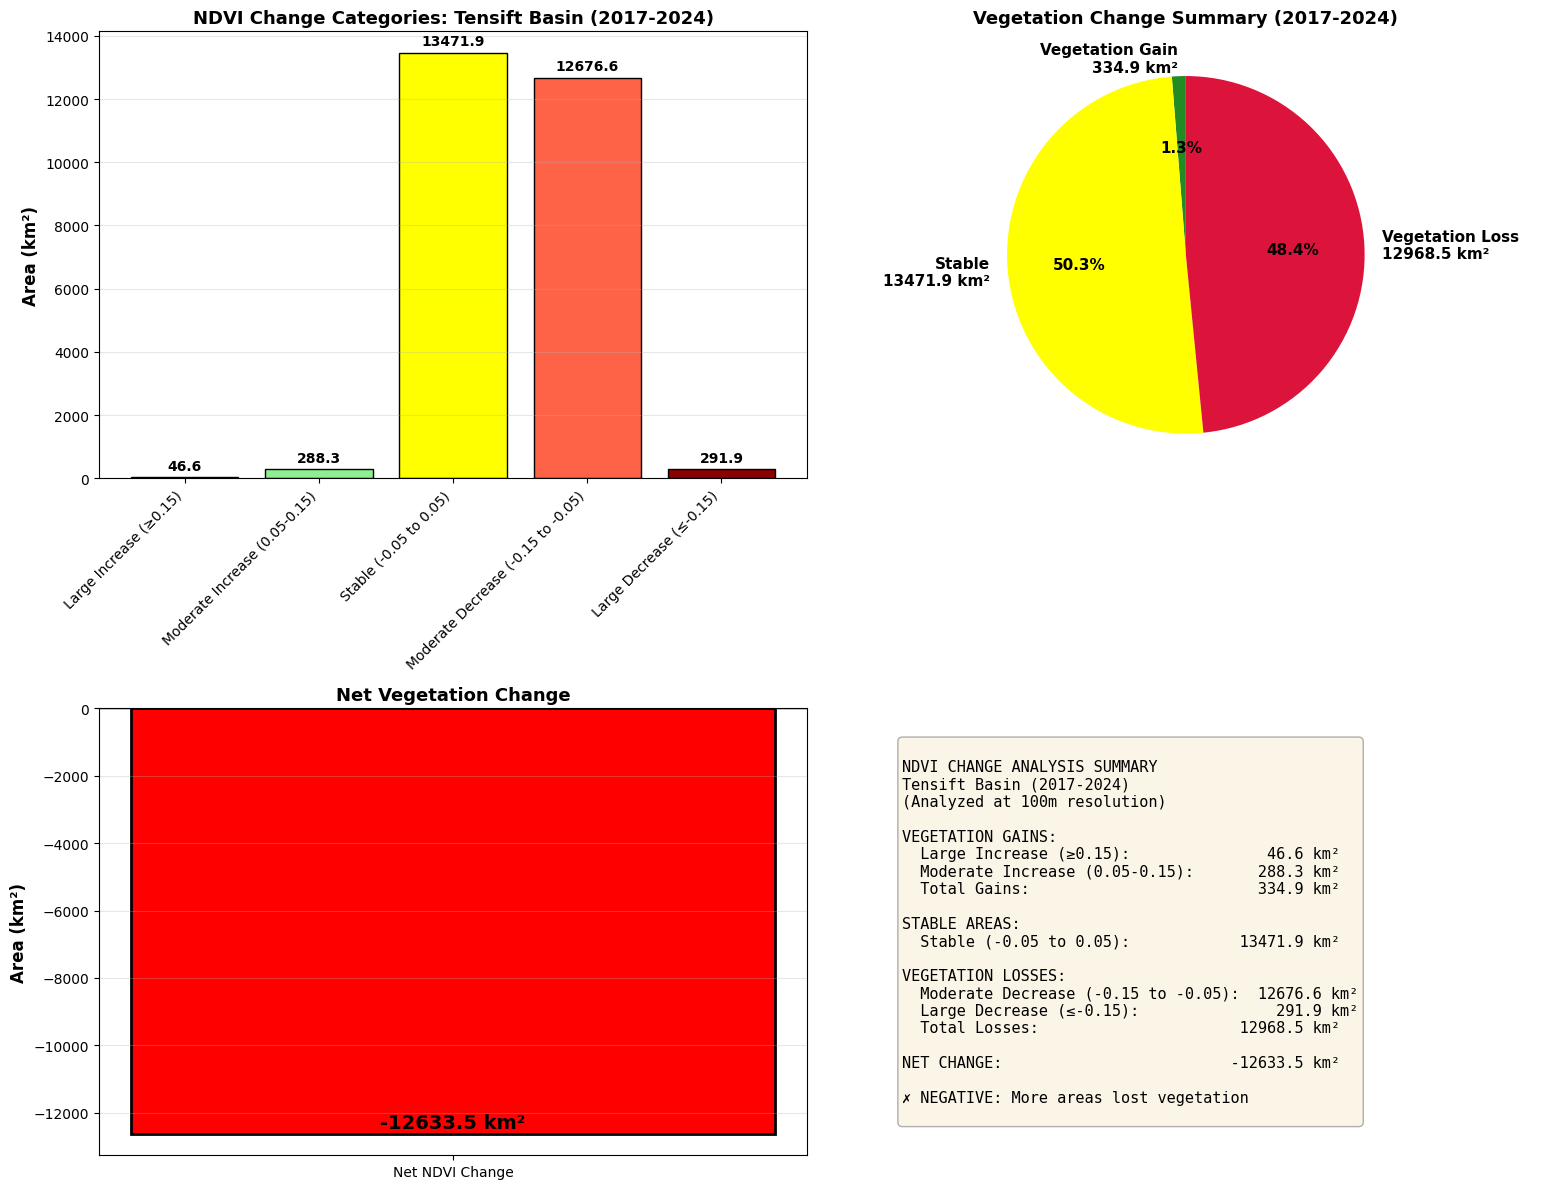


NDVI CHANGE ANALYSIS: TENSIFT BASIN (2017-2024)

VEGETATION GAINS:
  Large Increase (≥0.15):               46.6 km²
  Moderate Increase (0.05-0.15):       288.3 km²
  → Total Gains:                       334.9 km²

STABLE AREAS:
  Stable (-0.05 to 0.05):            13471.9 km²

VEGETATION LOSSES:
  Moderate Decrease (-0.15 to -0.05):  12676.6 km²
  Large Decrease (≤-0.15):             291.9 km²
  → Total Losses:                    12968.5 km²

NET CHANGE:
  Net Vegetation Change:            -12633.5 km²
  ✗ NEGATIVE - Vegetation is decreasing



In [ ]:

# --- Optimized NDVI Change Statistics ---
print("\nCalculating NDVI change statistics (optimized)...")

# Use 100m scale instead of 10m for faster computation
ANALYSIS_SCALE = 100  # meters

# Define vegetation change categories - more efficient approach
def classify_ndvi_change_optimized(ndvi_change_image, geometry):
    """Classify NDVI changes into categories - optimized version"""

    # Create a single multi-band image with all categories
    large_increase = ndvi_change_image.gte(0.15).rename('large_increase')
    moderate_increase = ndvi_change_image.gte(0.05).And(ndvi_change_image.lt(0.15)).rename('moderate_increase')
    stable = ndvi_change_image.gte(-0.05).And(ndvi_change_image.lt(0.05)).rename('stable')
    moderate_decrease = ndvi_change_image.lt(-0.05).And(ndvi_change_image.gte(-0.15)).rename('moderate_decrease')
    large_decrease = ndvi_change_image.lt(-0.15).rename('large_decrease')

    # Combine into one image
    categories = large_increase.addBands([moderate_increase, stable, moderate_decrease, large_decrease])

    # Calculate pixel area once
    pixel_area_km2 = ee.Image.pixelArea().divide(1e6)

    # Multiply categories by area and sum
    area_by_category = categories.multiply(pixel_area_km2)

    # Single reduceRegion call for all categories
    stats = area_by_category.reduceRegion(
        reducer=ee.Reducer.sum(),
        geometry=geometry,
        scale=ANALYSIS_SCALE,  # Use 100m instead of 10m
        maxPixels=1e10,
        bestEffort=True  # Allow approximation if needed
    )

    return stats

print(f"Running analysis at {ANALYSIS_SCALE}m resolution for faster computation...")
change_stats_result = classify_ndvi_change_optimized(ndvi_change, basin_geom)

# Parse results
result_dict = change_stats_result.getInfo()
change_areas = {
    'Large Increase (≥0.15)': result_dict.get('large_increase', 0),
    'Moderate Increase (0.05-0.15)': result_dict.get('moderate_increase', 0),
    'Stable (-0.05 to 0.05)': result_dict.get('stable', 0),
    'Moderate Decrease (-0.15 to -0.05)': result_dict.get('moderate_decrease', 0),
    'Large Decrease (≤-0.15)': result_dict.get('large_decrease', 0)
}

print("✓ Statistics calculated successfully")

# --- Visualize statistics ---
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Bar chart of change categories
ax1 = axes[0, 0]
categories = list(change_areas.keys())
areas = list(change_areas.values())
colors = ['#006400', '#90EE90', '#FFFF00', '#FF6347', '#8B0000']

bars = ax1.bar(range(len(categories)), areas, color=colors, edgecolor='black', linewidth=1)
ax1.set_xticks(range(len(categories)))
ax1.set_xticklabels(categories, rotation=45, ha='right', fontsize=10)
ax1.set_ylabel('Area (km²)', fontsize=12, fontweight='bold')
ax1.set_title(f'NDVI Change Categories: Tensift Basin ({START_YEAR}-{END_YEAR})',
              fontsize=13, fontweight='bold')
ax1.grid(True, alpha=0.3, axis='y')

# Add value labels
for i, v in enumerate(areas):
    if v > 0:  # Only show label if there's area
        ax1.text(i, v + max(areas)*0.01, f'{v:.1f}', ha='center', va='bottom', fontweight='bold')

# 2. Pie chart of gains vs losses
ax2 = axes[0, 1]
gains = change_areas.get('Large Increase (≥0.15)', 0) + change_areas.get('Moderate Increase (0.05-0.15)', 0)
losses = change_areas.get('Large Decrease (≤-0.15)', 0) + change_areas.get('Moderate Decrease (-0.15 to -0.05)', 0)
stable_area = change_areas.get('Stable (-0.05 to 0.05)', 0)

pie_data = [gains, stable_area, losses]
pie_labels = [f'Vegetation Gain\n{gains:.1f} km²',
              f'Stable\n{stable_area:.1f} km²',
              f'Vegetation Loss\n{losses:.1f} km²']
pie_colors = ['#228B22', '#FFFF00', '#DC143C']

# Remove zero values from pie chart
pie_data_filtered = [d for d in pie_data if d > 0]
pie_labels_filtered = [l for d, l in zip(pie_data, pie_labels) if d > 0]
pie_colors_filtered = [c for d, c in zip(pie_data, pie_colors) if d > 0]

if pie_data_filtered:
    wedges, texts, autotexts = ax2.pie(pie_data_filtered, labels=pie_labels_filtered, autopct='%1.1f%%',
                                         colors=pie_colors_filtered, startangle=90,
                                         textprops={'fontsize': 11, 'fontweight': 'bold'})
    ax2.set_title(f'Vegetation Change Summary ({START_YEAR}-{END_YEAR})',
                  fontsize=13, fontweight='bold')

# 3. Net change visualization
ax3 = axes[1, 0]
net_change = gains - losses
ax3.bar(['Net NDVI Change'], [net_change],
        color='green' if net_change > 0 else 'red', width=0.5, edgecolor='black', linewidth=2)
ax3.axhline(y=0, color='black', linestyle='-', linewidth=1)
ax3.set_ylabel('Area (km²)', fontsize=12, fontweight='bold')
ax3.set_title('Net Vegetation Change', fontsize=13, fontweight='bold')
ax3.grid(True, alpha=0.3, axis='y')

if net_change != 0:
    ax3.text(0, net_change + abs(net_change)*0.05,
             f'{net_change:+.1f} km²',
             ha='center', va='bottom' if net_change > 0 else 'top',
             fontweight='bold', fontsize=14)

# 4. Summary table
ax4 = axes[1, 1]
ax4.axis('off')

# Create summary text
summary_text = f"""
NDVI CHANGE ANALYSIS SUMMARY
Tensift Basin ({START_YEAR}-{END_YEAR})
(Analyzed at {ANALYSIS_SCALE}m resolution)

VEGETATION GAINS:
  Large Increase (≥0.15):           {change_areas.get('Large Increase (≥0.15)', 0):>8.1f} km²
  Moderate Increase (0.05-0.15):    {change_areas.get('Moderate Increase (0.05-0.15)', 0):>8.1f} km²
  Total Gains:                      {gains:>8.1f} km²

STABLE AREAS:
  Stable (-0.05 to 0.05):           {stable_area:>8.1f} km²

VEGETATION LOSSES:
  Moderate Decrease (-0.15 to -0.05): {change_areas.get('Moderate Decrease (-0.15 to -0.05)', 0):>8.1f} km²
  Large Decrease (≤-0.15):            {change_areas.get('Large Decrease (≤-0.15)', 0):>8.1f} km²
  Total Losses:                     {losses:>8.1f} km²

NET CHANGE:                         {net_change:>+8.1f} km²

{'✓ POSITIVE: More areas gained vegetation!' if net_change > 0 else '✗ NEGATIVE: More areas lost vegetation'}
"""

ax4.text(0.1, 0.5, summary_text, fontsize=11, family='monospace',
         verticalalignment='center', bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.3))

plt.tight_layout()
plt.savefig('tensift_ndvi_change_analysis.png', dpi=300, bbox_inches='tight')
plt.show()

# --- Print summary ---
print("\n" + "="*80)
print(f"NDVI CHANGE ANALYSIS: TENSIFT BASIN ({START_YEAR}-{END_YEAR})")
print("="*80)

print("\nVEGETATION GAINS:")
print(f"  Large Increase (≥0.15):           {change_areas.get('Large Increase (≥0.15)', 0):8.1f} km²")
print(f"  Moderate Increase (0.05-0.15):    {change_areas.get('Moderate Increase (0.05-0.15)', 0):8.1f} km²")
print(f"  → Total Gains:                    {gains:8.1f} km²")

print("\nSTABLE AREAS:")
print(f"  Stable (-0.05 to 0.05):           {stable_area:8.1f} km²")

print("\nVEGETATION LOSSES:")
print(f"  Moderate Decrease (-0.15 to -0.05): {change_areas.get('Moderate Decrease (-0.15 to -0.05)', 0):8.1f} km²")
print(f"  Large Decrease (≤-0.15):          {change_areas.get('Large Decrease (≤-0.15)', 0):8.1f} km²")
print(f"  → Total Losses:                   {losses:8.1f} km²")

print("\nNET CHANGE:")
print(f"  Net Vegetation Change:            {net_change:+8.1f} km²")
if net_change > 0:
    print("  ✓ POSITIVE - Vegetation is increasing!")
else:
    print("  ✗ NEGATIVE - Vegetation is decreasing")

print("\n" + "="*80)


## NDVI Landsat-2

Creating Sentinel-2 NDVI change maps...
Processing NDVI for 2017...
Processing NDVI for 2024...


Map(center=[31.530532507751857, -8.565848432724456], controls=(WidgetControl(options=['position', 'transparent…


Calculating NDVI change statistics (optimized)...
Running analysis at 100m resolution for faster computation...
✓ Statistics calculated successfully


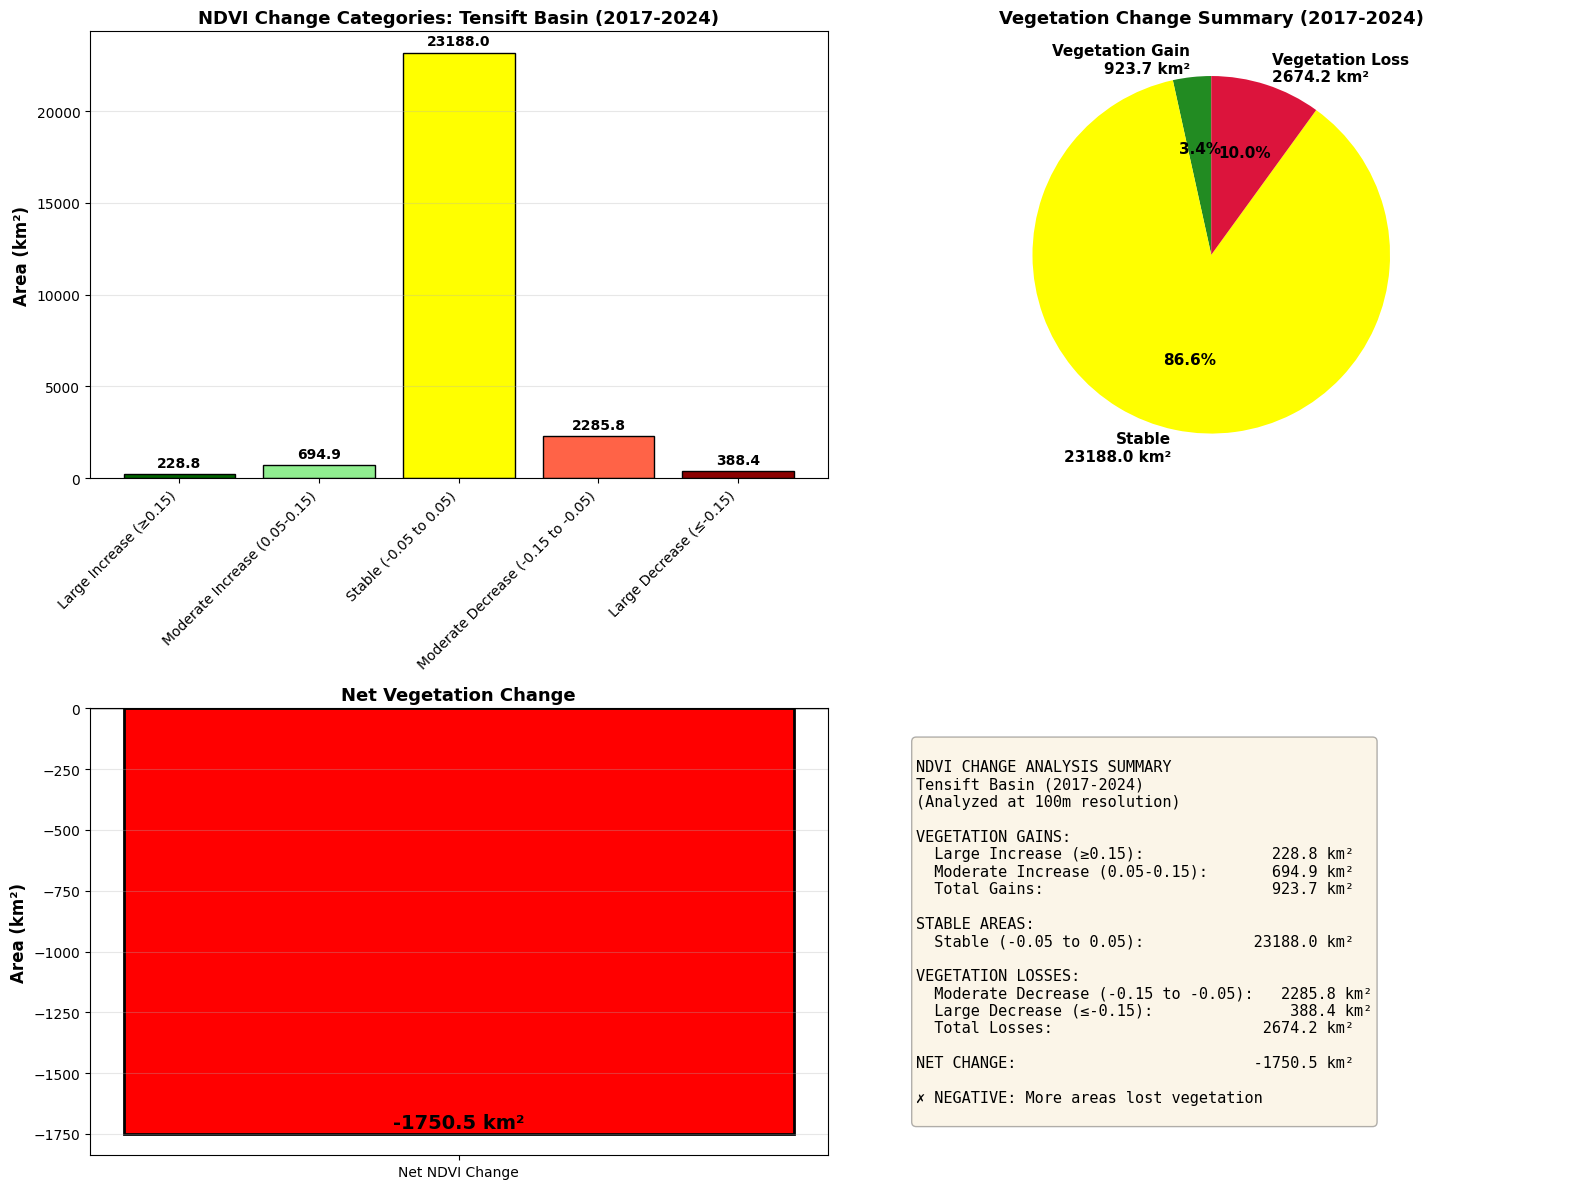


NDVI CHANGE ANALYSIS: TENSIFT BASIN (2017-2024)

VEGETATION GAINS:
  Large Increase (≥0.15):              228.8 km²
  Moderate Increase (0.05-0.15):       694.9 km²
  → Total Gains:                       923.7 km²

STABLE AREAS:
  Stable (-0.05 to 0.05):            23188.0 km²

VEGETATION LOSSES:
  Moderate Decrease (-0.15 to -0.05):   2285.8 km²
  Large Decrease (≤-0.15):             388.4 km²
  → Total Losses:                     2674.2 km²

NET CHANGE:
  Net Vegetation Change:             -1750.5 km²
  ✗ NEGATIVE - Vegetation is decreasing



NameError: name 'pd' is not defined

In [ ]:
# --- Sentinel-2 NDVI Change Analysis for Tensift Basin ---

import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import numpy as np
import pandas as pd


print("Creating Sentinel-2 NDVI change maps...")

# Define years for comparison
START_YEAR = 2017  # Sentinel-2 data starts ~2016
END_YEAR = 2024

# --- Function to get annual median NDVI ---
def get_annual_ndvi(year, geometry, months=None):
    """
    Get annual median NDVI from Sentinel-2
    months: optional list of months to analyze (e.g., [3,4,5] for spring)
    """
    if months:
        date_start = f'{year}-{months[0]:02d}-01'
        date_end = f'{year}-{months[-1]:02d}-30'
    else:
        date_start = f'{year}-01-01'
        date_end = f'{year}-12-31'

    # Filter Sentinel-2 data
    s2 = ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED') \
        .filterBounds(geometry) \
        .filterDate(date_start, date_end) \
        .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 20))

    # Calculate NDVI
    def add_ndvi(image):
        ndvi = image.normalizedDifference(['B8', 'B4']).rename('NDVI')
        return ndvi

    ndvi_collection = s2.map(add_ndvi)

    # Get median NDVI
    ndvi_median = ndvi_collection.median()

    return ndvi_median

# --- Get NDVI for start and end years ---
print(f"Processing NDVI for {START_YEAR}...")
ndvi_start = get_annual_ndvi(START_YEAR, basin_geom)

print(f"Processing NDVI for {END_YEAR}...")
ndvi_end = get_annual_ndvi(END_YEAR, basin_geom)

# Calculate NDVI change
ndvi_change = ndvi_end.subtract(ndvi_start)

# --- Create interactive map ---
Map = geemap.Map()
Map.centerObject(basin_geom, 9)

# Add basemap
Map.add_basemap('SATELLITE')

# Add Tensift basin boundary
Map.addLayer(basin_geom, {'color': 'yellow', 'fillColor': '00000000'}, 'Tensift Basin')

# NDVI visualization parameters
ndvi_vis = {
    'min': 0,
    'max': 0.8,
    'palette': ['brown', 'yellow', 'lightgreen', 'darkgreen']
}

# NDVI change visualization
change_vis = {
    'min': -0.3,
    'max': 0.3,
    'palette': ['red', 'orange', 'white', 'lightgreen', 'darkgreen']
}

# Add NDVI layers
Map.addLayer(ndvi_start.clip(basin_geom), ndvi_vis, f'NDVI {START_YEAR}', False)
Map.addLayer(ndvi_end.clip(basin_geom), ndvi_vis, f'NDVI {END_YEAR}', False)
Map.addLayer(ndvi_change.clip(basin_geom), change_vis, f'NDVI Change ({START_YEAR}-{END_YEAR})', True)

# Add legend for NDVI change
legend_keys = ['Large Decrease', 'Slight Decrease', 'No Change', 'Slight Increase', 'Large Increase']
legend_colors = ['#FF0000', '#FFA500', '#FFFFFF', '#90EE90', '#006400']

Map.add_legend(
    title=f'NDVI Change ({START_YEAR}-{END_YEAR})',
    keys=legend_keys,
    colors=legend_colors,
    position='bottomright'
)

# Display map
display(Map)

# --- Optimized NDVI Change Statistics ---
print("\nCalculating NDVI change statistics (optimized)...")

# Use 100m scale instead of 10m for faster computation
ANALYSIS_SCALE = 100  # meters

# Define vegetation change categories - more efficient approach
def classify_ndvi_change_optimized(ndvi_change_image, geometry):
    """Classify NDVI changes into categories - optimized version"""

    # Create a single multi-band image with all categories
    large_increase = ndvi_change_image.gte(0.15).rename('large_increase')
    moderate_increase = ndvi_change_image.gte(0.05).And(ndvi_change_image.lt(0.15)).rename('moderate_increase')
    stable = ndvi_change_image.gte(-0.05).And(ndvi_change_image.lt(0.05)).rename('stable')
    moderate_decrease = ndvi_change_image.lt(-0.05).And(ndvi_change_image.gte(-0.15)).rename('moderate_decrease')
    large_decrease = ndvi_change_image.lt(-0.15).rename('large_decrease')

    # Combine into one image
    categories = large_increase.addBands([moderate_increase, stable, moderate_decrease, large_decrease])

    # Calculate pixel area once
    pixel_area_km2 = ee.Image.pixelArea().divide(1e6)

    # Multiply categories by area and sum
    area_by_category = categories.multiply(pixel_area_km2)

    # Single reduceRegion call for all categories
    stats = area_by_category.reduceRegion(
        reducer=ee.Reducer.sum(),
        geometry=geometry,
        scale=ANALYSIS_SCALE,  # Use 100m instead of 10m
        maxPixels=1e10,
        bestEffort=True  # Allow approximation if needed
    )

    return stats

print(f"Running analysis at {ANALYSIS_SCALE}m resolution for faster computation...")
change_stats_result = classify_ndvi_change_optimized(ndvi_change, basin_geom)

# Parse results
result_dict = change_stats_result.getInfo()
change_areas = {
    'Large Increase (≥0.15)': result_dict.get('large_increase', 0),
    'Moderate Increase (0.05-0.15)': result_dict.get('moderate_increase', 0),
    'Stable (-0.05 to 0.05)': result_dict.get('stable', 0),
    'Moderate Decrease (-0.15 to -0.05)': result_dict.get('moderate_decrease', 0),
    'Large Decrease (≤-0.15)': result_dict.get('large_decrease', 0)
}

print("✓ Statistics calculated successfully")

# --- Visualize statistics ---
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Bar chart of change categories
ax1 = axes[0, 0]
categories = list(change_areas.keys())
areas = list(change_areas.values())
colors = ['#006400', '#90EE90', '#FFFF00', '#FF6347', '#8B0000']

bars = ax1.bar(range(len(categories)), areas, color=colors, edgecolor='black', linewidth=1)
ax1.set_xticks(range(len(categories)))
ax1.set_xticklabels(categories, rotation=45, ha='right', fontsize=10)
ax1.set_ylabel('Area (km²)', fontsize=12, fontweight='bold')
ax1.set_title(f'NDVI Change Categories: Tensift Basin ({START_YEAR}-{END_YEAR})',
              fontsize=13, fontweight='bold')
ax1.grid(True, alpha=0.3, axis='y')

# Add value labels
for i, v in enumerate(areas):
    if v > 0:  # Only show label if there's area
        ax1.text(i, v + max(areas)*0.01, f'{v:.1f}', ha='center', va='bottom', fontweight='bold')

# 2. Pie chart of gains vs losses
ax2 = axes[0, 1]
gains = change_areas.get('Large Increase (≥0.15)', 0) + change_areas.get('Moderate Increase (0.05-0.15)', 0)
losses = change_areas.get('Large Decrease (≤-0.15)', 0) + change_areas.get('Moderate Decrease (-0.15 to -0.05)', 0)
stable_area = change_areas.get('Stable (-0.05 to 0.05)', 0)

pie_data = [gains, stable_area, losses]
pie_labels = [f'Vegetation Gain\n{gains:.1f} km²',
              f'Stable\n{stable_area:.1f} km²',
              f'Vegetation Loss\n{losses:.1f} km²']
pie_colors = ['#228B22', '#FFFF00', '#DC143C']

# Remove zero values from pie chart
pie_data_filtered = [d for d in pie_data if d > 0]
pie_labels_filtered = [l for d, l in zip(pie_data, pie_labels) if d > 0]
pie_colors_filtered = [c for d, c in zip(pie_data, pie_colors) if d > 0]

if pie_data_filtered:
    wedges, texts, autotexts = ax2.pie(pie_data_filtered, labels=pie_labels_filtered, autopct='%1.1f%%',
                                         colors=pie_colors_filtered, startangle=90,
                                         textprops={'fontsize': 11, 'fontweight': 'bold'})
    ax2.set_title(f'Vegetation Change Summary ({START_YEAR}-{END_YEAR})',
                  fontsize=13, fontweight='bold')

# 3. Net change visualization
ax3 = axes[1, 0]
net_change = gains - losses
ax3.bar(['Net NDVI Change'], [net_change],
        color='green' if net_change > 0 else 'red', width=0.5, edgecolor='black', linewidth=2)
ax3.axhline(y=0, color='black', linestyle='-', linewidth=1)
ax3.set_ylabel('Area (km²)', fontsize=12, fontweight='bold')
ax3.set_title('Net Vegetation Change', fontsize=13, fontweight='bold')
ax3.grid(True, alpha=0.3, axis='y')

if net_change != 0:
    ax3.text(0, net_change + abs(net_change)*0.05,
             f'{net_change:+.1f} km²',
             ha='center', va='bottom' if net_change > 0 else 'top',
             fontweight='bold', fontsize=14)

# 4. Summary table
ax4 = axes[1, 1]
ax4.axis('off')

# Create summary text
summary_text = f"""
NDVI CHANGE ANALYSIS SUMMARY
Tensift Basin ({START_YEAR}-{END_YEAR})
(Analyzed at {ANALYSIS_SCALE}m resolution)

VEGETATION GAINS:
  Large Increase (≥0.15):           {change_areas.get('Large Increase (≥0.15)', 0):>8.1f} km²
  Moderate Increase (0.05-0.15):    {change_areas.get('Moderate Increase (0.05-0.15)', 0):>8.1f} km²
  Total Gains:                      {gains:>8.1f} km²

STABLE AREAS:
  Stable (-0.05 to 0.05):           {stable_area:>8.1f} km²

VEGETATION LOSSES:
  Moderate Decrease (-0.15 to -0.05): {change_areas.get('Moderate Decrease (-0.15 to -0.05)', 0):>8.1f} km²
  Large Decrease (≤-0.15):            {change_areas.get('Large Decrease (≤-0.15)', 0):>8.1f} km²
  Total Losses:                     {losses:>8.1f} km²

NET CHANGE:                         {net_change:>+8.1f} km²

{'✓ POSITIVE: More areas gained vegetation!' if net_change > 0 else '✗ NEGATIVE: More areas lost vegetation'}
"""

ax4.text(0.1, 0.5, summary_text, fontsize=11, family='monospace',
         verticalalignment='center', bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.3))

plt.tight_layout()
plt.savefig('tensift_ndvi_change_analysis.png', dpi=300, bbox_inches='tight')
plt.show()

# --- Print summary ---
print("\n" + "="*80)
print(f"NDVI CHANGE ANALYSIS: TENSIFT BASIN ({START_YEAR}-{END_YEAR})")
print("="*80)

print("\nVEGETATION GAINS:")
print(f"  Large Increase (≥0.15):           {change_areas.get('Large Increase (≥0.15)', 0):8.1f} km²")
print(f"  Moderate Increase (0.05-0.15):    {change_areas.get('Moderate Increase (0.05-0.15)', 0):8.1f} km²")
print(f"  → Total Gains:                    {gains:8.1f} km²")

print("\nSTABLE AREAS:")
print(f"  Stable (-0.05 to 0.05):           {stable_area:8.1f} km²")

print("\nVEGETATION LOSSES:")
print(f"  Moderate Decrease (-0.15 to -0.05): {change_areas.get('Moderate Decrease (-0.15 to -0.05)', 0):8.1f} km²")
print(f"  Large Decrease (≤-0.15):          {change_areas.get('Large Decrease (≤-0.15)', 0):8.1f} km²")
print(f"  → Total Losses:                   {losses:8.1f} km²")

print("\nNET CHANGE:")
print(f"  Net Vegetation Change:            {net_change:+8.1f} km²")
if net_change > 0:
    print("  ✓ POSITIVE - Vegetation is increasing!")
else:
    print("  ✗ NEGATIVE - Vegetation is decreasing")

print("\n" + "="*80)

# Save results
ndvi_summary = pd.DataFrame({
    'Category': list(change_areas.keys()),
    'Area (km²)': list(change_areas.values())
})
ndvi_summary.to_csv('tensift_ndvi_change_summary.csv', index=False)
print(f"\n✓ NDVI change summary saved (analyzed at {ANALYSIS_SCALE}m resolution)")
print("✓ Analysis chart saved to 'tensift_ndvi_change_analysis.png'")

# --- OPTIMIZED: Create time series of NDVI ---
print("\n" + "="*80)
print("Creating NDVI time series (optimized)...")
print("="*80)

years = list(range(2017, 2025))
ndvi_time_series = []

for year in years:
    print(f"Processing {year}...")
    ndvi = get_annual_ndvi(year, basin_geom)

    # Calculate mean NDVI at coarser scale
    stats = ndvi.reduceRegion(
        reducer=ee.Reducer.mean(),
        geometry=basin_geom,
        scale=100,  # 100m instead of 10m
        maxPixels=1e10,
        bestEffort=True
    )

    mean_ndvi = stats.getInfo().get('NDVI', None)
    if mean_ndvi is not None:
        ndvi_time_series.append({'year': year, 'mean_ndvi': mean_ndvi})

ndvi_ts_df = pd.DataFrame(ndvi_time_series)

# Plot time series
fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(ndvi_ts_df['year'], ndvi_ts_df['mean_ndvi'],
        marker='o', linewidth=2.5, markersize=10, color='darkgreen')

# Add trend line
z = np.polyfit(ndvi_ts_df['year'], ndvi_ts_df['mean_ndvi'], 1)
p = np.poly1d(z)
ax.plot(ndvi_ts_df['year'], p(ndvi_ts_df['year']),
        "r--", alpha=0.8, linewidth=2,
        label=f'Trend: {z[0]:.5f} NDVI/year')

ax.set_title('Average NDVI Trend: Tensift Basin (2017-2024)',
             fontsize=16, fontweight='bold')
ax.set_xlabel('Year', fontsize=13, fontweight='bold')
ax.set_ylabel('Mean NDVI', fontsize=13, fontweight='bold')
ax.set_ylim([0, 0.5])
ax.grid(True, alpha=0.3)
ax.legend(fontsize=12)

plt.tight_layout()
plt.savefig('tensift_ndvi_timeseries.png', dpi=300, bbox_inches='tight')
plt.show()

ndvi_ts_df.to_csv('tensift_ndvi_timeseries.csv', index=False)
print("\n✓ NDVI time series saved to 'tensift_ndvi_timeseries.csv'")
print("✓ Time series chart saved to 'tensift_ndvi_timeseries.png'")

#Mann-Kendall NDVI Test

In [ ]:
# --- Mann-Kendall Trend Test for NDVI Time Series ---

# Install pymannkendall if not already installed
# !pip install --upgrade numpy scipy pymannkendall

# !pip install pymannkendall

# import pymannkendall as mk
# import scipy.stats as stats
import pandas as pd


print("\n" + "="*80)
print("MANN-KENDALL TREND TEST FOR NDVI")
print("="*80)

# Make sure we have the NDVI time series data
if 'ndvi_ts_df' not in locals() or ndvi_ts_df.empty:
    # print("Generating NDVI time series data...")
    # years = list(range(2017, 2025))
    # ndvi_time_series = []

    # for year in years:
    #     print(f"Processing {year}...")
    #     ndvi = get_annual_ndvi(year, tensift_geom)

    #     # Calculate mean NDVI
    #     stats_dict = ndvi.reduceRegion(
    #         reducer=ee.Reducer.mean(),
    #         geometry=tensift_geom,
    #         scale=100,
    #         maxPixels=1e13
    #     )

    #     mean_ndvi = stats_dict.getInfo().get('NDVI', None)
    #     if mean_ndvi is not None:
    #         ndvi_time_series.append({'year': year, 'mean_ndvi': mean_ndvi})

    ndvi_ts_df = pd.DataFrame(ndvi_time_series)

print("\nNDVI Time Series Data:")
print(ndvi_ts_df.to_string(index=False))

# --- Run Mann-Kendall Test ---
ndvi_values = ndvi_ts_df['mean_ndvi'].values

# Original Mann-Kendall test
mk_result = mk.original_test(ndvi_values)

print("\n" + "="*80)
print("MANN-KENDALL TEST RESULTS")
print("="*80)
print(f"\nTest Statistic (S):     {mk_result.s}")
print(f"Kendall's Tau:          {mk_result.Tau:.4f}")
print(f"p-value:                {mk_result.p:.4f}")
print(f"Trend:                  {mk_result.trend}")
print(f"z-score:                {mk_result.z:.4f}")

# Interpretation
print("\n" + "-"*80)
print("INTERPRETATION:")
print("-"*80)

alpha = 0.05  # Significance level

if mk_result.p < alpha:
    print(f"✓ SIGNIFICANT TREND DETECTED (p = {mk_result.p:.4f} < {alpha})")
    if mk_result.trend == 'increasing':
        print("  → NDVI is INCREASING over time")
        print("  → This suggests VEGETATION IMPROVEMENT in the Tensift Basin")
        print("  → Possible evidence of successful tree planting efforts!")
    elif mk_result.trend == 'decreasing':
        print("  → NDVI is DECREASING over time")
        print("  → This suggests VEGETATION DEGRADATION in the Tensift Basin")
        print("  → May indicate drought stress or land degradation")
else:
    print(f"✗ NO SIGNIFICANT TREND (p = {mk_result.p:.4f} ≥ {alpha})")
    print("  → NDVI changes are not statistically significant")
    print("  → Variations may be due to natural fluctuations or noise")

# --- Sen's Slope Estimator ---
print("\n" + "="*80)
print("SEN'S SLOPE ESTIMATOR (Magnitude of Trend)")
print("="*80)

# Sen's slope gives the median rate of change
sens_result = mk.sens_slope(ndvi_values)

print(f"\nSen's Slope:            {sens_result.slope:.6f} NDVI/year")
print(f"Intercept:              {sens_result.intercept:.4f}")
print(f"95% Confidence Interval: [{sens_result.slope_lower:.6f}, {sens_result.slope_upper:.6f}]")

# Calculate change over the period
years_span = len(ndvi_values)
total_change = sens_result.slope * years_span
print(f"\nEstimated NDVI change over {years_span} years: {total_change:+.4f}")

if sens_result.slope > 0:
    print(f"✓ Vegetation is improving at a rate of {sens_result.slope:.6f} NDVI units per year")
else:
    print(f"✗ Vegetation is degrading at a rate of {abs(sens_result.slope):.6f} NDVI units per year")

# --- Additional Tests ---
print("\n" + "="*80)
print("ADDITIONAL STATISTICAL TESTS")
print("="*80)

# 1. Modified Mann-Kendall (accounts for autocorrelation)
mk_modified = mk.hamed_rao_modification_test(ndvi_values)
print(f"\nModified Mann-Kendall Test (Hamed-Rao):")
print(f"  p-value:              {mk_modified.p:.4f}")
print(f"  Trend:                {mk_modified.trend}")
print(f"  (Controls for autocorrelation in time series)")

# 2. Linear regression for comparison
from scipy import stats as sp_stats
years_numeric = ndvi_ts_df['year'].values
slope, intercept, r_value, p_value, std_err = sp_stats.linregress(years_numeric, ndvi_values)

print(f"\nLinear Regression (for comparison):")
print(f"  Slope:                {slope:.6f} NDVI/year")
print(f"  R²:                   {r_value**2:.4f}")
print(f"  p-value:              {p_value:.4f}")
print(f"  Standard Error:       {std_err:.6f}")

# --- Visualization with Statistical Results ---
fig, axes = plt.subplots(2, 1, figsize=(14, 10))

# Top plot: NDVI time series with trends
ax1 = axes[0]
ax1.plot(ndvi_ts_df['year'], ndvi_ts_df['mean_ndvi'],
         marker='o', linewidth=2.5, markersize=10, color='darkgreen',
         label='Observed NDVI')

# Sen's slope trend line
sens_line = sens_result.intercept + sens_result.slope * np.arange(len(ndvi_values))
ax1.plot(ndvi_ts_df['year'], sens_line,
         'r--', linewidth=2.5, alpha=0.8,
         label=f"Sen's Slope: {sens_result.slope:.6f} NDVI/yr")

# Linear regression trend line
linear_line = intercept + slope * years_numeric
ax1.plot(ndvi_ts_df['year'], linear_line,
         'b:', linewidth=2, alpha=0.6,
         label=f'Linear Trend: {slope:.6f} NDVI/yr')

# Add confidence interval for Sen's slope
ci_lower = sens_result.intercept + sens_result.slope_lower * np.arange(len(ndvi_values))
ci_upper = sens_result.intercept + sens_result.slope_upper * np.arange(len(ndvi_values))
ax1.fill_between(ndvi_ts_df['year'], ci_lower, ci_upper, alpha=0.2, color='red',
                  label='95% Confidence Interval')

ax1.set_title('NDVI Trend Analysis with Mann-Kendall Test: Tensift Basin',
              fontsize=16, fontweight='bold')
ax1.set_xlabel('Year', fontsize=13, fontweight='bold')
ax1.set_ylabel('Mean NDVI', fontsize=13, fontweight='bold')
ax1.grid(True, alpha=0.3)
ax1.legend(fontsize=11, loc='best')

# Add text box with test results
textstr = f'''Mann-Kendall Test Results:
Trend: {mk_result.trend}
p-value: {mk_result.p:.4f}
Tau: {mk_result.Tau:.4f}
Significance: {"Yes" if mk_result.p < 0.05 else "No"} (α=0.05)'''

ax1.text(0.02, 0.98, textstr, transform=ax1.transAxes,
         verticalalignment='top',
         bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.8),
         fontsize=10, family='monospace')

# Bottom plot: Year-over-year changes
ax2 = axes[1]
yearly_changes = ndvi_ts_df['mean_ndvi'].diff()
years_change = ndvi_ts_df['year'].iloc[1:]

colors = ['green' if x > 0 else 'red' for x in yearly_changes[1:]]
ax2.bar(years_change, yearly_changes[1:], color=colors, alpha=0.7, edgecolor='black')
ax2.axhline(y=0, color='black', linestyle='-', linewidth=1)
ax2.set_title('Year-over-Year NDVI Changes', fontsize=14, fontweight='bold')
ax2.set_xlabel('Year', fontsize=12, fontweight='bold')
ax2.set_ylabel('NDVI Change from Previous Year', fontsize=12, fontweight='bold')
ax2.grid(True, alpha=0.3, axis='y')

# Add value labels
for i, (year, change) in enumerate(zip(years_change, yearly_changes[1:])):
    ax2.text(year, change + (0.001 if change > 0 else -0.001),
             f'{change:+.4f}',
             ha='center', va='bottom' if change > 0 else 'top',
             fontsize=9, fontweight='bold')

plt.tight_layout()
plt.savefig('tensift_mann_kendall_analysis.png', dpi=300, bbox_inches='tight')
plt.show()

# --- Summary Report ---
print("\n" + "="*80)
print("SUMMARY REPORT: VEGETATION TREND ANALYSIS")
print("="*80)

print(f"\nStudy Period: {ndvi_ts_df['year'].min()} - {ndvi_ts_df['year'].max()}")
print(f"Number of Years: {len(ndvi_ts_df)}")
print(f"\nInitial NDVI ({ndvi_ts_df['year'].min()}): {ndvi_ts_df['mean_ndvi'].iloc[0]:.4f}")
print(f"Final NDVI ({ndvi_ts_df['year'].max()}):   {ndvi_ts_df['mean_ndvi'].iloc[-1]:.4f}")
print(f"Absolute Change: {ndvi_ts_df['mean_ndvi'].iloc[-1] - ndvi_ts_df['mean_ndvi'].iloc[0]:+.4f}")

print("\n" + "-"*80)
print("STATISTICAL SIGNIFICANCE:")
print("-"*80)

if mk_result.p < 0.01:
    significance = "Highly Significant (p < 0.01) ***"
elif mk_result.p < 0.05:
    significance = "Significant (p < 0.05) **"
elif mk_result.p < 0.10:
    significance = "Marginally Significant (p < 0.10) *"
else:
    significance = "Not Significant (p ≥ 0.10)"

print(f"Significance Level: {significance}")

print("\n" + "-"*80)
print("IMPLICATIONS FOR TREE PLANTING EVALUATION:")
print("-"*80)

if mk_result.trend == 'increasing' and mk_result.p < 0.05:
    print("""
✓ POSITIVE FINDINGS:
  • Statistically significant increasing trend in vegetation
  • This supports the hypothesis that reforestation efforts are having
    a measurable positive impact on the Tensift Basin
  • The trend is unlikely to be due to random chance
  • Consider comparing with control areas to isolate tree planting effects
""")
elif mk_result.trend == 'decreasing' and mk_result.p < 0.05:
    print("""
✗ CONCERNING FINDINGS:
  • Statistically significant decreasing trend in vegetation
  • This suggests environmental stressors (drought, degradation) may be
    overwhelming any positive effects from tree planting
  • Consider analyzing spatial patterns to identify where losses occur
  • May need to adjust planting strategies or species selection
""")
else:
    print("""
→ INCONCLUSIVE FINDINGS:
  • No statistically significant trend detected
  • Could indicate: (1) tree planting effects are too small/localized to
    detect at basin scale, (2) natural variability masks the signal,
    (3) insufficient time has passed to see measurable change
  • Consider: longer time series, spatial analysis of planting sites,
    or higher resolution data
""")

print("\n" + "="*80)

# Save all results to file
results_summary = pd.DataFrame({
    'Metric': [
        'Mann-Kendall S statistic',
        'Kendall Tau',
        'p-value',
        'Trend',
        'z-score',
        "Sen's Slope (NDVI/year)",
        'Sen Slope 95% CI Lower',
        'Sen Slope 95% CI Upper',
        'Linear Regression Slope',
        'Linear Regression R²',
        'Linear Regression p-value',
        'Initial NDVI',
        'Final NDVI',
        'Total Change',
        'Years Analyzed'
    ],
    'Value': [
        mk_result.s,
        mk_result.Tau,
        mk_result.p,
        mk_result.trend,
        mk_result.z,
        sens_result.slope,
        sens_result.slope_lower,
        sens_result.slope_upper,
        slope,
        r_value**2,
        p_value,
        ndvi_ts_df['mean_ndvi'].iloc[0],
        ndvi_ts_df['mean_ndvi'].iloc[-1],
        ndvi_ts_df['mean_ndvi'].iloc[-1] - ndvi_ts_df['mean_ndvi'].iloc[0],
        len(ndvi_ts_df)
    ]
})

results_summary.to_csv('tensift_mann_kendall_results.csv', index=False)
print("\n✓ Statistical results saved to 'tensift_mann_kendall_results.csv'")
print("✓ Analysis chart saved to 'tensift_mann_kendall_analysis.png'")


MANN-KENDALL TREND TEST FOR NDVI

NDVI Time Series Data:
 year  mean_ndvi
 2017   0.151462
 2018   0.187186
 2019   0.165275
 2020   0.148932
 2021   0.158495
 2022   0.149894
 2023   0.145745
 2024   0.136184

MANN-KENDALL TEST RESULTS

Test Statistic (S):     -18.0
Kendall's Tau:          -0.6429
p-value:                0.0354
Trend:                  decreasing
z-score:                -2.1032

--------------------------------------------------------------------------------
INTERPRETATION:
--------------------------------------------------------------------------------
✓ SIGNIFICANT TREND DETECTED (p = 0.0354 < 0.05)
  → NDVI is DECREASING over time
  → This suggests VEGETATION DEGRADATION in the Tensift Basin
  → May indicate drought stress or land degradation

SEN'S SLOPE ESTIMATOR (Magnitude of Trend)

Sen's Slope:            -0.005005 NDVI/year
Intercept:              0.1682


AttributeError: 'Sens_Slope_Test' object has no attribute 'slope_lower'

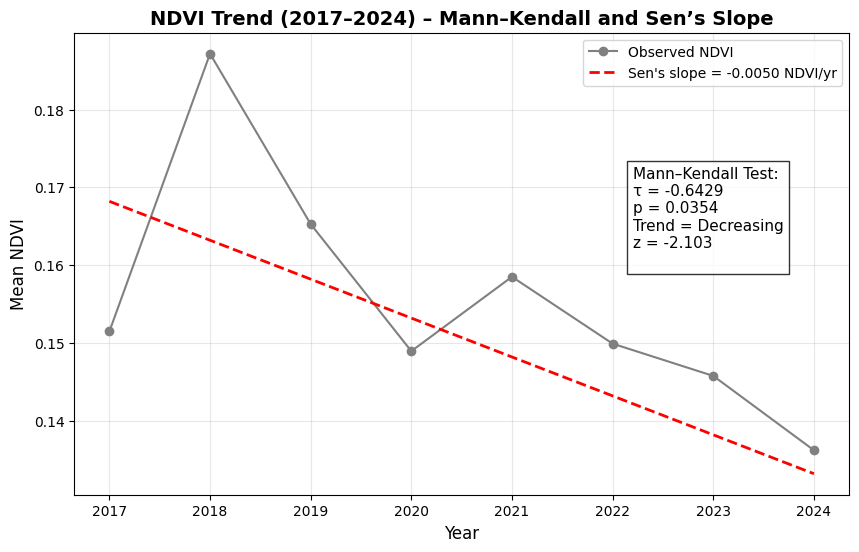

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# NDVI data
data = {
    'year': [2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024],
    'mean_ndvi': [0.151462, 0.187186, 0.165275, 0.148932, 0.158495, 0.149894, 0.145745, 0.136184]
}
df = pd.DataFrame(data)

# Mann–Kendall and Sen’s slope results
tau = -0.6429
p_value = 0.0354
trend = "decreasing"
s = -18.0
z = -2.1032
sen_slope = -0.005005
intercept = 0.1682

# Calculate Sen’s slope line
years = np.array(df['year'])
sen_line = intercept + sen_slope * (years - years[0])

# Color based on trend direction
color = 'green' if sen_slope > 0 else 'red'

# Plot
plt.figure(figsize=(10, 6))
plt.plot(df['year'], df['mean_ndvi'], 'o-', label='Observed NDVI', color='gray')
plt.plot(df['year'], sen_line, '--', color=color, linewidth=2, label=f"Sen's slope = {sen_slope:.4f} NDVI/yr")

# Annotate Mann–Kendall results
text = (
    f"Mann–Kendall Test:\n"
    f"τ = {tau:.4f}\n"
    f"p = {p_value:.4f}\n"
    f"Trend = {trend.capitalize()}\n"
    f"z = {z:.3f}\n"
)
plt.text(2022.2, 0.16, text, fontsize=11, bbox=dict(facecolor='white', alpha=0.8))

# Titles and labels
plt.title("NDVI Trend (2017–2024) – Mann–Kendall and Sen’s Slope", fontsize=14, fontweight='bold')
plt.xlabel("Year", fontsize=12)
plt.ylabel("Mean NDVI", fontsize=12)
plt.grid(alpha=0.3)
plt.legend()

plt.show()


In [ ]:
!pip install --upgrade pymannkendall



# Linear Regression

In [ ]:
def addNDVI(image):
    ndvi = image.normalizedDifference(['B8', 'B4']).rename('NDVI')
    return image.addBands(ndvi)

start = '2019-01-01'
end = '2023-12-31'

s2 = (ee.ImageCollection('COPERNICUS/S2_SR')
      .filterBounds(basin_geom)
      .filterDate(start, end)
      .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 20))
      .map(lambda img: img.divide(10000))
      .map(addNDVI)
     )

first = s2.first()
print(first.bandNames().getInfo())


['B1', 'B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8', 'B8A', 'B9', 'B11', 'B12', 'AOT', 'WVP', 'SCL', 'TCI_R', 'TCI_G', 'TCI_B', 'MSK_CLDPRB', 'MSK_SNWPRB', 'QA10', 'QA20', 'QA60', 'NDVI']


In [ ]:

# --- 3. Build monthly composites that KEEP NDVI ---
def monthlyComposite(year, month):
    start = ee.Date.fromYMD(year, month, 1)
    end = start.advance(1, 'month')
    coll = s2.filterDate(start, end)

    # Keep only images with NDVI
    coll = coll.filter(ee.Filter.listContains('bandNames', 'NDVI'))

    # If the collection is empty, return None
    def safeMean(c):
        size = c.size()
        return ee.Algorithms.If(size.gt(0), c.select('NDVI').mean().set('system:time_start', start.millis()).set('year', year).set('month', month), None)

    return ee.Image(safeMean(coll))
    # return (ndvi_mean
    #         .set('system:time_start', start.millis())
    #         .set('year', year)
    #         .set('month', month))


years = range(2019, 2023)
months = range(1, 13)
monthly_images = [monthlyComposite(y, m) for y in years for m in months]
monthlyCol = ee.ImageCollection(monthly_images)

# Check how many monthly images contain valid NDVI
count = monthlyCol.map(lambda img: img.select('NDVI').gt(0).reduceRegion(
    reducer=ee.Reducer.count(),
    geometry=basin_geom,
    scale=1000,
    maxPixels=1e13
).get('NDVI'))

print('Monthly NDVI pixel counts (first 10):', count.getInfo()[:10])

print('Monthly collection size:', monthlyCol.size().getInfo())
print('Bands in first monthly image:', monthlyCol.first().bandNames().getInfo())

EEException: ImageCollection.fromImages: Attempt to create an ImageCollection with non-image elements.

In [ ]:

# --- 4. Add time band (years since 2019) ---
def addTime(img):
    years = ee.Date(img.get('system:time_start')).difference(ee.Date('2019-01-01'), 'year')
    return img.addBands(ee.Image.constant(years).rename('t'))

with_time = monthlyCol.map(addTime)

print('Bands after adding time:', with_time.first().bandNames().getInfo())

# --- 5. Linear regression NDVI ~ time ---
fit = with_time.select(['t', 'NDVI']).reduce(ee.Reducer.linearFit())

slope = fit.select('scale').clip(basin_geom)

# Get statistics of slope
stats = slope.reduceRegion(
    reducer=ee.Reducer.minMax(),
    geometry=basin_geom,
    scale=500,
    maxPixels=1e13
)
print('NDVI slope range:', stats.getInfo())


# --- 6. Visualize / save ---
Map = geemap.Map(center=[31.6, -7.9], zoom=7)
slope_vis = {'min': -0.05, 'max': 0.05, 'palette': ['red', 'white', 'green']}
Map.addLayer(slope, slope_vis, 'NDVI trend (per year)')
Map.addLayer(basin_geom, {}, 'Tensift boundary')
Map


Bands after adding time: ['NDVI', 't']


Map(center=[31.6, -7.9], controls=(WidgetControl(options=['position', 'transparent_bg'], widget=SearchDataGUI(…

In [ ]:
url = slope.getThumbURL({'min': -0.05, 'max': 0.05, 'palette': ['red', 'white', 'green'], 'region': basin_geom})
print(url)


In [ ]:
import itertools


# Load Sentinel-2
s2 = (ee.ImageCollection('COPERNICUS/S2_SR')
      .filterBounds(basin_geom)
      .filterDate('2019-01-01', '2023-12-31')
      .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 20))
      .map(lambda img: img.divide(10000))
      .map(addNDVI)
     )

# Create list of months as ee.List
years = ee.List.sequence(2019, 2023)
months = ee.List.sequence(1, 12)
month_pairs = years.map(lambda y: months.map(lambda m: ee.List([y, m]))).flatten()

# Function to compute monthly composite safely
def monthlyCompositeTuple(y_m):
    y = ee.Number(ee.List(y_m).get(0))
    m = ee.Number(ee.List(y_m).get(1))
    start = ee.Date.fromYMD(y, m, 1)
    end = start.advance(1, 'month')
    coll = s2.filterDate(start, end).filter(ee.Filter.listContains('bandNames', 'NDVI'))
    return ee.Algorithms.If(
        coll.size().gt(0),
        coll.select('NDVI').mean()
            .set('system:time_start', start.millis())
            .set('year', y)
            .set('month', m),
        None
    )

# Map over months
monthly_images = month_pairs.map(monthlyCompositeTuple)

# Create ImageCollection, skipping None values
monthlyCol = ee.ImageCollection.fromImages(monthly_images).filter(ee.Filter.listContains('bandNames', 'NDVI'))

print('Number of monthly NDVI images:', monthlyCol.size().getInfo())
# ----------------------------
# 6. Analyze NDVI changes
# ----------------------------
# Mean NDVI per year
img_2019 = monthlyCol.filter(ee.Filter.eq('year', 2019)).mean()
img_2023 = monthlyCol.filter(ee.Filter.eq('year', 2023)).mean()

# NDVI change 2019 -> 2023
ndvi_change = img_2023.subtract(img_2019)

# ----------------------------
# 7. Export NDVI change as GeoTIFF
# ----------------------------
task = ee.batch.Export.image.toDrive(
    image=ndvi_change,
    description='NDVI_change_2019_2023',
    folder='NDVI',
    region=basin_geom,
    scale=10,
    crs='EPSG:4326',
    maxPixels=1e13
)
task.start()

EEException: List.get, argument 'list': Invalid type.
Expected type: List<Object>.
Actual type: Float.
Actual value: 2019.0

In [ ]:

# Create an interactive map
Map = geemap.Map(center=[32, -6], zoom=6)


import json
tensift_geojson = basin.to_json()

def add_gdf_with_style(gdf, map_obj, layer_name, style):
    geojson_str = gdf.to_json()
    geojson_dict = json.loads(tensift_geojson)
    map_obj.add_geojson(geojson_dict, layer_name=layer_name, style=style)

# Add the Tensift basin in black outline
add_gdf_with_style(basin, Map, 'Basin', {'color': 'black', 'fillColor':'none', 'weight': 2})

# Add rivers in blue
add_gdf_with_style(oueds_basin, Map, 'Rivers', {'color': 'blue', 'weight': 1})

# Add lakes in light blue
add_gdf_with_style(aquifer_basin, Map, 'Groundwater', {'color': 'purple', 'fillColor':'purple', 'weight': 1})


Map


Map(center=[32, -6], controls=(WidgetControl(options=['position', 'transparent_bg'], widget=SearchDataGUI(chil…

In [ ]:


# Sentinel-2 surface reflectance collection
s2 = ee.ImageCollection("COPERNICUS/S2_SR") \
    .filterBounds(ee_geom) \
    .filterDate('2023-01-01', '2023-12-31') \
    .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 10))

# Compute NDVI
def addNDVI(img):
    ndvi = img.normalizedDifference(['B8', 'B4']).rename('NDVI')
    return img.addBands(ndvi)

s2_ndvi = s2.map(addNDVI)

# Take median NDVI for 2023
median_ndvi = s2_ndvi.select('NDVI').median()

Map.addLayer(median_ndvi, {'min':0, 'max':1, 'palette':['brown','yellow','green']}, 'Median NDVI 2023')
Map



Map(bottom=27000.0, center=[31.59959193922864, -6.984558105468751], controls=(WidgetControl(options=['position…

In [ ]:
# Earliest period (Sentinel-2 SR starts mid-2015, 2017 is safer)
start_old = '2019-12-01'
end_old   = '2019-12-30'

# Recent period
start_recent = '2023-12-01'
end_recent   = '2023-12-30'

def get_s2_collection(start, end):
    return (ee.ImageCollection("COPERNICUS/S2_SR")
            .filterBounds(ee_geom)
            .filterDate(start, end)
            .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 10))
            .map(lambda img: img.divide(10000))  # scale to reflectance
           )

s2_old = get_s2_collection(start_old, end_old)
s2_recent = get_s2_collection(start_recent, end_recent)

median_old = s2_old.median().clip(ee_geom)
median_recent = s2_recent.median().clip(ee_geom)

def add_ndvi(img):
    ndvi = img.normalizedDifference(['B8', 'B4']).rename('NDVI')
    return img.addBands(ndvi)

median_old = add_ndvi(median_old)
median_recent = add_ndvi(median_recent)

ndvi_diff = median_recent.select('NDVI').subtract(median_old.select('NDVI')).rename('NDVI_diff')

Map = geemap.Map(center=[32, -6], zoom=7)

# Old NDVI
Map.addLayer(median_old.select('NDVI'), {'min':0,'max':1,'palette':['brown','yellow','green']}, 'NDVI 2019', shown=False)

# Recent NDVI
Map.addLayer(median_recent.select('NDVI'), {'min':0,'max':1,'palette':['brown','yellow','green']}, 'NDVI 2023',shown=False)

# NDVI difference
Map.addLayer(ndvi_diff, {'min':-0.5, 'max':0.5, 'palette':['red','white','green']}, 'NDVI Change 2019-2023', shown=True)

# Add basin outline and rivers
Map.add_gdf(basin_gdf, layer_name='Basins')
Map.add_gdf(oueds_gdf, layer_name='Rivers')

Map



Map(center=[32, -6], controls=(WidgetControl(options=['position', 'transparent_bg'], widget=SearchDataGUI(chil…

In [ ]:

# ---------------------------
# 4️⃣ Convert NDVI difference to NumPy array (coarse 100 m scale)
# ---------------------------
ndvi_dict = geemap.ee_to_numpy(ndvi_diff, region=ee_geom, scale=500)
ndvi_array = ndvi_dict[0]
lon, lat = ndvi_dict[1], ndvi_dict[2]

# ---------------------------
# 5️⃣ Plot with Matplotlib
# ---------------------------
plt.figure(figsize=(10,8))

# NDVI difference
plt.pcolormesh(lon, lat, ndvi_array, cmap='RdYlGn', vmin=-0.5, vmax=0.5)
plt.colorbar(label='NDVI Change (2023 - 2017)')

# Overlay basin boundary
basin.boundary.plot(edgecolor='black', linewidth=1, ax=plt.gca())

# Overlay rivers and lakes (optional)
oueds_gdf.plot(ax=plt.gca(), color='blue', linewidth=0.7)
nappes_gdf.plot(ax=plt.gca(), color='cyan', linewidth=0.7)

plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.title('NDVI Change in Tensift Basin')
plt.tight_layout()

# ---------------------------
# 6️⃣ Save as PNG
# ---------------------------
plt.savefig('/content/Tensift_NDVI_change.png', dpi=300)
plt.show()

Exception: Total request size (60480000 bytes) must be less than or equal to 50331648 bytes.

In [ ]:
# ---------------------------
# 1️⃣ Imports
# ---------------------------
import ee
import geemap
import numpy as np
import matplotlib.pyplot as plt
import imageio
from shapely.geometry import mapping


# ---------------------------
# 2️⃣ Define basin
# ---------------------------
basin = basin_gdf[basin_gdf['NomBassin']=='Tensift']
geom_json = mapping(basin.geometry.iloc[0])
ee_geom = ee.Geometry(geom_json)

# ---------------------------
# 3️⃣ Helper to get NDVI for a single date
# ---------------------------
def get_ndvi_for_date(date):
    s2 = (ee.ImageCollection("COPERNICUS/S2_SR")
          .filterBounds(ee_geom)
          .filterDate(date, ee.Date(date).advance(1, 'day'))
          .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 20))
          .map(lambda img: img.divide(10000))
         )
    median = s2.median().clip(ee_geom)
    ndvi = median.normalizedDifference(['B8','B4']).rename('NDVI')
    return ndvi

# ---------------------------
# 4️⃣ Define date range
# ---------------------------
start_date = ee.Date('2019-06-01')
end_date = ee.Date('2023-12-30')  # for example, one week daily
dates = [start_date.advance(i, 'day') for i in range(end_date.difference(start_date,'day').getInfo())]

# ---------------------------
# 5️⃣ Loop through dates and save frames
# ---------------------------
frames = []

for d in dates:
    ndvi_img = get_ndvi_for_date(d)
    arr_dict = geemap.ee_to_numpy(ndvi_img, region=ee_geom, scale=100)
    ndvi_array = arr_dict[0]
    lon, lat = arr_dict[1], arr_dict[2]

    # Plot
    fig, ax = plt.subplots(figsize=(6,6))
    c = ax.pcolormesh(lon, lat, ndvi_array, cmap='RdYlGn', vmin=0, vmax=1)
    basin.boundary.plot(edgecolor='black', linewidth=1, ax=ax)
    plt.title(d.format('YYYY-MM-dd').getInfo())
    plt.axis('off')

    # Save to PNG buffer
    fig.canvas.draw()
    img = np.frombuffer(fig.canvas.tostring_rgb(), dtype=np.uint8)
    img = img.reshape(fig.canvas.get_width_height()[::-1] + (3,))
    frames.append(img)
    plt.close(fig)

# ---------------------------
# 6️⃣ Save as GIF
# ---------------------------
imageio.mimsave('/content/Tensift_NDVI_timelapse.gif', frames, duration=0.5)


Exception: Image.normalizedDifference: No band named 'B8'. Available band names: [].

In [ ]:
geom_json = mapping(basin.geometry.iloc[0])  # convert shapely to GeoJSON dict
ee_geom = ee.Geometry(geom_json)

chirps = ee.ImageCollection("UCSB-CHG/CHIRPS/DAILY") \
    .filterBounds(ee_geom) \
    .filterDate('2023-01-01', '2023-12-31')

rain_2023 = chirps.select('precipitation').sum()

Map = geemap.Map(center=[32, -6], zoom=7)

Map.addLayer(rain_2023, {'min':0, 'max':1000, 'palette':['white','blue']}, 'Rainfall 2023')

# Add basin outline and rivers
Map.add_gdf(basin, layer_name='Basins', shown=True)
Map.add_gdf(oueds_basin, layer_name='Rivers', shown=True)

Map


In [ ]:
from shapely.geometry import mapping, MultiPolygon

from shapely.geometry import mapping

# --- For just the tensift basin ---
geom_json = mapping(basin.geometry.iloc[0])  # convert shapely to GeoJSON dict
basin_geom = ee.Geometry(geom_json)

# --- Combine all basin geometries into a single MultiPolygon ---
# all_polygons = MultiPolygon([geom for geom in basin_gdf.geometry])
# geom_json = mapping(all_polygons)
# ee_geom = ee.Geometry(geom_json)